# QE-XAI: Hybrid CNN–VQC with Grad-CAM for Alzheimer's Disease Detection (CN vs AD) — OASIS-1

**Data:** Kaggle *OASIS Alzheimer's Detection* (`ninadaithal/imagesoasis`) — 2D axial slices of the OASIS-1 cross-sectional T1-weighted MRI study (Marcus et al., 2007), with the OASIS-1 demographics table (`jboysen/mri-and-alzheimers`, file `oasis_cross-sectional.csv`) for age-matching.

This notebook implements the framework described in the revised abstract, end to end:

| Stage | What the notebook does | Manuscript section / reviewer comment |
|---|---|---|
| 1. MRI pre-processing | entropy-based slice selection, N4 bias-field correction, 2D skull stripping + brain crop, Gaussian denoising, CLAHE, z-score intensity normalisation, 2.5D input | Sec. 3.2 |
| 2. CNN feature learning | CNN trained for CN vs AD; 4096-d penultimate features extracted | Sec. 3.3, R1-6, R3-10 |
| 3. PCA | fitted on training features only: 4096 → 64 components; leading *n* components → *n* qubits | Sec. 3.4, R2-2, R3-2 |
| 4. Quantum encoding + VQC | ZZ feature map (Fig. 7) or angle encoding + RealAmplitudes ansatz; ⟨Z⟩ on every qubit | Sec. 3.5–3.6, R1-6 |
| 5. Hybrid CNN–VQC | H = [F_CNN ⊕ F_VQC] → softmax (Eq. 14–15); VQC + softmax trained jointly, CNN frozen | Sec. 3.7, R2-3 |
| 6. Evaluation | subject-level stratified 10-fold CV, mean ± SD, pooled 95% CI, empirical ROC curves, McNemar, DeLong, paired t-tests | R1-5, R1-7, R3-3, R3-4 |
| 7. Explainability | Grad-CAM on the CNN **and** Grad-CAM back-propagated through PCA + VQC (hybrid decision); agreement between the two | R1-8, R3-6 |
| 8. Extra analyses | qubit sweep n = 4–8 on validation data (Table 8); classical ablations; shot-noise analysis with Qiskit; Qiskit cross-check | R1-3, R1-4, R3-1, R3-8, R3-11 |
| 9. Machine-learning benchmark | LD-RNN pipeline (frozen DenseNet121 + ResNet101 features → PCA → LSTM; Thatere & Reddy) and 16 further classifiers (logistic regression, LDA, naive Bayes, k-NN, decision tree, SVMs, random forest, extra trees, AdaBoost, gradient boosting, XGBoost, LightGBM, MLP, quantum heads, ensemble) on the same subject-level folds (Table 9, Figure 13); leakage demonstration (Table 10) | R1-5, R3-4 |
| 10. More explanation methods | saliency and occlusion maps for the hybrid model next to Grad-CAM (Figure 14) | R1-8, R3-6 |

**How to run on Kaggle**
1. *Add Data* → add **two** datasets:
   - `ninadaithal/imagesoasis` (*OASIS Alzheimer's Detection*), which contains the images;
   - `jboysen/mri-and-alzheimers` (*MRI and Alzheimers*), which contains `oasis_cross-sectional.csv` with age, sex, MMSE and CDR per subject.
2. *Settings* → **Accelerator: GPU** (the CNN trains ~10× faster) and **Internet: On** (to install Qiskit; if the *MRI and Alzheimers* dataset is not attached, the notebook downloads the official OASIS-1 demographics spreadsheet instead).
3. Check the **Configuration** cell (label mapping, images per class), then *Run All*.
4. Everything is written to `/kaggle/working/qexai_outputs/` and zipped as `qexai_outputs.zip`.
5. Run time on a Kaggle T4: about 2.5–3.5 h in total; the machine-learning benchmark (Section 10b) adds about 1 h of this. Set `RUN_ML_BENCHMARK = False` to skip it.

**Switches added in this version (Configuration cell)**
- `PREPROC_PRESET = "paper"` uses the LD-RNN study's pre-processing (field-of-view crop, CLAHE 8×8 with clip 3.7, scaling to [0, 1]; no N4, no skull stripping) instead of this paper's pipeline.
- `ML_FEATURE_SETS` adds feature sets, e.g. `{"dual_cnn": ("densenet121", "resnet101"), "vit": ("vit_b_16",)}`.
- `ML_MODELS` / `ENSEMBLE_MEMBERS` choose the classifiers. XGBoost and LightGBM are pre-installed on Kaggle; elsewhere they are skipped automatically if missing.
- `LEAKAGE_DEMO = True` adds Table 10, which re-runs three models with the LD-RNN study's random 80:20 *image* split. This is a demonstration of leakage, not a result.

**Principles built into the code**
- Nothing is hard-coded: every number, figure and sentence in the auto-generated Results section is computed from this run.
- The test fold is never used for training, early stopping, PCA fitting, scaling or choosing the number of qubits.
- No **subject** appears in both training and test data. OASIS has ~61 slices × 3–4 repeated scans per person, so an image-level split would leak; this is checked with an assertion.
- Controls are **age-matched** to the AD group, because OASIS-1 controls include adults aged 18–59 while all its dementia cases are over 60.
- The quantum circuits are built in **Qiskit**. For speed and exact gradients, they are simulated with an exact state-vector simulator written in PyTorch, which is **verified against Qiskit's `Statevector`** before training and on the final test set.

## 1. Installation
Kaggle images already include PyTorch, scikit-learn and OpenCV. This cell installs only what is missing (Qiskit, the circuit-drawing helper, python-docx, openpyxl and SimpleITK for N4 bias-field correction). It **pins NumPy and SciPy to the versions already in the image**, so pip picks a Qiskit release compatible with them instead of upgrading NumPy underneath the other libraries.

**Use this notebook on its own.** Run it as a separate Kaggle notebook (*File → Import Notebook*), not pasted into another notebook that loads TensorFlow/Keras: TensorFlow reserves the whole GPU.

In [9]:
import importlib.util, importlib.metadata as md, subprocess, sys


def _version(dist):
    try:
        return md.version(dist)
    except md.PackageNotFoundError:
        return None


def _accepts_installed_numpy(dist):
    """Does `dist`'s declared NumPy requirement accept the NumPy installed here?"""
    try:
        from packaging.requirements import Requirement
        for r in md.requires(dist) or []:
            req = Requirement(r)
            if req.name.lower() == "numpy" and req.marker is None:
                return req.specifier.contains(md.version("numpy"), prereleases=True)
    except Exception:
        pass
    return True


pins = [f"{d}=={_version(d)}" for d in ("numpy", "scipy") if _version(d)]   # never upgrade these
need = [spec for module, spec in {"pylatexenc": "pylatexenc", "docx": "python-docx", "openpyxl": "openpyxl",
                                  "SimpleITK": "SimpleITK"}.items()
        if importlib.util.find_spec(module) is None]
if _version("qiskit") is not None and not _accepts_installed_numpy("qiskit"):
    print(f"Installed Qiskit {_version('qiskit')} needs a different NumPy than {_version('numpy')} -> replacing it")
    subprocess.check_call([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "qiskit"])
if _version("qiskit") is None:
    need.append("qiskit>=1.3,<3")
if need:
    print("Installing:", need, "| keeping:", pins)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *need, *pins])

# The libraries must still import with the NumPy on disk (an earlier, unpinned install may have upgraded it)
probe = subprocess.run([sys.executable, "-c", "import numpy, scipy, pandas, sklearn, cv2, matplotlib, qiskit"],
                       capture_output=True, text=True)
if probe.returncode != 0:
    raise SystemExit("The Python environment is inconsistent (usually: NumPy was upgraded by an earlier pip install).\n"
                     "Kaggle: menu Run -> Factory reset, then Run All.\n\n" + probe.stderr[-1500:])
loaded = {m for m in ("numpy", "qiskit") if m in sys.modules}
print(f"numpy {_version('numpy')} | scipy {_version('scipy')} | qiskit {_version('qiskit')}")
if loaded:
    print(f"NOTE: {sorted(loaded)} already loaded in this kernel. If anything was installed above, restart the kernel "
          "(Run -> Restart & clear cell outputs) and Run All.")

numpy 2.1.3 | scipy 1.16.3 | qiskit 2.5.2
NOTE: ['numpy', 'qiskit'] already loaded in this kernel. If anything was installed above, restart the kernel (Run -> Restart & clear cell outputs) and Run All.


## 2. Configuration
Edit this cell only. The defaults are the current (run 3) settings: subject-level stratified **10-fold** CV, entropy-based slice selection, N4 + skull stripping + brain crop + Gaussian + CLAHE + z-score pre-processing, 2.5D input, VGG16-BN with frozen early blocks, label smoothing, strong augmentation and checkpoint selection on the validation AUC; then 4096-d features, 64 PCA components, 4 qubits, ZZ feature map (2 repetitions) and a 2-layer RealAmplitudes ansatz. Comments give the run-2 value of each changed option, so earlier runs can be reproduced as ablations.

In [10]:
import os

# ---- data -------------------------------------------------------------------------------------
DATA_ROOT = os.environ.get("QEXAI_DATA_ROOT", "/kaggle/input")
OUT_DIR = "/kaggle/working/qexai_outputs" if os.path.isdir("/kaggle/working") else os.path.abspath("qexai_outputs")
DATASET_NAME = ("the OASIS-1 cross-sectional MRI data (Marcus et al., 2007) in the 2D-slice version distributed on "
                "Kaggle as “OASIS Alzheimer's Detection”")
DATASET_CITATION = "[cite: Marcus et al., 2007; https://www.kaggle.com/datasets/ninadaithal/imagesoasis]"

# Labels follow the Clinical Dementia Rating (CDR) encoded in the folder names:
# Non Demented = 0, Very mild Dementia = 0.5, Mild Dementia = 1, Moderate Dementia = 2.
AD_MIN_CDR = 0.5          # AD = CDR >= 0.5: very mild to moderate AD, the OASIS-1 definition (100 subjects).
                          # Use 1.0 for mild + moderate only (30 subjects); CDR 0.5 subjects are then excluded.
CN_MIN_AGE = 60           # age-matching: keep CN subjects aged >= 60 (all OASIS-1 dementia cases are over 60). None = no filter
REQUIRE_DEMOGRAPHICS = True   # stop if the OASIS-1 demographics table cannot be found or downloaded
# Where the OASIS-1 demographics table comes from (first that works):
#  1) DEMOGRAPHICS_FILE: explicit path to oasis_cross-sectional.csv / .xlsx that you uploaded, e.g.
#     "/kaggle/input/oasis-demographics/oasis_cross-sectional.xlsx"
#  2) any matching .csv/.xlsx attached under DATA_ROOT (e.g. Kaggle dataset jboysen/mri-and-alzheimers)
#  3) download of the official OASIS-1 spreadsheet (Kaggle: Settings -> Internet ON)
DEMOGRAPHICS_FILE = None
DEMOGRAPHICS_URLS = [
    "https://bpb-us-e2.wpmucdn.com/sites.wustl.edu/dist/6/4383/files/2024/04/oasis_cross-sectional-5708aa0a98d82080.xlsx",
    "https://sites.wustl.edu/oasisbrains/files/2024/04/oasis_cross-sectional-5708aa0a98d82080.xlsx",
]
MAX_PER_CLASS = 1800      # run 1 used 900 (~11 slices/subject); 1800 gives ~22 slices/subject (more training variety)
SLICES_PER_SUBJECT = None # None = MAX_PER_CLASS / number of subjects; or a fixed number per subject
SLICE_RANGE = (100, 160)  # axial slice indices to sample from (the Kaggle set contains 100-160)
SLICE_SELECTION = "entropy"   # "entropy": the most informative slices of each scan (highest grey-level entropy; Hon & Khan 2017)
                              # "even": evenly spaced over SLICE_RANGE (runs 1-2) | "central": slices nearest the middle
INPUT_MODE = "2.5d"       # "2.5d": the slice and its neighbours at -SLICE_OFFSET / +SLICE_OFFSET as 3 channels
                          # (gives the pre-trained network depth context instead of 3 copies of one slice); "2d": run 1
SLICE_OFFSET = 2

# ---- pre-processing (Sec. 3.2) ---------------------------------------------------------------------
BIAS_CORRECTION = True    # N4 bias-field correction (SimpleITK); field estimated on the centre slice, applied to the stack
SKULL_STRIP = True        # 2D brain extraction (threshold + erosion + central component + dilation); falls back to the
                          # head mask when the result is implausible, and the fallback rate is reported
BRAIN_CROP = True         # crop the stack to the brain's bounding box (needs SKULL_STRIP), so the brain fills the input
DENOISE = "gaussian"      # "gaussian" (manuscript Eq. 3) | "median" (3x3, run 2) | "none"
GAUSS_SIGMA = 0.8         # pixels at IMG_SIZE
CLAHE_CLIP = 2.0
INTENSITY_NORM = "zscore" # "zscore" within the brain mask (manuscript Eq. 4), clipped to +-3 SD | "minmax" (run 2)
PREPROC_PRESET = "qexai"  # "qexai": the settings above | "paper": pre-processing of the LD-RNN study (Thatere & Reddy):
                          # Otsu field-of-view crop, CLAHE (8x8, clip 3.7), [0, 1] scaling - no N4, no skull stripping
if PREPROC_PRESET == "paper":
    BIAS_CORRECTION, SKULL_STRIP, BRAIN_CROP, DENOISE, CLAHE_CLIP, INTENSITY_NORM = False, False, False, "none", 3.7, "minmax"

# ---- evaluation ----------------------------------------------------------------------------------
SEED = 42
N_FOLDS = 10         # stratified, subject-level K-fold cross-validation (each image is tested exactly once); run 2 used 5
VAL_FRAC = 0.15      # share of each training fold held out (by group) for early stopping / model selection
N_BOOTSTRAP = 1000   # group-level bootstrap resamples for 95% CIs

# ---- CNN (Sec. 3.3) -------------------------------------------------------------------------------
IMG_SIZE = 224
# Feature extractor. "vgg16_bn": VGG16 (with BatchNorm) pre-trained on ImageNet and fine-tuned; its fc7 layer gives the
# 4096-d feature vector described in the manuscript. "custom": 5-block CNN trained from scratch — in run 1 (12 Oct 2026)
# it did not converge (training accuracy 52–58%), so it is kept only as an ablation.
BACKBONE = "vgg16_bn"            # "vgg16_bn" | "vgg16" | "custom"
PRETRAINED = os.environ.get("QEXAI_PRETRAINED", "1") == "1"   # ImageNet weights (~530 MB download, Internet ON)
CNN_WIDTHS = (32, 64, 128, 256, 256)   # "custom" only: 5 conv blocks of 2 × (3×3 conv + BN + ReLU) + 2×2 max-pool
FEATURE_DIM = 4096
CNN_DROPOUT = 0.5
BATCH_SIZE = 16
CNN_LR = 1e-4 if BACKBONE != "custom" else 1e-3   # new/fully connected layers
CNN_LR_BACKBONE = 1e-5    # pre-trained convolutional layers: 10x smaller, so ImageNet features are adapted, not erased
CNN_WEIGHT_DECAY = 1e-2         # AdamW default range; run 2 used 1e-4
CNN_EPOCHS = 25
CNN_MIN_EPOCHS = 6               # early stopping cannot stop training before this epoch
CNN_PATIENCE = 6                 # epochs without improvement of the selection metric before stopping
USE_AMP = True                   # mixed precision on GPU (faster, less memory)
# Regularisation against the overfitting seen in run 2 (training accuracy ~90%, validation loss lowest after 1-4 epochs):
FREEZE_BLOCKS = 3                # keep the first N of 5 pre-trained VGG conv blocks fixed (generic edge/texture filters)
LABEL_SMOOTHING = 0.1            # softens the 0/1 targets -> less over-confident CNN
SELECT_BY = "val_auc"            # checkpoint + early stopping on the subject-level validation AUC | "val_loss" (run 2)
AUGMENT = "strong"               # "strong": flip, affine (rotation, shift, scale, shear), gamma/contrast/brightness,
                                 # Gaussian noise, random erasing | "basic": flip + small affine (run 2)

# ---- PCA + quantum part (Sec. 3.4–3.7) ------------------------------------------------------------------
N_PCA = 64
N_QUBITS = 4                 # leading PCA components encoded on N_QUBITS qubits (one component per qubit)
ENCODING = "zz"              # "zz" = ZZ feature map (Fig. 7) | "angle" = RY(x_i) angle encoding
FM_REPS = 2                  # feature-map repetitions (ZZ only)
ANSATZ_REPS = 2              # RealAmplitudes layers
ENTANGLEMENT = "linear"      # "linear" | "full"
Q_LR = 0.03
Q_EPOCHS = 80
Q_PATIENCE = 10
Q_BATCH = 32
Q_RESTARTS = 3               # random initialisations per quantum/linear head; the one with the lowest validation loss is kept

# ---- machine-learning benchmark (Sec. 10b): LD-RNN pipeline (Thatere & Reddy) + classical classifiers (Alam et al. 2026) ----
RUN_ML_BENCHMARK = True
ML_FEATURE_SETS = {"dual_cnn": ("densenet121", "resnet101")}   # frozen ImageNet backbones; features are concatenated.
                  # add "vit": ("vit_b_16",) to also benchmark Vision-Transformer features (~330 MB download)
ML_PCA = 1200             # PCA components for the benchmark classifiers (LD-RNN study: 1200), fitted on training subjects
ML_MODELS = ["logreg", "lda", "gnb", "knn", "dtree", "svm_linear", "svm_rbf", "rf", "extra_trees", "adaboost", "hgb",
             "xgboost", "lightgbm", "mlp", "ldrnn", "vqc_dual", "hybrid_dual", "ensemble"]
ENSEMBLE_MEMBERS = ["logreg", "svm_rbf", "rf", "lightgbm", "ldrnn"]   # soft voting; chosen before seeing any result
ML_TREES = 500            # trees for random forest / extra trees
LDRNN_EPOCHS, LDRNN_BATCH, LDRNN_LR, LDRNN_PATIENCE = 70, 16, 1e-3, 10   # LD-RNN study: 70 epochs, batch 16, Adam 1e-3
LEAKAGE_DEMO = True       # re-run 3 classifiers with the LD-RNN study's protocol (random image split) to show the inflation
RUN_EXTRA_XAI = True      # saliency and occlusion maps for the hybrid model, compared with Grad-CAM (Sec. 12b)

# ---- extra analyses -------------------------------------------------------------------------------
RUN_QUBIT_SWEEP = True
SWEEP_QUBITS = [4, 5, 6, 7, 8]
SHOTS_LIST = [128, 1024, 8192]
N_SHOT_SEEDS = 5
N_GRADCAM_EXAMPLES = 3       # per class in Figure 12

# ---- values printed in the 24-Jun-2026 manuscript (used ONLY in the verification report) ----------------
REPORTED = {"cnn":    dict(accuracy=97.0, precision=97.0, recall=97.0, f1=97.0, auc=0.98),
            "vqc":    dict(accuracy=95.0, precision=95.0, recall=94.0, f1=94.5, auc=0.96),
            "hybrid": dict(accuracy=96.0, precision=96.0, recall=95.0, f1=95.5, auc=0.97)}

# ---- smoke test (never report these numbers) ---------------------------------------------------------
FAST_DEV_RUN = os.environ.get("QEXAI_FAST_DEV_RUN", "0") == "1"
if FAST_DEV_RUN:
    IMG_SIZE, MAX_PER_CLASS, N_FOLDS, CNN_EPOCHS, CNN_MIN_EPOCHS, Q_EPOCHS = 64, 120, 3, 3, 1, 15
    SWEEP_QUBITS, SHOTS_LIST, N_SHOT_SEEDS, N_BOOTSTRAP = [4, 5], [128, 1024], 2, 100
    ML_TREES, LDRNN_EPOCHS = 30, 4
    print("FAST_DEV_RUN = True — smoke test only. DO NOT use these outputs in the manuscript.")
IN_CHANNELS = 3 if INPUT_MODE == "2.5d" else 1

In [11]:
import contextlib, copy, json, math, os, re, sys, time, random, hashlib, platform, warnings, zipfile, datetime
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as IPImage
from scipy import stats
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

os.environ.setdefault("TF_FORCE_GPU_ALLOW_GROWTH", "true")      # in case TensorFlow is imported later
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T

import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.primitives import StatevectorSampler

warnings.filterwarnings("ignore", category=UserWarning)

# ---- environment checks (version mismatch, Qiskit/NumPy compatibility, free GPU memory) ----
import importlib.metadata as _md
if np.__version__ != _md.version("numpy"):
    raise SystemExit(f"This kernel runs NumPy {np.__version__}, but NumPy {_md.version('numpy')} is installed on disk. "
                     "Restart the kernel (Run -> Restart & clear cell outputs) and Run All; if it persists, Run -> Factory reset.")
try:
    _qc = QuantumCircuit(1); _qc.h(0); Statevector(_qc)
except Exception as e:
    raise SystemExit(f"Qiskit {qiskit.__version__} does not work with NumPy {np.__version__} ({e}). "
                     "Run -> Factory reset, then Run All (the installation cell pins compatible versions).")
if torch.cuda.is_available():
    free_b, total_b = torch.cuda.mem_get_info()
    print(f"GPU memory free: {free_b / 2**30:.1f} of {total_b / 2**30:.1f} GB")
    if free_b < 1.5 * 2**30:
        holders = [m for m in ("tensorflow", "keras", "jax") if m in sys.modules]
        raise SystemExit(
            f"Only {free_b / 2**20:.0f} MB of GPU memory is free: another library or an earlier run is holding it"
            + (f" (loaded here: {holders})" if holders else "") + ".\n"
            "Fix: Run -> Restart & clear cell outputs, then Run All. Run this notebook on its own — do not mix it with "
            "TensorFlow/Keras cells from another notebook in the same session.")
for sub in ("figures", "tables", "models"):
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
Q_DEVICE = torch.device("cpu")   # the small quantum/linear heads train faster on CPU (no GPU kernel-launch overhead)
NUM_WORKERS = 2 if (os.cpu_count() or 1) > 2 else 0


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
ENV = {"python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
       "qiskit": qiskit.__version__, "scikit-learn": sklearn.__version__, "opencv": cv2.__version__,
       "numpy": np.__version__,
       "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else f"CPU ({os.cpu_count()} cores)"}
print(json.dumps(ENV, indent=1))

# Figure style — categorical slots from a colour-blind-validated palette (first three slots validate all-pairs)
COLORS = {"cnn": "#2a78d6", "vqc": "#eb6834", "hybrid": "#1baf7a", "lin_n": "#8a8984", "lin64": "#52514e"}
CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834"}
NAMES = {"cnn": "CNN", "vqc": "VQC", "hybrid": "Hybrid CNN–VQC",
         "lin_n": f"Linear on {N_QUBITS} PCA comps (classical ablation)",
         "lin64": f"Linear on {N_PCA} PCA comps (classical ablation)"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
                     "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "legend.frameon": False, "figure.dpi": 100})


def savefig(fig, name):
    path = os.path.join(OUT_DIR, "figures", f"{name}.png")
    fig.savefig(path, dpi=300, bbox_inches="tight")
    fig.savefig(path[:-4] + ".pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return path

GPU memory free: 14.5 of 14.6 GB
{
 "python": "3.13.15",
 "torch": "2.11.0+cu128",
 "torchvision": "0.26.0+cu128",
 "qiskit": "2.5.2",
 "scikit-learn": "1.6.1",
 "opencv": "4.14.0",
 "numpy": "2.1.3",
 "device": "Tesla T4"
}


## 3. OASIS-1 data: labels, age-matching and slice selection (Sec. 3.1)
Each Kaggle image is one axial slice (indices 100–160) of a T1-weighted OASIS-1 scan. The folder gives the CDR, and the filename gives subject, session, repeated acquisition and slice, e.g. `OAS1_0028_MR1_mpr-1_100.jpg`.

Three properties of OASIS-1 determine how the data must be used:
1. **Many near-identical images per person.** Each subject has ~61 slices × 3–4 repeated T1 acquisitions (`mpr-1…4`), and 20 controls have a second session (`MR2`). An image-level split would place copies of the same brain in training and test (Reviewer 3, Comment 3). **All splits here are by subject.**
2. **Few dementia subjects.** OASIS-1 has 100 subjects with dementia: 70 at CDR 0.5, 28 at CDR 1 and 2 at CDR 2. AD is defined as CDR ≥ `AD_MIN_CDR`; the default of 0.5 is OASIS-1's own definition of very mild to moderate AD.
3. **Age confound.** All dementia subjects are over 60, but most OASIS-1 controls are younger. Without matching, a model could learn age rather than AD. **Controls are restricted to age ≥ `CN_MIN_AGE`** using `oasis_cross-sectional.csv`, and Table 1 reports age, sex and MMSE.

To spread the image budget (`MAX_PER_CLASS`) over as many people as possible, each subject contributes one session (MR1) and one T1 acquisition (the lowest `mpr` number), from which evenly spaced slices are taken. With `INPUT_MODE = "2.5d"`, each selected slice is paired with the slices `SLICE_OFFSET` positions below and above it from the same scan.

In [12]:
IMG_EXT = {".jpg", ".jpeg", ".png"}
_norm = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())
CDR_BY_FOLDER = {"nondemented": 0.0, "verymilddementia": 0.5, "verymilddemented": 0.5, "milddementia": 1.0,
                 "milddemented": 1.0, "moderatedementia": 2.0, "moderatedemented": 2.0}
FNAME_RE = re.compile(r"(OAS1_\d{4})_(MR\d)_mpr-(\d+)_(\d+)", re.IGNORECASE)

rows, unparsed, csv_files = [], [], []
for root, dirs, files in os.walk(DATA_ROOT, followlinks=True):   # Kaggle may mount inputs as symlinks
    dirs.sort()
    for f in sorted(files):
        ext = Path(f).suffix.lower()
        if ext in (".csv", ".xlsx", ".xls"):
            csv_files.append(os.path.join(root, f))
            continue
        if ext not in IMG_EXT:
            continue
        folder = Path(root).name
        cdr = CDR_BY_FOLDER.get(_norm(folder))
        if cdr is None:
            continue
        m = FNAME_RE.search(f)
        if m is None:
            unparsed.append(os.path.join(root, f))
            continue
        p = os.path.join(root, f)
        rows.append(dict(path=p, rel=os.path.relpath(p, DATA_ROOT), folder=folder, cdr_folder=cdr,
                         subject=m.group(1).upper(), session=m.group(2).upper(), mpr=int(m.group(3)), slice=int(m.group(4))))
df_all = pd.DataFrame(rows)
if df_all.empty:
    raise SystemExit(f"No OASIS images found under {DATA_ROOT}. Attach 'ninadaithal/imagesoasis' with 'Add Data'.")
if unparsed:
    print(f"{len(unparsed)} images in class folders do not follow the OASIS filename pattern and were skipped, e.g.:",
          *unparsed[:3], sep="\n  ")
n_raw = len(df_all)
df_all = df_all.drop_duplicates(["subject", "session", "mpr", "slice"]).reset_index(drop=True)   # dataset attached twice etc.
print(f"Images found: {n_raw:,} ({n_raw - len(df_all):,} duplicate copies removed)")
INVENTORY = (df_all.assign(scan=df_all.subject + df_all.session + df_all.mpr.astype(str))
             .groupby(["folder", "cdr_folder"])
             .agg(images=("path", "size"), subjects=("subject", "nunique"), scans=("scan", "nunique"),
                  first_slice=("slice", "min"), last_slice=("slice", "max")).reset_index().sort_values("cdr_folder"))
display(INVENTORY)
INVENTORY.to_csv(os.path.join(OUT_DIR, "tables", "data_inventory.csv"), index=False)
_probe = cv2.imread(df_all.path.iloc[0], cv2.IMREAD_UNCHANGED)
print("Example file:", df_all.rel.iloc[0], "| stored size (H, W[, C]):", None if _probe is None else _probe.shape)

# a subject must sit in exactly one CDR folder
n_folders = df_all.groupby("subject").folder.nunique()
if (n_folders > 1).any():
    bad = n_folders[n_folders > 1].index
    print(f"Dropping {len(bad)} subjects that appear in more than one CDR folder:", list(bad)[:10])
    df_all = df_all[~df_all.subject.isin(bad)].reset_index(drop=True)

# ---- OASIS-1 demographics (oasis_cross-sectional.csv / .xlsx) ----
def read_oasis_demographics(path, log=None):
    """Return the OASIS-1 table indexed by subject (MR1 rows), or None if the file is not that table."""
    log = log if log is not None else []
    try:
        if str(path).lower().endswith((".xlsx", ".xls")):
            raw = pd.read_excel(path, header=None)
            hdr = next((i for i in range(min(15, len(raw))) if "ID" in [str(v).strip() for v in raw.iloc[i]]), None)
            if hdr is None:
                log.append(f"{path}: no 'ID' header row"); return None
            d = pd.read_excel(path, header=hdr)
        else:
            d = pd.read_csv(path, encoding="utf-8-sig", sep=None, engine="python")
    except Exception as e:
        log.append(f"{path}: could not be read ({type(e).__name__}: {e})"); return None
    d.columns = [str(c).replace("\ufeff", "").strip() for c in d.columns]
    if not {"ID", "Age", "CDR"} <= set(d.columns):
        log.append(f"{path}: columns {list(d.columns)[:8]} (needs ID, Age, CDR)"); return None
    ids = d.ID.astype(str).str.strip().str.upper()
    if not ids.str.startswith("OAS1_").any():
        log.append(f"{path}: IDs are not OASIS-1 (e.g. {ids.iloc[0] if len(ids) else 'empty'})"); return None
    d = d[ids.str.endswith("_MR1")].copy()
    d["subject"] = d.ID.astype(str).str.strip().str[:9].str.upper()
    for c in ("Age", "MMSE", "CDR", "Educ", "SES", "eTIV", "nWBV"):
        if c in d:
            d[c] = pd.to_numeric(d[c], errors="coerce")
    if "M/F" in d:
        d["M/F"] = d["M/F"].astype(str).str.strip().str.upper()
    return d.drop_duplicates("subject").set_index("subject")


def download(url, dst):
    """Browser-like download; returns (ok, message). Accepts only an Excel (zip) or CSV payload."""
    headers = {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124 Safari/537.36",
               "Accept": "application/vnd.openxmlformats-officedocument.spreadsheetml.sheet,text/csv,*/*"}
    try:
        try:
            import requests
            r = requests.get(url, headers=headers, timeout=60, allow_redirects=True)
            status, data = r.status_code, r.content
        except ImportError:
            import urllib.request
            with urllib.request.urlopen(urllib.request.Request(url, headers=headers), timeout=60) as r:
                status, data = r.status, r.read()
    except Exception as e:
        return False, f"{type(e).__name__}: {str(e)[:160]}"
    if status != 200:
        return False, f"HTTP {status}"
    if not (data[:2] == b"PK" or data[:3] == b"ID," or data[:6] == b"\xef\xbb\xbfID,"):
        return False, f"unexpected content ({len(data)} bytes, starts {data[:40]!r})"
    with open(dst, "wb") as fh:
        fh.write(data)
    return True, f"{len(data):,} bytes"


DEMO, DEMO_PATH, demo_log = None, None, []
candidates = ([DEMOGRAPHICS_FILE] if DEMOGRAPHICS_FILE else []) + sorted(csv_files)
for cp in candidates:                               # 1) + 2) files you attached / uploaded
    DEMO = read_oasis_demographics(cp, demo_log)
    if DEMO is not None:
        DEMO_PATH = cp
        break
if DEMO is None:                                    # 3) official OASIS-1 spreadsheet (Internet ON)
    for url in DEMOGRAPHICS_URLS or []:
        dst = os.path.join(OUT_DIR, "oasis_cross-sectional" + (".xlsx" if url.lower().endswith(".xlsx") else ".csv"))
        ok_dl, msg = download(url, dst)
        demo_log.append(f"download {url[:70]}... -> {msg}")
        if ok_dl:
            DEMO = read_oasis_demographics(dst, demo_log)
            if DEMO is not None:
                DEMO_PATH = url + " (downloaded)"
                break
if DEMO is None:
    print("Demographics search log:", *(demo_log or ["no .csv/.xlsx files under DATA_ROOT and no download URL"]), sep="\n  ")
if DEMO is None and REQUIRE_DEMOGRAPHICS:
    raise SystemExit(
        "OASIS-1 demographics (age/sex/MMSE/CDR) not found — see the search log printed above. Fix with ONE of these:\n"
        "  (a) Kaggle: right panel -> '+ Add Input' -> Datasets -> search 'MRI and Alzheimers' (owner: jboysen) -> Add;\n"
        "  (b) download https://sites.wustl.edu/oasisbrains/files/2024/04/oasis_cross-sectional-5708aa0a98d82080.xlsx\n"
        "      in your browser, then Kaggle: '+ Add Input' -> 'Upload' -> New dataset -> drop the .xlsx -> Create,\n"
        "      and set DEMOGRAPHICS_FILE to its path (shown under Input in the right panel), or leave it None;\n"
        "  (c) last resort: set REQUIRE_DEMOGRAPHICS = False (controls then include adults aged 18-59: age confound).\n"
        "Then re-run the Configuration cell and this cell.")
print("Demographics:", DEMO_PATH or "NOT AVAILABLE — controls cannot be age-matched",
      "" if DEMO is None else f"({len(DEMO)} OASIS-1 subjects)")

SUBJ_TAB = df_all.groupby("subject").agg(folder=("folder", "first"), cdr=("cdr_folder", "first")).reset_index()
if DEMO is not None:
    keep_cols = [c for c in ("M/F", "Age", "Educ", "SES", "MMSE", "CDR", "eTIV", "nWBV") if c in DEMO.columns]
    SUBJ_TAB = SUBJ_TAB.join(DEMO[keep_cols], on="subject")
    mism = SUBJ_TAB[SUBJ_TAB.CDR.notna() & (SUBJ_TAB.CDR != SUBJ_TAB.cdr)]
    if len(mism):
        print(f"Dropping {len(mism)} subjects whose folder CDR differs from the CSV CDR:", list(mism.subject)[:10])
        SUBJ_TAB = SUBJ_TAB.drop(mism.index)
    print(f"Subjects with demographics: {int(SUBJ_TAB.Age.notna().sum())} of {len(SUBJ_TAB)}")
SUBJ_TAB["label"] = np.where(SUBJ_TAB.cdr >= AD_MIN_CDR, 1, np.where(SUBJ_TAB.cdr == 0, 0, -1))
SUBJ_TAB["reason"] = np.where(SUBJ_TAB.label == -1, f"CDR between 0 and {AD_MIN_CDR:g}", "")
AGE_MATCHED = DEMO is not None and CN_MIN_AGE is not None
if AGE_MATCHED:
    young = (SUBJ_TAB.label == 0) & ~(SUBJ_TAB.Age >= CN_MIN_AGE)
    SUBJ_TAB.loc[young, ["label", "reason"]] = [-1, f"CN younger than {CN_MIN_AGE} (or age missing)"]
else:
    print("WARNING: controls are NOT age-matched; the generated text states this as a limitation.")
display(SUBJ_TAB.assign(group=SUBJ_TAB.label.map({0: "CN", 1: "AD", -1: "excluded"}))
        .groupby(["folder", "group", "reason"]).size().rename("subjects").reset_index())

# ---- slice selection: one session + one acquisition per subject; slices chosen without looking at labels ----
rng = np.random.default_rng(SEED)


def slice_entropy(path):
    """Shannon entropy (bits) of the grey-level histogram of the whole slice (Hon & Khan 2017)."""
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if im is None:
        return -1.0
    p_ = np.bincount(im.ravel(), minlength=256).astype(float)
    p_ = p_[p_ > 0] / p_.sum()
    return float(-(p_ * np.log2(p_)).sum())


def choose_slices(g, k):
    """k slices of one scan (g sorted by slice number)."""
    if k >= len(g):
        return g
    if SLICE_SELECTION == "entropy":
        ent = np.array([slice_entropy(p_) for p_ in g.path])
        return g.iloc[np.sort(np.argsort(-ent, kind="stable")[:k])]
    if SLICE_SELECTION == "central":
        mid = (g.slice.min() + g.slice.max()) / 2
        return g.iloc[np.sort(np.argsort(np.abs(g.slice.values - mid), kind="stable")[:k])]
    return g.iloc[np.unique(np.round(np.linspace(0, len(g) - 1, k)).astype(int))]


pick = []
for lab in (0, 1):
    subs = SUBJ_TAB.loc[SUBJ_TAB.label == lab, "subject"].values
    scans = {}
    for sbj in subs:
        g = df_all[df_all.subject == sbj]
        ses = "MR1" if (g.session == "MR1").any() else sorted(g.session.unique())[0]
        g = g[g.session == ses]
        g = g[(g.mpr == g.mpr.min()) & g.slice.between(*SLICE_RANGE)].sort_values("slice")
        scans[sbj] = g
    avail = sum(len(v) for v in scans.values())
    target = min(MAX_PER_CLASS or avail, avail)
    if SLICES_PER_SUBJECT:
        quota = {sbj: SLICES_PER_SUBJECT for sbj in subs}
    else:
        base, extra = divmod(target, len(subs))
        lucky = set(rng.choice(subs, extra, replace=False)) if extra else set()
        quota = {sbj: base + (sbj in lucky) for sbj in subs}
    for sbj, g in scans.items():
        k = min(quota[sbj], len(g))
        if k:
            pick.append(choose_slices(g, k))
df = pd.concat(pick).reset_index(drop=True)
df["label"] = df.subject.map(SUBJ_TAB.set_index("subject").label).astype(int)
while (df.label == 0).sum() != (df.label == 1).sum():          # exact class balance: trim the larger class
    big = int((df.label == 1).sum() > (df.label == 0).sum())
    counts = df[df.label == big].subject.value_counts()
    df = df.drop(df[(df.subject == counts.index[0])].index[-1])
df = df.reset_index(drop=True)
if INPUT_MODE == "2.5d":   # neighbouring slices of the same scan (nearest available slice if one is missing)
    scan_slices = {key: g.set_index("slice").path.to_dict()
                   for key, g in df_all.groupby(["subject", "session", "mpr"])}
    def _nearest(d, target, centre):
        cand = sorted(d, key=lambda s_: (abs(s_ - target), s_ == centre))
        return d[cand[0]]
    df["path_lo"] = [_nearest(scan_slices[(r.subject, r.session, r.mpr)], r.slice - SLICE_OFFSET, r.slice) for r in df.itertuples()]
    df["path_hi"] = [_nearest(scan_slices[(r.subject, r.session, r.mpr)], r.slice + SLICE_OFFSET, r.slice) for r in df.itertuples()]
print(f"Selected {len(df)} images: CN {int((df.label == 0).sum())} from {df[df.label == 0].subject.nunique()} subjects, "
      f"AD {int((df.label == 1).sum())} from {df[df.label == 1].subject.nunique()} subjects; "
      f"slices per subject {df.groupby('subject').size().min()}–{df.groupby('subject').size().max()} "
      f"({SLICE_SELECTION} selection; slice numbers used {df.slice.min()}–{df.slice.max()}, median {int(df.slice.median())})")

Images found: 86,437 (0 duplicate copies removed)


,folder,cdr_folder,images,subjects,scans,first_slice,last_slice
2,Non Demented,0.0,67222,266,1102,100,160
3,Very mild Dementia,0.5,13725,58,225,100,160
0,Mild Dementia,1.0,5002,21,82,100,160
1,Moderate Dementia,2.0,488,2,8,100,160


Example file: datasets/ninadaithal/imagesoasis/Data/Mild Dementia/OAS1_0028_MR1_mpr-1_100.jpg | stored size (H, W[, C]): (248, 496, 3)
Demographics: https://bpb-us-e2.wpmucdn.com/sites.wustl.edu/dist/6/4383/files/2024/04/oasis_cross-sectional-5708aa0a98d82080.xlsx (downloaded) (416 OASIS-1 subjects)
Subjects with demographics: 347 of 347


,folder,group,reason,subjects
0,Mild Dementia,AD,,21
1,Moderate Dementia,AD,,2
2,Non Demented,CN,,85
3,Non Demented,excluded,CN younger than 60 (or age missing),181
4,Very mild Dementia,AD,,58


Selected 3600 images: CN 1800 from 85 subjects, AD 1800 from 81 subjects; slices per subject 21–23 (entropy selection; slice numbers used 100–160, median 134)


In [13]:
# ---- groups for splitting: subject, merged only if two subjects share a pixel-identical image (copied file) ----
# (A perceptual hash is NOT used: atlas-registered slices at the same position look alike across different people.)
hashes, ok = [], []
for p in df.path:
    im = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    ok.append(im is not None and im.size > 0)
    hashes.append(hashlib.md5(im.tobytes()).hexdigest() if ok[-1] else None)
df["dhash"] = hashes
print("Unreadable files skipped:", int((~np.array(ok)).sum()))
df = df[np.array(ok)].reset_index(drop=True)
parent = {}
def find(a):
    parent.setdefault(a, a)
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra
for i, r in df.iterrows():
    union(f"subj:{r.subject}", f"hash:{r.dhash}")
df["group"] = pd.factorize(pd.Series([find(f"subj:{s_}") for s_ in df.subject]))[0]
merged = df.subject.nunique() - df.group.nunique()
print(f"Groups: {df.group.nunique()} ({merged} subjects merged because they shared a pixel-identical image)")
HAS_SUBJECT_IDS, GROUP_UNIT = True, "subject"

# ---- Table 1: demographics of the selected subjects ----
def _msd(v, nd=1):
    v = pd.to_numeric(v, errors="coerce").dropna()
    return f"{v.mean():.{nd}f} ± {v.std(ddof=1):.{nd}f}" if len(v) else "n/a"


sel_subj = SUBJ_TAB[SUBJ_TAB.subject.isin(df.subject.unique())].set_index("subject")
rows1 = []
for name, lab in (("CN", 0), ("AD", 1)):
    t = sel_subj[sel_subj.label == lab]
    r = dict(Group=name, Subjects=len(t), Images=int((df.label == lab).sum()),
             CDR=", ".join(f"{c:g}: {n}" for c, n in t.cdr.value_counts().sort_index().items()))
    if DEMO is not None:
        r.update({"Age (years)": f"{_msd(t.Age)} ({int(t.Age.min())}–{int(t.Age.max())})",
                  "Sex (F/M)": f"{int((t['M/F'] == 'F').sum())}/{int((t['M/F'] == 'M').sum())}" if "M/F" in t else "n/a",
                  "MMSE": _msd(t.MMSE) if "MMSE" in t else "n/a"})
    rows1.append(r)
TABLE1 = pd.DataFrame(rows1)
DEMO_TESTS = {}
if DEMO is not None:
    cn_s, ad_s = sel_subj[sel_subj.label == 0], sel_subj[sel_subj.label == 1]
    DEMO_TESTS["age_p"] = float(stats.ttest_ind(cn_s.Age.dropna(), ad_s.Age.dropna(), equal_var=False).pvalue)
    DEMO_TESTS.update(age_cn=_msd(cn_s.Age), age_ad=_msd(ad_s.Age),
                      mmse_cn=_msd(cn_s.MMSE) if "MMSE" in sel_subj else "n/a", mmse_ad=_msd(ad_s.MMSE) if "MMSE" in sel_subj else "n/a")
    if "M/F" in sel_subj:
        DEMO_TESTS["sex_p"] = float(stats.chi2_contingency(pd.crosstab(sel_subj.label, sel_subj["M/F"]))[1])
    if "MMSE" in sel_subj:
        DEMO_TESTS["mmse_p"] = float(stats.ttest_ind(cn_s.MMSE.dropna(), ad_s.MMSE.dropna(), equal_var=False).pvalue)
    TABLE1 = pd.concat([TABLE1, pd.DataFrame([dict(Group="p (CN vs AD)", Subjects="", Images="", CDR="",
                         **{"Age (years)": f"{DEMO_TESTS['age_p']:.3f}", "Sex (F/M)": f"{DEMO_TESTS.get('sex_p', np.nan):.3f}",
                            "MMSE": f"{DEMO_TESTS.get('mmse_p', np.nan):.3g}"})])], ignore_index=True)
TABLE1.to_csv(os.path.join(OUT_DIR, "tables", "table1_demographics.csv"), index=False)
display(TABLE1)

Unreadable files skipped: 0
Groups: 166 (0 subjects merged because they shared a pixel-identical image)


,Group,Subjects,Images,CDR,Age (years),Sex (F/M),MMSE
0,CN,85,1800,0: 85,76.4 ± 8.9 (60–94),62/23,29.0 ± 1.2
1,AD,81,1800,"0.5: 58, 1: 21, 2: 2",76.7 ± 7.3 (62–96),50/31,24.1 ± 4.3
2,p (CN vs AD),,,,0.794,0.169,5.92e-16


## 4. MRI pre-processing (Sec. 3.2)
The Kaggle images are 2D JPEG slices of the raw OASIS-1 T1 scans: they **still contain the skull, scalp and eyes**, and they are not bias-field corrected. Each stack (the selected slice and, in 2.5D mode, its two neighbours) goes through these steps, all controlled in the Configuration cell:

| Step | Setting | Why |
|---|---|---|
| 1. Crop to the head, pad to a square, resize to `IMG_SIZE` | always | the Kaggle images are 248 × 496 with a uniform background |
| 2. N4 bias-field correction | `BIAS_CORRECTION` | removes the smooth intensity inhomogeneity of raw MRI; the field is estimated on the centre slice and applied to the whole stack |
| 3. Skull stripping (2D brain extraction) | `SKULL_STRIP` | ray casting from the head centre: on each of 180 rays, the scalp → dark skull/CSF band → brain-surface transition is located, the edge is smoothed across rays and the contour filled. Keeps the cortex; slices where too few rays give an edge fall back to the head mask (rate reported, Figure S5) |
| 4. Crop to the brain | `BRAIN_CROP` | the brain fills the network input instead of ~60% of it |
| 5. Denoising | `DENOISE` (Gaussian, σ = `GAUSS_SIGMA`) | manuscript Eq. 3 |
| 6. CLAHE | clip `CLAHE_CLIP`, 8 × 8 tiles | local tissue contrast |
| 7. Intensity normalisation | `INTENSITY_NORM` (z-score within the brain mask, clipped to ±3 SD) | manuscript Eq. 4; makes intensities comparable across scans |

Every step uses only the image itself (no labels, no other subjects), so it cannot leak information between folds. The brain mask is also used to check where Grad-CAM attention falls.

  pre-processed 500/3600 stacks (1.0 min, ~6.5 min left)
  pre-processed 1000/3600 stacks (2.1 min, ~5.4 min left)
  pre-processed 1500/3600 stacks (3.1 min, ~4.3 min left)
  pre-processed 2000/3600 stacks (4.1 min, ~3.3 min left)
  pre-processed 2500/3600 stacks (5.2 min, ~2.3 min left)
  pre-processed 3000/3600 stacks (6.2 min, ~1.2 min left)
  pre-processed 3500/3600 stacks (7.3 min, ~0.2 min left)
Image tensor: (3600, 3, 224, 224) | input mode: 2.5d | N4: on | skull stripping succeeded on 99.3% of slices | 7.5 min


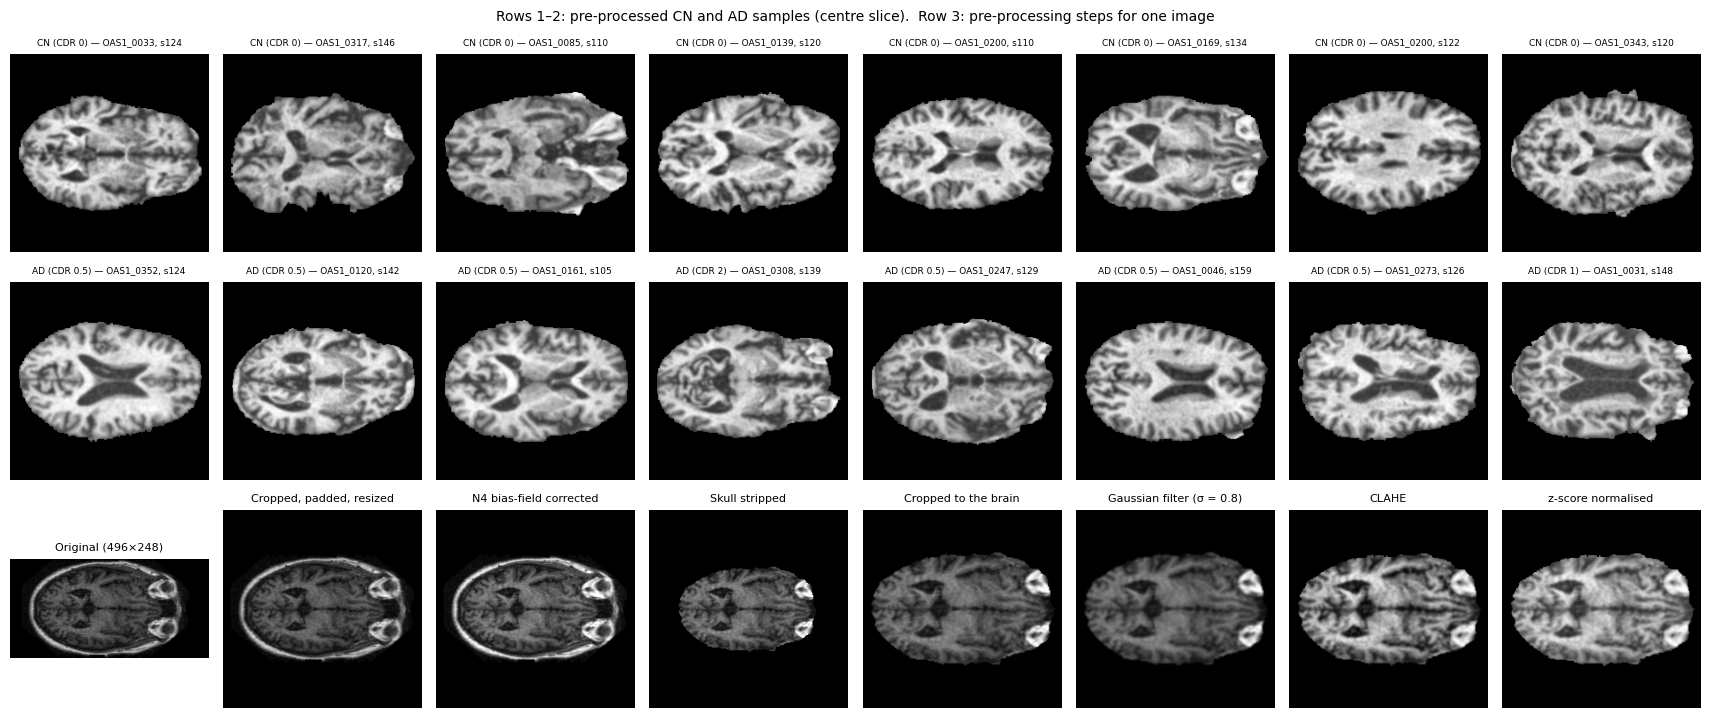

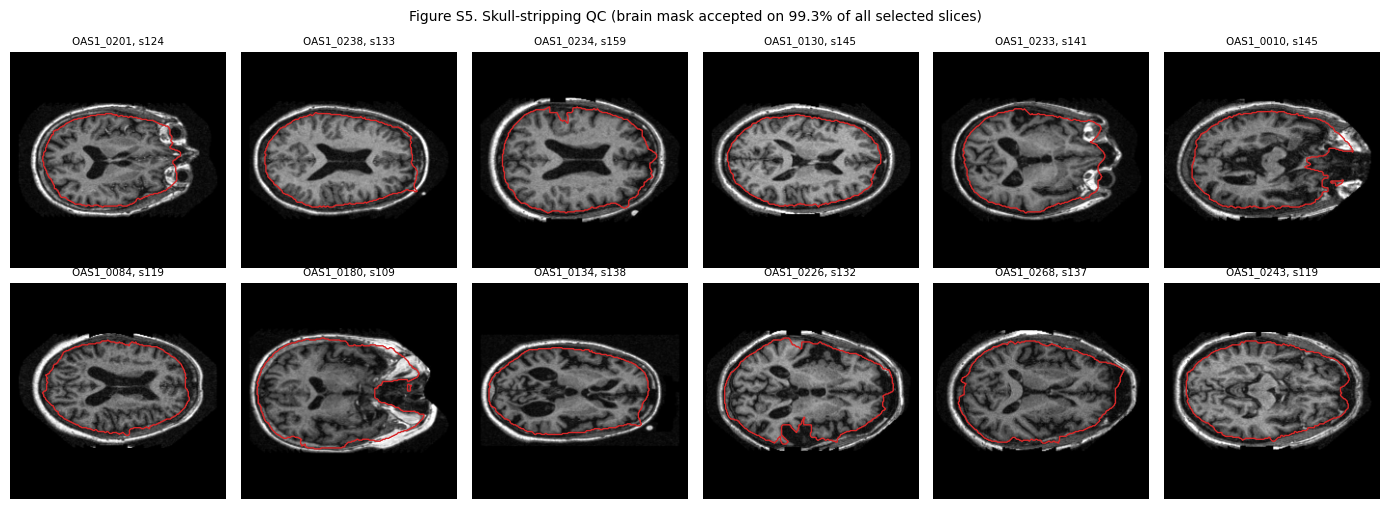

In [14]:
CLAHE = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=(8, 8))
cv2.setNumThreads(max(1, os.cpu_count() or 1))


def content_box(gray, thr=12, margin=0.04):
    """Bounding box of the head (pixels differing from the border/background value), with a small margin."""
    border = np.concatenate([gray[0], gray[-1], gray[:, 0], gray[:, -1]])
    bg = int(np.median(border))
    ys, xs = np.where(np.abs(gray.astype(np.int16) - bg) > thr)
    if len(ys) <= 50:
        return None
    y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max()
    my, mx = int((y1 - y0) * margin) + 2, int((x1 - x0) * margin) + 2
    return max(0, y0 - my), y1 + my + 1, max(0, x0 - mx), x1 + mx + 1


def crop_pad_square(gray, box="auto"):
    """Crop to the content bounding box (or a given box, so neighbouring slices stay aligned), pad to a square."""
    border = np.concatenate([gray[0], gray[-1], gray[:, 0], gray[:, -1]])
    bg = int(np.median(border))
    box = content_box(gray) if isinstance(box, str) else box
    if box is not None:
        gray = gray[box[0]:box[1], box[2]:box[3]]
    h, w = gray.shape
    side = max(h, w)
    out = np.full((side, side), bg, np.uint8)
    out[(side - h) // 2:(side - h) // 2 + h, (side - w) // 2:(side - w) // 2 + w] = gray
    return out


def disk(r):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))


def fill_holes(m):
    """Background components that do not touch the image border belong to the object (e.g. ventricles)."""
    m = m.astype(np.uint8)
    _, bg_lab = cv2.connectedComponents((m == 0).astype(np.uint8))
    border = np.unique(np.concatenate([bg_lab[0], bg_lab[-1], bg_lab[:, 0], bg_lab[:, -1]]))
    return (m > 0) | ((m == 0) & ~np.isin(bg_lab, border))


def brain_mask(img):
    """Head (foreground) mask: Otsu threshold, closing, largest component, hole filling."""
    _, m = cv2.threshold(cv2.GaussianBlur(img, (5, 5), 0), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))
    n_lab, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n_lab > 1:
        m = np.where(lab == 1 + np.argmax(st[1:, cv2.CC_STAT_AREA]), 255, 0).astype(np.uint8)
    return fill_holes(m)


def _circ_nanmedian(a, w):
    ext = np.concatenate([a[-w:], a, a[:w]])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)          # all-NaN windows stay NaN
        return np.array([np.nanmedian(ext[i:i + 2 * w + 1]) for i in range(len(a))])


def skull_strip(img, n_rays=180, max_depth=0.25, min_rays=0.35, min_ratio=0.45, max_ratio=0.95):
    """2D brain extraction by ray casting (keeps the cortex). Along rays from the head centre, find the transition
    scalp -> dark skull/CSF band -> brain tissue; median-filter the edge depth across neighbouring rays (outliers from
    orbits/sinuses removed), fill the contour. Returns (mask, ok); if ok is False the head mask is returned."""
    head = brain_mask(img)
    if head.sum() < 0.03 * img.size:
        return head, False
    sm = cv2.GaussianBlur(img, (3, 3), 0).astype(np.float32)
    v = sm[head].astype(np.uint8)
    t_hi, _ = cv2.threshold(v.reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    low = v[v < t_hi]
    if low.size < 50:
        return head, False
    t_lo, _ = cv2.threshold(low.reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)   # dark (bone, CSF) vs tissue
    ys, xs = np.nonzero(head)
    cy, cx = ys.mean(), xs.mean()
    H, W = img.shape
    ang = np.linspace(0, 2 * np.pi, n_rays, endpoint=False)
    step = 0.5
    rr = np.arange(0, np.hypot(H, W), step)
    r_head, depth = np.full(n_rays, np.nan), np.full(n_rays, np.nan)
    for i, a in enumerate(ang):
        yy, xx = cy + rr * np.sin(a), cx + rr * np.cos(a)
        inside = (yy >= 0) & (yy < H - 1) & (xx >= 0) & (xx < W - 1)
        yy, xx = yy[inside], xx[inside]
        hv = head[yy.round().astype(int), xx.round().astype(int)]
        if not hv.any():
            continue
        last = int(np.where(hv)[0].max())
        r_head[i] = rr[last]
        prof = cv2.remap(sm, xx[:last + 1].astype(np.float32).reshape(1, -1), yy[:last + 1].astype(np.float32).reshape(1, -1),
                         cv2.INTER_LINEAR).ravel()[::-1][:int(max_depth * rr[last] / step)]   # head surface -> inwards
        bright = np.where(prof > t_lo)[0]                         # scalp
        if len(bright) == 0:
            continue
        dark = np.where(prof[bright[0]:] <= t_lo)[0]              # skull / CSF band
        if len(dark) == 0:
            continue
        j1 = bright[0] + dark[0]
        back = np.where(prof[j1:] > t_lo)[0]                      # brain surface
        if len(back):
            depth[i] = (j1 + back[0]) * step
    if np.isfinite(depth).mean() < min_rays:
        return head, False
    rel = depth / r_head
    depth[np.abs(rel - np.nanmedian(rel)) > 0.08] = np.nan        # outliers (orbits, sinuses, deep sulci)
    d = _circ_nanmedian(depth, 6)
    ok_d = np.isfinite(d) & np.isfinite(r_head)
    if ok_d.mean() < min_rays:
        return head, False
    idx = np.arange(n_rays)
    d = np.interp(idx, idx[ok_d], d[ok_d], period=n_rays)
    rh = np.interp(idx, idx[np.isfinite(r_head)], r_head[np.isfinite(r_head)], period=n_rays)
    rb = np.clip(rh - d, 0, None)
    pts = np.stack([cx + rb * np.cos(ang), cy + rb * np.sin(ang)], 1).round().astype(np.int32)
    mask = np.zeros(img.shape, np.uint8)
    cv2.fillPoly(mask, [pts], 1)
    mask = (mask > 0) & head
    ok = min_ratio <= mask.sum() / max(1, head.sum()) <= max_ratio
    return (mask if ok else head), bool(ok)


N4_ON = BIAS_CORRECTION
if BIAS_CORRECTION:
    try:
        import SimpleITK as sitk
    except ImportError:
        print("SimpleITK is not installed -> N4 bias-field correction is skipped (re-run the installation cell)")
        N4_ON = False


def n4_log_field(img, mask, shrink=None, iters=(20, 20, 10), max_ratio=2.5):
    """Log bias field of one slice (N4 at ~64 px resolution, returned at full resolution). Returns None if N4 fails or
    the field is implausible (brightest/darkest gain inside the head > max_ratio), so the slice stays uncorrected."""
    shrink = shrink or max(1, int(round(img.shape[0] / 64)))
    try:
        im = sitk.GetImageFromArray(img.astype(np.float32) + 1.0)
        mk = sitk.GetImageFromArray(mask.astype(np.uint8))
        f = sitk.N4BiasFieldCorrectionImageFilter()
        f.SetMaximumNumberOfIterations(list(iters))
        f.Execute(sitk.Shrink(im, [shrink] * 2), sitk.Shrink(mk, [shrink] * 2))
        lf = sitk.GetArrayFromImage(f.GetLogBiasFieldAsImage(im)).astype(np.float32)
    except Exception:
        return None
    if not np.isfinite(lf).all() or (mask.any() and float(np.ptp(lf[mask])) > np.log(max_ratio)):
        return None
    return lf


def _resize(a, interp=cv2.INTER_AREA):
    return cv2.resize(a, (IMG_SIZE, IMG_SIZE), interpolation=interp)


def apply_n4(ims, c=0):
    """Estimate the bias field on ims[c] and divide every image of the stack by it (rescaled to uint8)."""
    head = brain_mask(ims[c])
    fld = n4_log_field(ims[c], head)
    if fld is None:
        return ims
    cor = [im.astype(np.float32) / np.exp(fld) for im in ims]
    hi = max(float(np.percentile(cor[c][head], 99.5)) if head.any() else float(cor[c].max()), 1e-6)
    return [np.clip(x_ / hi * 255, 0, 255).astype(np.uint8) for x_ in cor]


def preprocess_stack(paths, c=0, keep_steps=False):
    """paths: slice files of one stack (centre at index c). Returns (list of uint8 images, centre mask, mask ok, steps)."""
    raws = [cv2.imread(p_, cv2.IMREAD_GRAYSCALE) for p_ in paths]
    box = content_box(raws[c])                                    # one crop for the whole stack
    ims = [_resize(crop_pad_square(r_, box)) for r_ in raws]
    steps = {"Cropped, padded, resized": ims[c].copy()} if keep_steps else None
    if N4_ON:                                                     # 2) N4 bias field from the centre slice
        ims = apply_n4(ims, c)
        if keep_steps:
            steps["N4 bias-field corrected"] = ims[c].copy()
    if SKULL_STRIP:                                               # 3) brain extraction
        m_c, ok = skull_strip(ims[c])
        masks = []
        for i_, im in enumerate(ims):
            if i_ == c or paths[i_] == paths[c]:
                masks.append(m_c)
            else:
                m_i, ok_i = skull_strip(im)
                masks.append(m_i if (ok_i and ok) else m_c)
        ims = [np.where(m_, im, 0).astype(np.uint8) for m_, im in zip(masks, ims)]
        if keep_steps:
            steps["Skull stripped" + ("" if ok else " (fallback: head mask)")] = ims[c].copy()
    else:
        m_c, ok = brain_mask(ims[c]), True
        masks = [m_c] * len(ims)
    if SKULL_STRIP and BRAIN_CROP and m_c.any():                  # 4) crop to the brain (shared box)
        ys, xs = np.nonzero(m_c)
        cy, cx = (ys.min() + ys.max()) / 2, (xs.min() + xs.max()) / 2
        half = max(ys.max() - ys.min(), xs.max() - xs.min()) / 2 * 1.06 + 2
        y0, x0 = int(max(0, cy - half)), int(max(0, cx - half))
        y1, x1 = int(min(IMG_SIZE, cy + half + 1)), int(min(IMG_SIZE, cx + half + 1))
        ims = [_resize(crop_pad_square(im, (y0, y1, x0, x1)), cv2.INTER_LINEAR) for im in ims]
        masks = [_resize(crop_pad_square(m_.astype(np.uint8), (y0, y1, x0, x1)), cv2.INTER_NEAREST) > 0 for m_ in masks]
        m_c = masks[c]
        if keep_steps:
            steps["Cropped to the brain"] = ims[c].copy()
    out = []
    for i_, (im, m_) in enumerate(zip(ims, masks)):
        if DENOISE == "gaussian":                                 # 5) denoising
            im = cv2.GaussianBlur(im, (0, 0), GAUSS_SIGMA)
        elif DENOISE == "median":
            im = cv2.medianBlur(im, 3)
        if keep_steps and i_ == c and DENOISE != "none":
            steps["Gaussian filter (σ = %g)" % GAUSS_SIGMA if DENOISE == "gaussian" else "Median filter (3×3)"] = im.copy()
        im = CLAHE.apply(im)                                      # 6) CLAHE
        if SKULL_STRIP:
            im = np.where(m_, im, 0).astype(np.uint8)
        if keep_steps and i_ == c:
            steps["CLAHE"] = im.copy()
        if INTENSITY_NORM == "zscore" and m_.sum() > 20:          # 7) intensity normalisation
            v_ = im[m_].astype(np.float32)
            z = (im.astype(np.float32) - v_.mean()) / max(float(v_.std()), 1e-6)
            im = np.clip((z + 3) / 6 * 255, 0, 255).astype(np.uint8)
            if SKULL_STRIP:
                im = np.where(m_, im, 0).astype(np.uint8)
        else:
            im = cv2.normalize(im, None, 0, 255, cv2.NORM_MINMAX)
        if keep_steps and i_ == c:
            steps["z-score normalised" if INTENSITY_NORM == "zscore" else "Min–max normalised"] = im.copy()
        out.append(im)
    return out, m_c, ok, steps


X = np.zeros((len(df), IMG_SIZE, IMG_SIZE), np.uint8)          # centre slice (display, masks, 2D input)
X3 = np.zeros((len(df), 3, IMG_SIZE, IMG_SIZE), np.uint8) if INPUT_MODE == "2.5d" else None
MASK = np.zeros((len(df), IMG_SIZE, IMG_SIZE), bool)            # brain (or head) mask of the centre slice
STRIP_OK = np.ones(len(df), bool)
t_pre = time.time()
for i, r in enumerate(df.itertuples()):
    paths, c = ([r.path_lo, r.path, r.path_hi], 1) if X3 is not None else ([r.path], 0)
    chans, MASK[i], STRIP_OK[i], _ = preprocess_stack(paths, c)
    X[i] = chans[c]
    if X3 is not None:
        X3[i] = np.stack(chans)
    if (i + 1) % 500 == 0:
        el = time.time() - t_pre
        print(f"  pre-processed {i + 1}/{len(df)} stacks ({el / 60:.1f} min, ~{el / (i + 1) * (len(df) - i - 1) / 60:.1f} min left)")
y = df.label.values.astype(np.int64)
groups = df.group.values
PREPROC = dict(n4=N4_ON, skull_strip=SKULL_STRIP, strip_ok_pct=100 * float(STRIP_OK.mean()),
               minutes=(time.time() - t_pre) / 60)
print("Image tensor:", (X3 if X3 is not None else X).shape, "| input mode:", INPUT_MODE,
      f"| N4: {'on' if N4_ON else 'off'} | skull stripping succeeded on {PREPROC['strip_ok_pct']:.1f}% of slices"
      if SKULL_STRIP else "", f"| {PREPROC['minutes']:.1f} min")
PREPROC_TXT = "; ".join(t_ for t_ in [
    "crop to the head, pad to a square, resize",
    "N4 bias-field correction (field from the centre slice)" if N4_ON else ("N4 skipped (SimpleITK unavailable)" if BIAS_CORRECTION else ""),
    f"2D skull stripping (brain mask accepted on {PREPROC['strip_ok_pct']:.1f}% of slices, head mask otherwise)" if SKULL_STRIP else "skull not removed",
    "crop to the brain" if SKULL_STRIP and BRAIN_CROP else "",
    {"gaussian": f"Gaussian filter (σ = {GAUSS_SIGMA:g} px)", "median": "median filter 3×3", "none": ""}[DENOISE],
    f"CLAHE ({CLAHE_CLIP:g}, 8×8)",
    ("z-score within the brain mask (clipped to ±3 SD)" if SKULL_STRIP else "z-score within the head mask (clipped to ±3 SD)")
    if INTENSITY_NORM == "zscore" else "min–max normalisation"] if t_)
if SKULL_STRIP and PREPROC["strip_ok_pct"] < 70:
    print("WARNING: skull stripping fell back to the head mask on many slices. Check Figure S5; if the masks are poor, "
          "set SKULL_STRIP = False.")

# Figure 1 / Figure 4: samples and the pre-processing pipeline
demo_i = int(rng.choice(np.where(y == 1)[0]))
demo_paths, demo_c = (([df.path_lo[demo_i], df.path[demo_i], df.path_hi[demo_i]], 1) if X3 is not None else ([df.path[demo_i]], 0))
_, _, _, demo_steps = preprocess_stack(demo_paths, demo_c, keep_steps=True)
raw = cv2.imread(df.path[demo_i], cv2.IMREAD_GRAYSCALE)
panels = [(f"Original ({raw.shape[1]}×{raw.shape[0]})", raw)] + list(demo_steps.items())
ncol = max(6, len(panels))
fig, axes = plt.subplots(3, ncol, figsize=(2.15 * ncol, 7.4))
for row, lab in enumerate((0, 1)):
    picks = rng.choice(np.where(y == lab)[0], ncol, replace=False)
    for ax, i in zip(axes[row], picks):
        ax.imshow(X[i], cmap="gray"); ax.axis("off")
        ax.set_title(f"{'CN' if lab == 0 else 'AD'} (CDR {df.cdr_folder[i]:g}) — {df.subject[i]}, s{df.slice[i]}", fontsize=6.5)
for ax in axes[2]:
    ax.axis("off")
for ax, (t, im) in zip(axes[2], panels):
    ax.imshow(im, cmap="gray"); ax.set_title(t, fontsize=8)
fig.suptitle("Rows 1–2: pre-processed CN and AD samples (centre slice).  Row 3: pre-processing steps for one image", fontsize=10)
fig.tight_layout()
FIGS = {"fig01": savefig(fig, "fig01_samples_and_preprocessing")}

# Figure S5: skull-stripping quality control on random slices (red = brain mask, yellow = fallback to head mask)
if SKULL_STRIP:
    qc = rng.choice(len(df), min(12, len(df)), replace=False)
    fig, axes = plt.subplots(2, 6, figsize=(14, 5.2))
    for ax, i in zip(axes.ravel(), qc):
        im0 = _resize(crop_pad_square(cv2.imread(df.path[i], cv2.IMREAD_GRAYSCALE)))
        im0 = apply_n4([im0])[0] if N4_ON else im0               # same order as the pipeline: N4, then stripping
        m0, ok0 = skull_strip(im0)
        ax.imshow(im0, cmap="gray")
        ax.contour(m0, levels=[0.5], colors=["#d62728" if ok0 else "#ffbf00"], linewidths=1.0)
        ax.set_title(f"{df.subject[i]}, s{df.slice[i]}" + ("" if ok0 else " (fallback)"), fontsize=7.5); ax.axis("off")
    for ax in axes.ravel()[len(qc):]:
        ax.axis("off")
    fig.suptitle(f"Figure S5. Skull-stripping QC (brain mask accepted on {PREPROC['strip_ok_pct']:.1f}% of all selected slices)", fontsize=10)
    fig.tight_layout()
    FIGS["figS5"] = savefig(fig, "figS5_skull_strip_qc")

## 5. Subject-level stratified cross-validation (Sec. 3.1; R1-7, R3-3)

In [15]:
outer = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS, split_rows = [], []
for k, (tr_all, te) in enumerate(outer.split(np.zeros(len(y)), y, groups)):
    inner = StratifiedGroupKFold(n_splits=max(2, round(1 / VAL_FRAC)), shuffle=True, random_state=SEED + k)
    fit_rel, val_rel = next(inner.split(np.zeros(len(tr_all)), y[tr_all], groups[tr_all]))
    tr, va = tr_all[fit_rel], tr_all[val_rel]
    g_tr, g_va, g_te = set(groups[tr]), set(groups[va]), set(groups[te])
    assert not (g_tr & g_te) and not (g_va & g_te) and not (g_tr & g_va), "group leakage between splits"
    FOLDS.append(dict(train=tr, val=va, test=te))
    split_rows.append(dict(fold=k, train_images=len(tr), val_images=len(va), test_images=len(te),
                           train_groups=len(g_tr), val_groups=len(g_va), test_groups=len(g_te),
                           test_AD_fraction=round(float(y[te].mean()), 3), groups_shared_with_test=0))
SPLITS = pd.DataFrame(split_rows)
SPLITS.to_csv(os.path.join(OUT_DIR, "tables", "cv_splits.csv"), index=False)
display(SPLITS)
assert sorted(np.concatenate([f["test"] for f in FOLDS]).tolist()) == list(range(len(y))), "each image must be tested once"
print("Leakage check PASSED: no group is shared between training, validation and test data in any fold.")

print("Test subjects per fold (CN / AD):",
      [f"{df.subject[f['test']][y[f['test']] == 0].nunique()} / {df.subject[f['test']][y[f['test']] == 1].nunique()}" for f in FOLDS])

,fold,train_images,val_images,test_images,train_groups,val_groups,test_groups,test_AD_fraction,groups_shared_with_test
0,0,2778,455,367,128,21,17,0.428,0
1,1,2795,459,346,129,21,16,0.514,0
2,2,2777,455,368,128,21,17,0.421,0
3,3,2794,456,350,129,21,16,0.574,0
4,4,2775,457,368,128,21,17,0.421,0
5,5,2770,479,351,128,22,16,0.638,0
6,6,2774,479,347,128,22,16,0.576,0
7,7,2774,459,367,128,21,17,0.480,0
8,8,2796,455,349,129,21,16,0.510,0
9,9,2754,459,387,127,21,18,0.455,0


Leakage check PASSED: no group is shared between training, validation and test data in any fold.
Test subjects per fold (CN / AD): ['10 / 7', '8 / 8', '10 / 7', '7 / 9', '10 / 7', '6 / 10', '7 / 9', '9 / 8', '8 / 8', '10 / 8']


## 6. CNN feature extractor (Sec. 3.3)
**Default (`BACKBONE = "vgg16_bn"`)**: VGG16 with batch normalisation, pre-trained on ImageNet and fine-tuned end-to-end for CN vs AD.
- Input (`INPUT_MODE = "2.5d"`): the three channels are the selected slice and its neighbours `SLICE_OFFSET` positions below and above, from the same scan and with one shared crop. With `INPUT_MODE = "2d"` the single slice is replicated to three channels instead. Either way the input is normalised with the ImageNet mean and SD inside the model.
- The original fc6 and fc7 layers are kept; the **4096-d fc7 output is the feature vector F_CNN**, as described in the manuscript.
- The 1000-class ImageNet output layer is replaced by a 2-unit softmax.
- Training: AdamW (weight decay `CNN_WEIGHT_DECAY` = 0.01) with two learning rates, `CNN_LR_BACKBONE` = 1e-5 for the pre-trained convolutional layers and `CNN_LR` = 1e-4 for the fully connected layers. The learning rate is halved when validation loss plateaus, mixed precision is used on GPU, and early stopping cannot trigger before `CNN_MIN_EPOCHS`.
- Against overfitting (run 2: training accuracy ~90% while validation loss was lowest after 1–4 epochs): the first `FREEZE_BLOCKS` conv blocks stay fixed, the targets are label-smoothed (`LABEL_SMOOTHING`), augmentation is stronger (`AUGMENT`), and the checkpoint is chosen by the **subject-level validation AUC** (`SELECT_BY`), which kept improving in run 2 after the validation loss had started to rise.

**Why these changes.** In run 1, a five-block CNN trained from scratch (`BACKBONE = "custom"`) did not converge. Its training accuracy stayed at 52–58%, training loss stayed near ln 2 ≈ 0.69, it predicted P(AD) ≈ 0.5 for every image, and early stopping ended training after 7–10 epochs. Transfer learning from ImageNet is the standard remedy for small medical-imaging datasets. The smaller learning rate for the pre-trained layers keeps the ImageNet filters from being overwritten in the first epochs. The 2.5D input fills the three input channels with real neighbouring anatomy rather than three copies of one slice, and `MAX_PER_CLASS` was raised from 900 to 1,800 to give the network more slices per subject. All of these decisions rest on the *training* failure and on design reasoning, not on test results. Run-1 settings remain available as ablations: `BACKBONE = "custom"`, `INPUT_MODE = "2d"`, `MAX_PER_CLASS = 900`, `CNN_LR_BACKBONE = CNN_LR`.

Augmentation (training only, `AUGMENT = "strong"`): horizontal flip; random affine (±10° rotation, ±5% shift, 0.9–1.1 scale, ±5° shear); gamma, contrast and brightness jitter inside the brain; Gaussian noise; random erasing of small patches. These are the augmentation types used by the high-accuracy OASIS papers (e.g. Dardouri 2025), applied here only to training images.

In [16]:
class ADCNN(nn.Module):
    def __init__(self, widths=CNN_WIDTHS, feat_dim=FEATURE_DIM, dropout=CNN_DROPOUT):
        super().__init__()
        layers, c = [], IN_CHANNELS
        for w in widths:
            layers += [nn.Conv2d(c, w, 3, padding=1, bias=False), nn.BatchNorm2d(w), nn.ReLU(),
                       nn.Conv2d(w, w, 3, padding=1, bias=False), nn.BatchNorm2d(w), nn.ReLU(), nn.MaxPool2d(2)]
            c = w
        self.body = nn.Sequential(*layers[:-1])   # up to the last conv block (Grad-CAM target layer)
        self.last_pool = layers[-1]
        self.gap = nn.AdaptiveAvgPool2d(2)
        self.fc1 = nn.Linear(c * 4, feat_dim)
        self.drop = nn.Dropout(dropout)
        self.fc2 = nn.Linear(feat_dim, 2)

    def embed_from_maps(self, A):
        return F.relu(self.fc1(torch.flatten(self.gap(self.last_pool(A)), 1)))

    def embed(self, x):
        return self.embed_from_maps(self.body(x))

    def forward(self, x):
        return self.fc2(self.drop(self.embed(x)))


class InputAdapter(nn.Module):
    """Greyscale input in [-1, 1] -> 3-channel input normalised with ImageNet statistics."""

    def __init__(self):
        super().__init__()
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = x * 0.5 + 0.5
        if x.shape[1] == 1:                       # 2D mode: grey slice -> 3 identical channels
            x = x.repeat(1, 3, 1, 1)
        return (x - self.mean) / self.std


class VGGFeatureCNN(nn.Module):
    """VGG16(-BN) with ImageNet weights; fc7 (4096-d) is the feature vector, a new 2-unit layer is the classifier."""

    def __init__(self, arch=BACKBONE, pretrained=True, dropout=CNN_DROPOUT):
        super().__init__()
        v = getattr(torchvision.models, arch)(weights="DEFAULT" if pretrained else None)
        feats = list(v.features.children())
        assert isinstance(feats[-1], nn.MaxPool2d)
        self.body = nn.Sequential(InputAdapter(), *feats[:-1])   # ends at the last conv ReLU (Grad-CAM target layer)
        self.last_pool, self.gap = feats[-1], v.avgpool
        self.fc6, self.fc7 = v.classifier[0], v.classifier[3]    # Linear(25088, 4096), Linear(4096, 4096)
        self.drop = nn.Dropout(dropout)
        self.fc2 = nn.Linear(self.fc7.out_features, 2)
        # freeze the first FREEZE_BLOCKS conv blocks (index in body just after the N-th max-pool)
        pools = [i for i, m in enumerate(self.body) if isinstance(m, nn.MaxPool2d)]
        self.n_frozen = pools[FREEZE_BLOCKS - 1] + 1 if pretrained and 0 < FREEZE_BLOCKS <= len(pools) else 0
        for m in list(self.body)[:self.n_frozen]:
            for q in m.parameters():
                q.requires_grad_(False)

    def train(self, mode=True):
        super().train(mode)
        for m in list(self.body)[:self.n_frozen]:      # frozen blocks keep their BatchNorm statistics
            m.eval()
        return self

    def head_parameters(self):
        return [p for m in (self.fc6, self.fc7, self.fc2) for p in m.parameters()]

    def embed_from_maps(self, A):
        h = self.drop(F.relu(self.fc6(torch.flatten(self.gap(self.last_pool(A)), 1))))
        return F.relu(self.fc7(h))                                # F_CNN: 4096-d

    def embed(self, x):
        return self.embed_from_maps(self.body(x))

    def forward(self, x):
        return self.fc2(self.drop(self.embed(x)))


ADCNN.head_parameters = lambda self: [p for m in (self.fc1, self.fc2) for p in m.parameters()]


def build_cnn(pretrained=None):
    if BACKBONE == "custom":
        return ADCNN()
    pre = PRETRAINED if pretrained is None else pretrained
    try:
        return VGGFeatureCNN(BACKBONE, pre)
    except Exception as e:
        raise SystemExit(f"Could not create {BACKBONE} with ImageNet weights ({type(e).__name__}: {e}).\n"
                         "Kaggle: Settings -> Internet ON (the weights, ~530 MB, are downloaded once), then re-run this cell.")


class IntensityAug:
    """Gamma, contrast and brightness jitter plus Gaussian noise, applied to tissue pixels only (background stays 0)."""

    def __call__(self, x):
        u = lambda a, b: float(torch.empty(1).uniform_(a, b))
        m = x > 0.02
        x = x.clamp(0, 1) ** math.exp(u(-0.2, 0.2))
        x = torch.where(m, (x - 0.5) * u(0.9, 1.1) + 0.5 + u(-0.05, 0.05), x)
        if u(0, 1) < 0.5:
            x = torch.where(m, x + torch.randn_like(x) * u(0, 0.03), x)
        return x.clamp(0, 1)


AUG = (T.Compose([T.RandomHorizontalFlip(),
                  T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1), shear=5),
                  IntensityAug(),
                  T.RandomErasing(p=0.25, scale=(0.02, 0.08), value=0)])
       if AUGMENT == "strong" else
       T.Compose([T.RandomHorizontalFlip(), T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05))]))


class MRIDataset(Dataset):
    def __init__(self, idx, augment):
        self.idx, self.augment = np.asarray(idx), augment

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        img = torch.from_numpy(X3[j] if X3 is not None else X[j][None]).float().div(255)
        if self.augment:
            img = AUG(img)
        return (img - 0.5) / 0.5, int(y[j])


def to_batch(idx):
    arr = X3[idx] if X3 is not None else X[idx][:, None]
    return ((torch.from_numpy(arr).float().div(255) - 0.5) / 0.5).to(DEVICE)


@torch.no_grad()
def cnn_predict(model, idx, bs=64):
    model.eval()
    probs, feats, losses = [], [], []
    for s in range(0, len(idx), bs):
        b = idx[s:s + bs]
        xb = to_batch(b)
        f = model.embed(xb)
        logits = model.fc2(f)
        losses.append(F.cross_entropy(logits, torch.from_numpy(y[b]).to(DEVICE), reduction="sum").item())
        probs.append(torch.softmax(logits, 1)[:, 1].cpu().numpy())
        feats.append(f.cpu().numpy())
    return np.concatenate(probs), np.concatenate(feats).astype(np.float32), sum(losses) / len(idx)


AMP_ON = USE_AMP and DEVICE.type == "cuda"


def _grad_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=AMP_ON)
    except (AttributeError, TypeError):           # older PyTorch
        return torch.cuda.amp.GradScaler(enabled=AMP_ON)


def subject_auc(p, idx):
    """AUC of the mean slice probability per subject (group); 0.5 if only one class is present."""
    s_ = pd.DataFrame({"g": groups[idx], "p": p, "y": y[idx]}).groupby("g").mean()
    return float(roc_auc_score(s_.y, s_.p)) if s_.y.nunique() == 2 else 0.5


def train_cnn(fold, seed, verbose=True):
    set_seed(seed)
    model = build_cnn().to(DEVICE)
    head = model.head_parameters()
    head_ids = {id(q) for q in head}
    body = [q for q in model.parameters() if id(q) not in head_ids and q.requires_grad]
    groups_lr = ([{"params": body, "lr": CNN_LR_BACKBONE}, {"params": head, "lr": CNN_LR}]
                 if BACKBONE != "custom" and PRETRAINED else [{"params": list(model.parameters()), "lr": CNN_LR}])
    opt = torch.optim.AdamW(groups_lr, weight_decay=CNN_WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2)
    scaler = _grad_scaler()
    g = torch.Generator(); g.manual_seed(seed)
    dl = DataLoader(MRIDataset(fold["train"], True), batch_size=BATCH_SIZE, shuffle=True,
                    num_workers=NUM_WORKERS, generator=g, drop_last=len(fold["train"]) % BATCH_SIZE == 1)
    best, best_vl, best_state, wait, hist = -float("inf"), float("inf"), None, 0, []
    t0 = time.time()
    for ep in range(CNN_EPOCHS):
        model.train()
        tl, tc, tn = 0.0, 0, 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with (torch.autocast(device_type="cuda", dtype=torch.float16) if AMP_ON else contextlib.nullcontext()):
                out = model(xb)
                loss = F.cross_entropy(out, yb, label_smoothing=LABEL_SMOOTHING)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(yb); tc += (out.argmax(1) == yb).sum().item(); tn += len(yb)
        pv, _, vl = cnn_predict(model, fold["val"])
        va = float(((pv >= 0.5) == y[fold["val"]]).mean())
        vauc = subject_auc(pv, fold["val"])
        lr_now = opt.param_groups[-1]["lr"]
        hist.append(dict(epoch=ep + 1, train_loss=tl / tn, train_acc=tc / tn, val_loss=vl, val_acc=va, val_auc=vauc, lr=lr_now))
        if verbose:
            print(f"  epoch {ep + 1:2d}  train loss {tl / tn:.4f} acc {tc / tn:.3f} | val loss {vl:.4f} acc {va:.3f} "
                  f"subject AUC {vauc:.3f} | lr {lr_now:.1e}")
        sched.step(vl)
        metric = vauc if SELECT_BY == "val_auc" else -vl
        improved = metric > best + 1e-4 or (SELECT_BY == "val_auc" and abs(metric - best) <= 1e-4 and vl < best_vl)
        if improved:
            best, best_vl, wait = metric, vl, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            best_epoch = ep + 1
        else:
            wait += 1
            if wait >= CNN_PATIENCE and ep + 1 >= CNN_MIN_EPOCHS:
                if verbose:
                    print(f"  early stopping at epoch {ep + 1} (kept epoch {best_epoch}: "
                          + (f"validation subject AUC {best:.3f})" if SELECT_BY == "val_auc" else f"validation loss {-best:.4f})"))
                break
    model.load_state_dict(best_state)
    hist = [dict(h_, kept=(h_["epoch"] == best_epoch)) for h_ in hist]
    if hist[-1]["train_acc"] < 0.65:
        print(f"  WARNING: training accuracy is only {hist[-1]['train_acc']:.2f} — the CNN has not learned the training "
              "data; downstream VQC/hybrid results will be at chance level.")
    return model, pd.DataFrame(hist), time.time() - t0


_tmp = build_cnn(pretrained=False)          # architecture only (no download) for parameter counts
N_PARAMS = {"cnn_total": sum(p.numel() for p in _tmp.parameters()),
            "cnn_conv": sum(p.numel() for p in _tmp.body.parameters()),
            "cnn_classification_part": sum(p.numel() for p in _tmp.head_parameters())}
if BACKBONE != "custom" and PRETRAINED:     # download the ImageNet weights once, before the folds start
    del _tmp
    _tmp = build_cnn()
    print(f"{BACKBONE}: ImageNet weights loaded")
N_PARAMS["cnn_trainable"] = sum(p.numel() for p in _tmp.parameters() if p.requires_grad)
with torch.no_grad():
    _a = _tmp.body(torch.zeros(1, IN_CHANNELS, IMG_SIZE, IMG_SIZE))
GRADCAM_MAP_SIZE = tuple(_a.shape[-2:])
print(_tmp)
print(N_PARAMS, "| Grad-CAM target maps:", tuple(_a.shape[1:]))
del _tmp, _a

Downloading: "https://download.pytorch.org/models/vgg16_bn-6c64b313.pth" to /root/.cache/torch/hub/checkpoints/vgg16_bn-6c64b313.pth


100%|██████████| 528M/528M [00:02<00:00, 210MB/s] 


vgg16_bn: ImageNet weights loaded
VGGFeatureCNN(
  (body): Sequential(
    (0): InputAdapter()
    (1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU(inplace=True)
    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU(inplace=True)
    (14): MaxPool2d(kernel_size=2, stride=2, 

## 7. Quantum circuits (Sec. 3.5–3.6) and verification against Qiskit
The circuits are defined with Qiskit's `zz_feature_map` (or RY angle encoding) and `real_amplitudes`. The output is the expectation value ⟨Z_k⟩ of every qubit (Eq. 13).

The same circuit is simulated exactly in PyTorch (state vector, complex64). This gives fast batched training and exact gradients, and it lets Grad-CAM back-propagate through the quantum layer. **Before any training, the PyTorch simulator is checked against Qiskit's `Statevector` on random inputs and parameters for every qubit count used.**

In [17]:
def entangling_pairs(n, kind=ENTANGLEMENT):
    if kind == "linear":
        return [(i, i + 1) for i in range(n - 1)]
    if kind == "full":
        return [(i, j) for i in range(n) for j in range(i + 1, n)]
    raise ValueError("ENTANGLEMENT must be 'linear' or 'full'")


def qiskit_circuit(n):
    """Feature map + ansatz exactly as used in the paper (Figure 7)."""
    if ENCODING == "zz":
        fm = zz_feature_map(n, reps=FM_REPS, entanglement=ENTANGLEMENT)
    else:
        xv = ParameterVector("x", n)
        fm = QuantumCircuit(n, name="AngleEncoding")
        for i in range(n):
            fm.ry(xv[i], i)
    an = real_amplitudes(n, reps=ANSATZ_REPS, entanglement=ENTANGLEMENT)
    return fm.compose(an), list(fm.parameters), list(an.parameters)


_H = torch.tensor([[1, 1], [1, -1]], dtype=torch.complex64) / math.sqrt(2)


def _apply_1q(psi, U, k):
    psi = psi.movedim(k + 1, -1)
    if U.dim() == 2:
        psi = psi @ U.transpose(0, 1)
    else:
        shp = psi.shape
        psi = torch.einsum("bmj,bij->bmi", psi.reshape(shp[0], -1, 2), U).reshape(shp)
    return psi.movedim(-1, k + 1)


def _apply_phase(psi, lam, k):          # P(lam) = diag(1, e^{i lam}); lam has shape (B,)
    psi = psi.movedim(k + 1, -1)
    ph = torch.exp(1j * lam).reshape((-1,) + (1,) * (psi.dim() - 2))
    psi = torch.stack((psi[..., 0], psi[..., 1] * ph), dim=-1)
    return psi.movedim(-1, k + 1)


def _apply_cx(psi, c, t):
    psi = torch.movedim(psi, (c + 1, t + 1), (-2, -1))
    psi = torch.stack((psi[..., 0, :], psi[..., 1, :].flip(-1)), dim=-2)
    return torch.movedim(psi, (-2, -1), (c + 1, t + 1))


def _ry(theta):                          # theta scalar -> (2,2) or (B,) -> (B,2,2)
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    U = torch.stack((torch.stack((c, -s), -1), torch.stack((s, c), -1)), -2)
    return torch.complex(U, torch.zeros_like(U))


class TorchVQC(nn.Module):
    """Exact state-vector simulation of qiskit_circuit(n); returns <Z_k> for every qubit k."""

    def __init__(self, n):
        super().__init__()
        self.n, self.pairs = n, entangling_pairs(n)
        self.theta = nn.Parameter(torch.empty(n * (ANSATZ_REPS + 1)).uniform_(-math.pi, math.pi))

    def forward(self, x):
        B, n = x.shape[0], self.n
        psi = torch.zeros((B, 2 ** n), dtype=torch.complex64, device=x.device)
        psi[:, 0] = 1
        psi = psi.reshape((B,) + (2,) * n)
        H = _H.to(x.device)
        if ENCODING == "zz":
            for _ in range(FM_REPS):
                for i in range(n):
                    psi = _apply_1q(psi, H, i)
                for i in range(n):
                    psi = _apply_phase(psi, 2 * x[:, i], i)
                for i, j in self.pairs:
                    psi = _apply_cx(psi, i, j)
                    psi = _apply_phase(psi, 2 * (math.pi - x[:, i]) * (math.pi - x[:, j]), j)
                    psi = _apply_cx(psi, i, j)
        else:
            for i in range(n):
                psi = _apply_1q(psi, _ry(x[:, i]), i)
        t = 0
        for _ in range(ANSATZ_REPS):
            for i in range(n):
                psi = _apply_1q(psi, _ry(self.theta[t]), i); t += 1
            for i, j in self.pairs:
                psi = _apply_cx(psi, i, j)
        for i in range(n):
            psi = _apply_1q(psi, _ry(self.theta[t]), i); t += 1
        prob = psi.real ** 2 + psi.imag ** 2
        out = []
        for k in range(n):
            pk = prob.movedim(k + 1, 1).reshape(B, 2, -1).sum(-1)
            out.append(pk[:, 0] - pk[:, 1])
        return torch.stack(out, 1)


def z_observables(n):
    return [SparsePauliOp.from_sparse_list([("Z", [k], 1.0)], num_qubits=n) for k in range(n)]


def qiskit_expectations(n, Xq, theta):
    qc, xp, tp = qiskit_circuit(n)
    obs = z_observables(n)
    out = np.zeros((len(Xq), n))
    for s, xs in enumerate(Xq):
        bind = {**dict(zip(xp, xs)), **dict(zip(tp, theta))}
        sv = Statevector(qc.assign_parameters(bind))
        out[s] = [sv.expectation_value(o).real for o in obs]
    return out


def verify_simulator(n, n_samples=16, seed=0):
    r = np.random.default_rng(seed)
    Xq = r.uniform(0, np.pi, (n_samples, n)).astype(np.float32)
    m = TorchVQC(n)
    with torch.no_grad():
        theta = m.theta.numpy().astype(np.float64)
        ours = m(torch.from_numpy(Xq)).numpy()
    ref = qiskit_expectations(n, Xq.astype(np.float64), theta)
    return float(np.abs(ours - ref).max())


SIM_CHECK = {n: verify_simulator(n) for n in sorted(set([N_QUBITS] + (SWEEP_QUBITS if RUN_QUBIT_SWEEP else [])))}
print("Max |<Z>_PyTorch - <Z>_Qiskit| on random inputs/parameters:", {k: f"{v:.1e}" for k, v in SIM_CHECK.items()})
assert max(SIM_CHECK.values()) < 1e-4, "PyTorch simulator does not match Qiskit — do not continue"

QC, QC_X, QC_T = qiskit_circuit(N_QUBITS)
_dec = QC   # already expressed in H, P, CX and RY gates
CIRCUIT_INFO = dict(qubits=N_QUBITS, encoding=ENCODING, feature_map_reps=FM_REPS if ENCODING == "zz" else 1,
                    ansatz="RealAmplitudes", ansatz_reps=ANSATZ_REPS, entanglement=ENTANGLEMENT,
                    trainable_parameters=len(QC_T), depth=_dec.depth(), cx_gates=int(_dec.count_ops().get("cx", 0)))
print(CIRCUIT_INFO)
try:
    fig = QC.draw("mpl", fold=-1, scale=0.7)
    fig.suptitle(f"Figure 7. VQC: {'ZZ feature map' if ENCODING == 'zz' else 'angle encoding'} + RealAmplitudes "
                 f"({N_QUBITS} qubits, {len(QC_T)} trainable parameters)", fontsize=10)
    FIGS["fig07"] = savefig(fig, "fig07_vqc_circuit")
except Exception as e:  # pylatexenc missing etc.
    print("Circuit drawing (mpl) unavailable:", e)
    print(QC.draw("text", fold=160))

Max |<Z>_PyTorch - <Z>_Qiskit| on random inputs/parameters: {4: '9.1e-07', 5: '9.5e-07', 6: '8.6e-07', 7: '8.7e-07', 8: '9.1e-07'}
{'qubits': 4, 'encoding': 'zz', 'feature_map_reps': 2, 'ansatz': 'RealAmplitudes', 'ansatz_reps': 2, 'entanglement': 'linear', 'trainable_parameters': 12, 'depth': 26, 'cx_gates': 18}


## 8. Classifier heads: standalone VQC, hybrid CNN–VQC and classical ablations (Sec. 3.6–3.7)

| Model | Input | Trainable parameters |
|---|---|---|
| **VQC** | leading *n* PCA components scaled to [0, π] → VQC → ⟨Z⟩ (n values) → softmax | ansatz + (2n + 2) |
| **Hybrid CNN–VQC** (Eq. 14–15) | H = [standardised 64 PCA components ⊕ ⟨Z⟩ of the VQC] → softmax | ansatz + (2(64 + n) + 2) |
| Ablation: linear on *n* comps | same *n* PCA components → softmax (no quantum layer) | 2n + 2 |
| Ablation: linear on 64 comps | same 64 standardised components → softmax (no quantum layer) | 130 |

The two classical ablations isolate what the quantum layer adds. This addresses whether the VQC improves on a classical model given exactly the same inputs (R1-3, R3-1, R3-11).

In [18]:
class VQCClassifier(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.q, self.out = TorchVQC(n), nn.Linear(n, 2)

    def forward(self, xq):
        return self.out(self.q(xq))


class HybridHead(nn.Module):
    def __init__(self, n, d=N_PCA):
        super().__init__()
        self.q, self.out = TorchVQC(n), nn.Linear(d + n, 2)

    def forward(self, zc, xq):
        return self.out(torch.cat([zc, self.q(xq)], 1))


class LinearHead(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.out = nn.Linear(d, 2)

    def forward(self, z):
        return self.out(z)


def _train_once(model, tr_inputs, ytr_t, va_inputs, yva_t, seed):
    model = model.to(Q_DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=Q_LR)
    best, best_state, wait = float("inf"), None, 0
    g = torch.Generator(); g.manual_seed(seed)
    ytr = ytr_t.cpu().numpy()
    for ep in range(Q_EPOCHS):
        model.train()
        perm = torch.randperm(len(ytr), generator=g)
        for s in range(0, len(ytr), Q_BATCH):
            b = perm[s:s + Q_BATCH]
            opt.zero_grad()
            loss = F.cross_entropy(model(*[a[b] for a in tr_inputs]), ytr_t[b])
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            vl = F.cross_entropy(model(*va_inputs), yva_t).item()
        if vl < best - 1e-5:
            best, wait = vl, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= Q_PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, best, ep + 1


def train_head(make_model, tr_inputs, ytr, va_inputs, yva, seed, restarts=None):
    """Train Q_RESTARTS randomly initialised copies; keep the one with the lowest validation loss."""
    t0 = time.time()
    tr_inputs = [torch.as_tensor(a, dtype=torch.float32, device=Q_DEVICE) for a in tr_inputs]
    va_inputs = [torch.as_tensor(a, dtype=torch.float32, device=Q_DEVICE) for a in va_inputs]
    ytr_t, yva_t = torch.as_tensor(ytr, device=Q_DEVICE), torch.as_tensor(yva, device=Q_DEVICE)
    best = None
    for r in range(restarts or Q_RESTARTS):
        set_seed(seed + 1000 * r)
        res = _train_once(make_model(), tr_inputs, ytr_t, va_inputs, yva_t, seed + 1000 * r)
        if best is None or res[1] < best[1]:
            best = res
    return best[0], time.time() - t0, best[2]


@torch.no_grad()
def head_predict(model, inputs):
    model.eval()
    dev = next(model.parameters()).device
    inputs = [torch.as_tensor(a, dtype=torch.float32, device=dev) for a in inputs]
    return torch.softmax(model(*inputs), 1)[:, 1].cpu().numpy()


def count_params(m):
    return sum(p.numel() for p in m.parameters())

## 9. Training: subject-level stratified K-fold cross-validation (`N_FOLDS`)
In each fold:
1. Train the CNN, with early stopping on the validation groups.
2. Extract 4096-d features.
3. Fit PCA and the scalers on the training groups only.
4. Run the qubit sweep on the validation groups.
5. Train the VQC, the hybrid head and both ablations.
6. Predict the test fold.

Runtime with the defaults (≈3,600 images, 10 folds): roughly 1.5–2.5 hours on a Kaggle T4 GPU, most of it CNN training (pre-processing with N4 and skull stripping adds ~5–10 minutes). The quantum and linear heads always run on CPU, where these small circuits are faster. Without a GPU, CNN training can take several hours.

In [19]:
P = {k: np.full(len(y), np.nan) for k in ("cnn", "vqc", "hybrid", "lin_n", "lin64")}
FOLD_OF = np.full(len(y), -1)
HIST, TIMES, SWEEP, EPOCHS_USED, KEEP = [], [], [], [], {}
for k, fold in enumerate(FOLDS):
    print(f"\n=== Fold {k + 1}/{N_FOLDS}: train {len(fold['train'])}, val {len(fold['val'])}, test {len(fold['test'])} ===")
    seed = SEED + 100 * k
    cnn, hist, t_cnn = train_cnn(fold, seed)
    HIST.append(hist.assign(fold=k))
    _, F_tr, _ = cnn_predict(cnn, fold["train"])
    p_va, F_va, _ = cnn_predict(cnn, fold["val"])
    p_te, F_te, _ = cnn_predict(cnn, fold["test"])
    P["cnn"][fold["test"]] = p_te
    FOLD_OF[fold["test"]] = k

    pca = PCA(n_components=N_PCA, random_state=seed).fit(F_tr)        # training groups only
    Z_tr, Z_va, Z_te = (pca.transform(a) for a in (F_tr, F_va, F_te))
    sc = StandardScaler().fit(Z_tr)
    C_tr, C_va, C_te = (sc.transform(a) for a in (Z_tr, Z_va, Z_te))

    def q_inputs(n):
        mm = MinMaxScaler((0, np.pi)).fit(Z_tr[:, :n])
        return mm, [np.clip(mm.transform(a[:, :n]), 0, np.pi) for a in (Z_tr, Z_va, Z_te)]

    y_tr, y_va, y_te = y[fold["train"]], y[fold["val"]], y[fold["test"]]
    if RUN_QUBIT_SWEEP:                                                 # validation groups only — never the test fold
        cum = np.cumsum(pca.explained_variance_ratio_) * 100
        for n in SWEEP_QUBITS:
            _, (q_tr, q_va, _) = q_inputs(n)
            m, t_s, _ = train_head(lambda: VQCClassifier(n), [q_tr], y_tr, [q_va], y_va, seed + n, restarts=1)
            pv = head_predict(m, [q_va])
            SWEEP.append(dict(fold=k, n_qubits=n, cumulative_variance_pct=cum[n - 1],
                              val_accuracy=100 * float(((pv >= 0.5) == y_va).mean()),
                              val_auc=float(roc_auc_score(y_va, pv)), trainable_params=count_params(m),
                              train_time_s=t_s))
        print("  qubit sweep (val acc %):", {d["n_qubits"]: round(d["val_accuracy"], 1) for d in SWEEP if d["fold"] == k})

    mm, (q_tr, q_va, q_te) = q_inputs(N_QUBITS)
    vqc, t_vqc, e_vqc = train_head(lambda: VQCClassifier(N_QUBITS), [q_tr], y_tr, [q_va], y_va, seed + 1)
    hyb, t_hyb, e_hyb = train_head(lambda: HybridHead(N_QUBITS), [C_tr, q_tr], y_tr, [C_va, q_va], y_va, seed + 2)
    lin_n, t_ln, _ = train_head(lambda: LinearHead(N_QUBITS), [q_tr], y_tr, [q_va], y_va, seed + 3)
    lin64, t_l64, _ = train_head(lambda: LinearHead(N_PCA), [C_tr], y_tr, [C_va], y_va, seed + 4)
    P["vqc"][fold["test"]] = head_predict(vqc, [q_te])
    P["hybrid"][fold["test"]] = head_predict(hyb, [C_te, q_te])
    P["lin_n"][fold["test"]] = head_predict(lin_n, [q_te])
    P["lin64"][fold["test"]] = head_predict(lin64, [C_te])
    TIMES.append(dict(fold=k, cnn_s=t_cnn, vqc_s=t_vqc, hybrid_s=t_hyb, lin_n_s=t_ln, lin64_s=t_l64,
                      cnn_epochs=len(hist), vqc_epochs=e_vqc, hybrid_epochs=e_hyb))
    accs = {m: 100 * float(((P[m][fold["test"]] >= 0.5) == y_te).mean()) for m in P}
    print("  test accuracy %:", {m: round(a, 1) for m, a in accs.items()})
    if k == 0:   # keep everything needed for Grad-CAM, Qiskit cross-check and exports
        KEEP = dict(cnn=cnn, pca=pca, sc=sc, mm=mm, vqc=vqc, hyb=hyb, fold=fold, F_tr=F_tr, F_te=F_te,
                    Z_te=Z_te, C_te=C_te, q_te=q_te, p_cnn_te=p_te)
        torch.save(cnn.state_dict(), os.path.join(OUT_DIR, "models", "fold0_cnn.pt"))
        torch.save(hyb.state_dict(), os.path.join(OUT_DIR, "models", "fold0_hybrid_head.pt"))
        torch.save(vqc.state_dict(), os.path.join(OUT_DIR, "models", "fold0_vqc.pt"))
    else:
        del cnn
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

assert not np.isnan(np.stack(list(P.values()))).any()
N_PARAMS.update(vqc_total=count_params(KEEP["vqc"]), vqc_quantum=len(QC_T),
                hybrid_head_total=count_params(KEEP["hyb"]), lin_n=N_QUBITS * 2 + 2, lin64=N_PCA * 2 + 2)
HIST, TIMES = pd.concat(HIST), pd.DataFrame(TIMES)
print("\nParameter counts:", N_PARAMS)


=== Fold 1/10: train 2778, val 455, test 367 ===
  epoch  1  train loss 0.6959 acc 0.541 | val loss 0.7815 acc 0.413 subject AUC 0.565 | lr 1.0e-04
  epoch  2  train loss 0.6343 acc 0.650 | val loss 0.7298 acc 0.578 subject AUC 0.676 | lr 1.0e-04
  epoch  3  train loss 0.5892 acc 0.711 | val loss 0.7266 acc 0.613 subject AUC 0.694 | lr 1.0e-04
  epoch  4  train loss 0.5462 acc 0.751 | val loss 0.7866 acc 0.585 subject AUC 0.611 | lr 1.0e-04
  epoch  5  train loss 0.4780 acc 0.815 | val loss 0.7666 acc 0.593 subject AUC 0.648 | lr 1.0e-04
  epoch  6  train loss 0.4525 acc 0.830 | val loss 0.8760 acc 0.574 subject AUC 0.620 | lr 1.0e-04
  epoch  7  train loss 0.4005 acc 0.868 | val loss 0.9032 acc 0.574 subject AUC 0.630 | lr 5.0e-05
  epoch  8  train loss 0.3817 acc 0.889 | val loss 0.9980 acc 0.543 subject AUC 0.620 | lr 5.0e-05
  epoch  9  train loss 0.3664 acc 0.896 | val loss 0.9457 acc 0.578 subject AUC 0.620 | lr 5.0e-05
  early stopping at epoch 9 (kept epoch 3: validation subje

## 10. Metrics, statistical tests and Tables 3–5 (R1-5, R1-7, R3-4)

In [20]:
def binary_metrics(yt, p, thr=0.5):
    yh = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, yh, labels=[0, 1]).ravel()
    prec = tp / (tp + fp) if tp + fp else np.nan
    rec = tp / (tp + fn) if tp + fn else np.nan
    return dict(accuracy=100 * (tp + tn) / len(yt), precision=100 * prec, recall=100 * rec,
                specificity=100 * tn / (tn + fp) if tn + fp else np.nan,
                f1=100 * 2 * prec * rec / (prec + rec) if prec + rec else np.nan,
                auc=roc_auc_score(yt, p), tp=int(tp), fp=int(fp), tn=int(tn), fn=int(fn))


def group_bootstrap_ci(yt, p, g, fn, B=N_BOOTSTRAP, seed=SEED):
    r = np.random.default_rng(seed)
    ug, inv = np.unique(g, return_inverse=True)
    members = [np.where(inv == i)[0] for i in range(len(ug))]
    glab = np.array([yt[m[0]] for m in members])
    pos, neg = np.where(glab == 1)[0], np.where(glab == 0)[0]
    vals = []
    for _ in range(B):
        idx = np.concatenate([members[i] for i in np.concatenate([r.choice(pos, len(pos)), r.choice(neg, len(neg))])])
        vals.append(fn(yt[idx], p[idx]))
    return np.percentile(vals, [2.5, 97.5])


def mcnemar_exact(yt, pa, pb):
    ca, cb = (pa >= 0.5) == yt, (pb >= 0.5) == yt
    b, c = int(np.sum(ca & ~cb)), int(np.sum(~ca & cb))
    return b, c, float(stats.binomtest(b, b + c, 0.5).pvalue) if b + c else 1.0


def _midrank(x):
    order = np.argsort(x); z = x[order]; n = len(x); t = np.zeros(n); i = 0
    while i < n:
        j = i
        while j < n and z[j] == z[i]:
            j += 1
        t[i:j] = 0.5 * (i + j - 1) + 1; i = j
    out = np.empty(n); out[order] = t
    return out


def delong_test(yt, p1, p2):
    preds = np.vstack([p1, p2]); Xp, Yn = preds[:, yt == 1], preds[:, yt == 0]
    m, n = Xp.shape[1], Yn.shape[1]
    tx = np.array([_midrank(r) for r in Xp]); ty = np.array([_midrank(r) for r in Yn])
    tz = np.array([_midrank(np.concatenate([Xp[i], Yn[i]])) for i in range(2)])
    aucs = tz[:, :m].sum(1) / (m * n) - (m + 1.0) / (2.0 * n)
    s = np.cov((tz[:, :m] - tx) / n) / m + np.cov(1.0 - (tz[:, m:] - ty) / m) / n
    var = s[0, 0] + s[1, 1] - 2 * s[0, 1]
    if var <= 0:
        return 1.0
    return float(2 * stats.norm.sf(abs((aucs[0] - aucs[1]) / np.sqrt(var))))


MODELS = list(P)
per_fold = pd.DataFrame([dict(fold=k, model=m, **binary_metrics(y[f["test"]], P[m][f["test"]]))
                         for k, f in enumerate(FOLDS) for m in MODELS])
per_fold.to_csv(os.path.join(OUT_DIR, "tables", "metrics_per_fold.csv"), index=False)
KEYS = ["accuracy", "precision", "recall", "specificity", "f1", "auc"]
S = {}
for m in MODELS:
    r = per_fold[per_fold.model == m]
    pooled = binary_metrics(y, P[m])
    S[m] = {**{k: r[k].mean() for k in KEYS}, **{k + "_sd": r[k].std(ddof=1) for k in KEYS},
            "pooled": pooled,
            "acc_ci": 100 * group_bootstrap_ci(y, P[m], groups, lambda a, b: np.mean((b >= 0.5) == a)),
            "auc_ci": group_bootstrap_ci(y, P[m], groups, roc_auc_score)}


def fmt(m, k):
    s = S[m]
    if not np.isfinite(s[k]):
        return "n/a"
    if not np.isfinite(s[k + "_sd"]):
        return f"{s[k]:.3f}" if k == "auc" else f"{s[k]:.1f}"
    return f"{s[k]:.3f} ± {s[k + '_sd']:.3f}" if k == "auc" else f"{s[k]:.1f} ± {s[k + '_sd']:.1f}"


def metric_table(m):
    return pd.DataFrame({"Metric": ["Accuracy (%)", "Precision (%)", "Recall / sensitivity (%)", "Specificity (%)",
                                    "F1-score (%)", "AUC"], "Mean ± SD over folds": [fmt(m, k) for k in KEYS],
                         "Pooled (95% CI)": [f"{S[m]['pooled']['accuracy']:.1f} ({S[m]['acc_ci'][0]:.1f}–{S[m]['acc_ci'][1]:.1f})",
                                             f"{S[m]['pooled']['precision']:.1f}", f"{S[m]['pooled']['recall']:.1f}",
                                             f"{S[m]['pooled']['specificity']:.1f}", f"{S[m]['pooled']['f1']:.1f}",
                                             f"{S[m]['pooled']['auc']:.3f} ({S[m]['auc_ci'][0]:.3f}–{S[m]['auc_ci'][1]:.3f})"]})


TIME_MEAN = {m: TIMES[f"{m}_s"].mean() / 60 for m in MODELS}
PARAMS_CLS = {"cnn": N_PARAMS["cnn_classification_part"], "vqc": N_PARAMS["vqc_total"],
              "hybrid": N_PARAMS["hybrid_head_total"], "lin_n": N_PARAMS["lin_n"], "lin64": N_PARAMS["lin64"]}
TABLES = {"table3_cnn": metric_table("cnn"), "table4_vqc": metric_table("vqc"), "table4b_hybrid": metric_table("hybrid")}
TABLES["table5_comparison"] = pd.DataFrame([{"Model": NAMES[m], **{k: fmt(m, k) for k in KEYS},
                                             "Trainable params (classification part)": PARAMS_CLS[m],
                                             "Training time (min, mean per fold)": round(TIME_MEAN[m], 2)}
                                            for m in MODELS])
for name, t in TABLES.items():
    t.to_csv(os.path.join(OUT_DIR, "tables", f"{name}.csv"), index=False)
    print(name); display(t)

PAIRS = [("cnn", "hybrid"), ("cnn", "vqc"), ("hybrid", "vqc"), ("hybrid", "lin64"), ("vqc", "lin_n")]
STATS = []
for a, b in PAIRS:
    bb, cc, p_mc = mcnemar_exact(y, P[a], P[b])
    ra = per_fold[per_fold.model == a].sort_values("fold"); rb = per_fold[per_fold.model == b].sort_values("fold")
    t_acc = stats.ttest_rel(ra.accuracy, rb.accuracy); t_auc = stats.ttest_rel(ra.auc, rb.auc)
    STATS.append(dict(model_a=NAMES[a], model_b=NAMES[b], acc_diff_pp=S[a]["accuracy"] - S[b]["accuracy"],
                      auc_diff=S[a]["auc"] - S[b]["auc"], mcnemar_a_only_correct=bb, mcnemar_b_only_correct=cc,
                      mcnemar_p=p_mc, delong_p=delong_test(y, P[a], P[b]),
                      paired_t_acc_p=float(t_acc.pvalue) if np.isfinite(t_acc.pvalue) else 1.0,
                      paired_t_auc_p=float(t_auc.pvalue) if np.isfinite(t_auc.pvalue) else 1.0, key=f"{a}|{b}"))
STATS = pd.DataFrame(STATS)
STATS.drop(columns="key").to_csv(os.path.join(OUT_DIR, "tables", "statistical_tests.csv"), index=False)
display(STATS.drop(columns="key").round(4))
ST = {r.key: r for r in STATS.itertuples()}

# Subject-level evaluation: average each model's slice probabilities per subject (every subject is tested exactly once).
# Slices of one subject are correlated, so subject-level McNemar tests are the conservative primary comparison.
sub = pd.DataFrame({"g": df.subject.values, "y": y, **{m: P[m] for m in MODELS}}).groupby("g").mean()
ys = sub.y.values.astype(int)
SUBJ = {m: binary_metrics(ys, sub[m].values) for m in MODELS}
SUBJ_STATS = {f"{a}|{b}": dict(zip(("a_only", "b_only", "p"), mcnemar_exact(ys, sub[a].values, sub[b].values)))
              for a, b in PAIRS}
TABLE_SUBJ = pd.DataFrame([{"Model": NAMES[m], "Subjects": len(ys), "Accuracy (%)": round(SUBJ[m]["accuracy"], 1),
                            "Sensitivity (%)": round(SUBJ[m]["recall"], 1), "Specificity (%)": round(SUBJ[m]["specificity"], 1),
                            "AUC": round(SUBJ[m]["auc"], 3)} for m in MODELS])
TABLE_SUBJ.to_csv(os.path.join(OUT_DIR, "tables", "table5b_subject_level.csv"), index=False)
display(TABLE_SUBJ)
print("Subject-level McNemar p:", {k: round(v["p"], 4) for k, v in SUBJ_STATS.items()})

table3_cnn


,Metric,Mean ± SD over folds,Pooled (95% CI)
0,Accuracy (%),58.8 ± 6.8,58.8 (53.9–63.1)
1,Precision (%),58.2 ± 11.1,58.4
2,Recall / sensitivity (%),60.0 ± 19.3,60.7
3,Specificity (%),56.8 ± 17.5,56.8
4,F1-score (%),57.8 ± 12.8,59.5
5,AUC,0.601 ± 0.095,0.611 (0.552–0.666)


table4_vqc


,Metric,Mean ± SD over folds,Pooled (95% CI)
0,Accuracy (%),53.2 ± 3.4,53.1 (50.3–55.7)
1,Precision (%),54.3 ± 10.8,53.4
2,Recall / sensitivity (%),49.0 ± 9.2,48.9
3,Specificity (%),58.2 ± 9.9,57.3
4,F1-score (%),50.6 ± 6.9,51.1
5,AUC,0.556 ± 0.048,0.545 (0.512–0.579)


table4b_hybrid


...

table5_comparison


,Model,accuracy,precision,recall,specificity,f1,auc,Trainable params (classification part),"Training time (min, mean per fold)"
0,CNN,58.8 ± 6.8,58.2 ± 11.1,60.0 ± 19.3,56.8 ± 17.5,57.8 ± 12.8,0.601 ± 0.095,119554050,5.11
1,VQC,53.2 ± 3.4,54.3 ± 10.8,49.0 ± 9.2,58.2 ± 9.9,50.6 ± 6.9,0.556 ± 0.048,22,0.64
2,Hybrid CNN–VQC,57.7 ± 6.0,58.2 ± 12.1,53.3 ± 10.6,62.1 ± 8.4,55.2 ± 10.1,0.605 ± 0.076,150,0.63
3,Linear on 4 PCA comps (classical ablation),59.2 ± 6.7,58.7 ± 11.7,61.0 ± 8.5,57.1 ± 9.5,59.5 ± 9.5,0.613 ± 0.078,10,0.03
4,Linear on 64 PCA comps (classical ablation),58.2 ± 5.9,58.7 ± 12.0,54.1 ± 9.8,62.1 ± 9.0,55.9 ± 9.8,0.600 ± 0.087,130,0.05


,model_a,model_b,acc_diff_pp,auc_diff,mcnemar_a_only_correct,mcnemar_b_only_correct,mcnemar_p,delong_p,paired_t_acc_p,paired_t_auc_p
0,CNN,Hybrid CNN–VQC,1.1479,-0.0035,346,306,0.1266,0.2647,0.2394,0.7578
1,CNN,VQC,5.6377,0.0450,720,517,0.0000,0.0000,0.0128,0.0929
2,Hybrid CNN–VQC,VQC,4.4898,0.0485,713,550,0.0000,0.0000,0.0311,0.0186
3,Hybrid CNN–VQC,Linear on 64 PCA comps (classical ablation),-0.5130,0.0044,187,205,0.3906,0.3342,0.5496,0.6389
4,VQC,Linear on 4 PCA comps (classical ablation),-6.0488,-0.0571,543,761,0.0000,0.0000,0.0103,0.0116


,Model,Subjects,Accuracy (%),Sensitivity (%),Specificity (%),AUC
0,CNN,166,64.5,67.9,61.2,0.670
1,VQC,166,56.6,48.1,64.7,0.607
2,Hybrid CNN–VQC,166,62.7,59.3,65.9,0.668
3,Linear on 4 PCA comps (classical ablation),166,60.8,61.7,60.0,0.681
4,Linear on 64 PCA comps (classical ablation),166,61.4,58.0,64.7,0.675


Subject-level McNemar p: {'cnn|hybrid': 0.7283, 'cnn|vqc': 0.1048, 'hybrid|vqc': 0.2203, 'hybrid|lin64': 0.8145, 'vqc|lin_n': 0.435}


## 10b. Machine-learning benchmark: the LD-RNN pipeline and classical classifiers (Table 9, Figure 13)
This section compares the proposed model with the methods described in two papers, using **exactly the same subject-level folds**:

- **LD-RNN pipeline** (Thatere & Reddy, SSRN 6559653): frozen ImageNet DenseNet121 (1024-d) and ResNet101 (2048-d) features concatenated to 3072-d, PCA to 1200 components, then an LSTM classifier. The classifier has a 1200 → 512 projection, LSTM(128), dense 128 → 64 layers with dropout 0.3, and Adam (lr 0.001, batch 16, up to 70 epochs).
- **Classical machine-learning classifiers** reviewed by Alam et al. (*Artif. Intell. Rev.* 2026): logistic regression, LDA, Gaussian naive Bayes, k-NN, decision tree, linear and RBF SVM, random forest, extra trees, AdaBoost, gradient boosting, XGBoost, LightGBM and an MLP.
- **Others on the same features:** the VQC and hybrid VQC heads of this paper, and a soft-voting ensemble.

| Choice | Setting | Why |
|---|---|---|
| Features | computed once by frozen networks (no labels used) | identical inputs for every classifier |
| PCA + scaling | fitted on the training and validation subjects of each fold | the test fold is never seen |
| Hyper-parameters | fixed in advance (see code), not tuned on test folds | avoids optimistic selection |
| Task | CN vs AD (binary) | the Moderate class of OASIS-1 has only 2 subjects, so a 4-class model cannot be tested at subject level |

**The LD-RNN study's protocol differs from this notebook in two ways.**
- It split **images** at random (80:20) and fitted PCA before the split, so slices of the same person appear in both training and test data.
- It fed the PCA vector to the LSTM as a **single time step**. That is kept here for fidelity, but it means the LSTM acts as a gated multilayer perceptron, not a sequence model.

With `LEAKAGE_DEMO = True`, three classifiers are re-run with that random-image protocol (Table 10) to show how much it inflates accuracy. **Those numbers are not results.**

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 221MB/s]


Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


100%|██████████| 171M/171M [00:00<00:00, 221MB/s] 


[dual_cnn] features (3600, 3072) (1024 + 2048) in 0.4 min
  [dual_cnn] fold 1/10 test accuracy %: {'logreg': 54.8, 'lda': 54.0, 'gnb': 57.2, 'knn': 44.7, 'dtree': 51.0, 'svm_linear': 55.0, 'svm_rbf': 50.7, 'rf': 49.0, 'extra_trees': 46.6, 'adaboost': 43.3, 'hgb': 49.0, 'xgboost': 49.6, 'lightgbm': 48.2, 'mlp': 52.9, 'ldrnn': 57.5, 'vqc_dual': 45.2, 'hybrid_dual': 52.9, 'ensemble': 52.9}
  [dual_cnn] fold 2/10 test accuracy %: {'logreg': 57.2, 'lda': 59.2, 'gnb': 47.7, 'knn': 57.2, 'dtree': 56.4, 'svm_linear': 59.0, 'svm_rbf': 57.5, 'rf': 55.8, 'extra_trees': 54.0, 'adaboost': 54.0, 'hgb': 56.1, 'xgboost': 55.2, 'lightgbm': 55.8, 'mlp': 57.8, 'ldrnn': 62.1, 'vqc_dual': 52.0, 'hybrid_dual': 55.8, 'ensemble': 61.0}
  [dual_cnn] fold 3/10 test accuracy %: {'logreg': 63.0, 'lda': 63.6, 'gnb': 59.0, 'knn': 56.0, 'dtree': 49.5, 'svm_linear': 63.0, 'svm_rbf': 62.5, 'rf': 52.7, 'extra_trees': 55.2, 'adaboost': 54.1, 'hgb': 50.8, 'xgboost': 56.2, 'lightgbm': 55.2, 'mlp': 62.5, 'ldrnn': 61.4, 'vq

,Model,Features,Accuracy (%),Pooled accuracy (95% CI),AUC,Sensitivity (%),Specificity (%),F1 (%),Subject-level accuracy (%),Subject-level AUC,Time per fold (s)
0,CNN (fine-tuned VGG16-BN),fine-tuned VGG16-BN fc7 → PCA,58.8 ± 6.8,58.8 (53.9–63.1),0.601 ± 0.095,60.0 ± 19.3,56.8 ± 17.5,57.8 ± 12.8,64.5,0.670,306.6
1,VQC (proposed pipeline),fine-tuned VGG16-BN fc7 → PCA,53.2 ± 3.4,53.1 (50.3–55.7),0.556 ± 0.048,49.0 ± 9.2,58.2 ± 9.9,50.6 ± 6.9,56.6,0.607,345.3
2,Hybrid CNN–VQC (proposed),fine-tuned VGG16-BN fc7 → PCA,57.7 ± 6.0,57.6 (53.7–61.5),0.605 ± 0.076,53.3 ± 10.6,62.1 ± 8.4,55.2 ± 10.1,62.7,0.668,344.6
3,Logistic regression,densenet121 + resnet101 (frozen) → PCA,58.4 ± 4.5,58.4 (54.6–62.4),0.608 ± 0.058,56.6 ± 8.6,60.2 ± 6.6,57.2 ± 6.5,63.3,0.688,0.9
4,LDA (shrinkage),densenet121 + resnet101 (frozen) → PCA,57.8 ± 5.5,57.8 (54.1–61.5),0.606 ± 0.063,55.8 ± 9.1,60.1 ± 7.7,56.5 ± 7.2,64.5,0.687,0.9
5,Gaussian naive Bayes,densenet121 + resnet101 (frozen) → PCA,51.3 ± 7.4,51.5 (50.2–52.8),0.564 ± 0.046,8.8 ± 2.3,93.8 ± 3.4,15.3 ± 3.7,51.2,0.601,0.0
6,k-NN (k = 15),densenet121 + resnet101 (frozen) → PCA,55.7 ± 6.9,55.7 (52.3–59.2),0.574 ± 0.090,55.3 ± 7.4,56.7 ± 8.7,55.3 ± 8.2,59.0,0.627,0.1
7,Decision tree,densenet121 + resnet101 (frozen) → PCA,51.4 ± 3.0,51.4 (48.9–53.7),0.513 ± 0.025,47.3 ± 3.4,55.3 ± 7.0,49.2 ± 4.7,51.2,0.538,4.6
8,Linear SVM,densenet121 + resnet101 (frozen) → PCA,58.4 ± 4.3,58.4 (54.7–62.2),0.600 ± 0.054,57.0 ± 7.4,59.8 ± 6.3,57.5 ± 6.3,64.5,0.682,1.8
9,RBF SVM,densenet121 + resnet101 (frozen) → PCA,58.9 ± 5.6,58.9 (54.5–63.5),0.631 ± 0.072,57.3 ± 9.3,61.1 ± 9.3,57.8 ± 7.5,63.3,0.681,6.0


Best benchmark model (highest mean AUC, chosen after testing - descriptive): RBF SVM; hybrid vs it: subject-level McNemar p = 1, DeLong p = 0.0275
Friedman test over 10 folds and 21 models: chi2 = 69.20, p = 2.461e-07
Table 10 - leakage demonstration (NOT performance results):


,Model,"Random 80:20 image split, PCA on all images (LD-RNN protocol) – accuracy (%)",Subject-level 10-fold CV – accuracy (%),Inflation (points),Subjects with slices in both training and test set
0,Logistic regression,76.4,58.4,18.0,166 of 166
1,RBF SVM,86.5,58.9,27.6,166 of 166
2,LD-RNN (LSTM),81.8,58.8,23.0,166 of 166


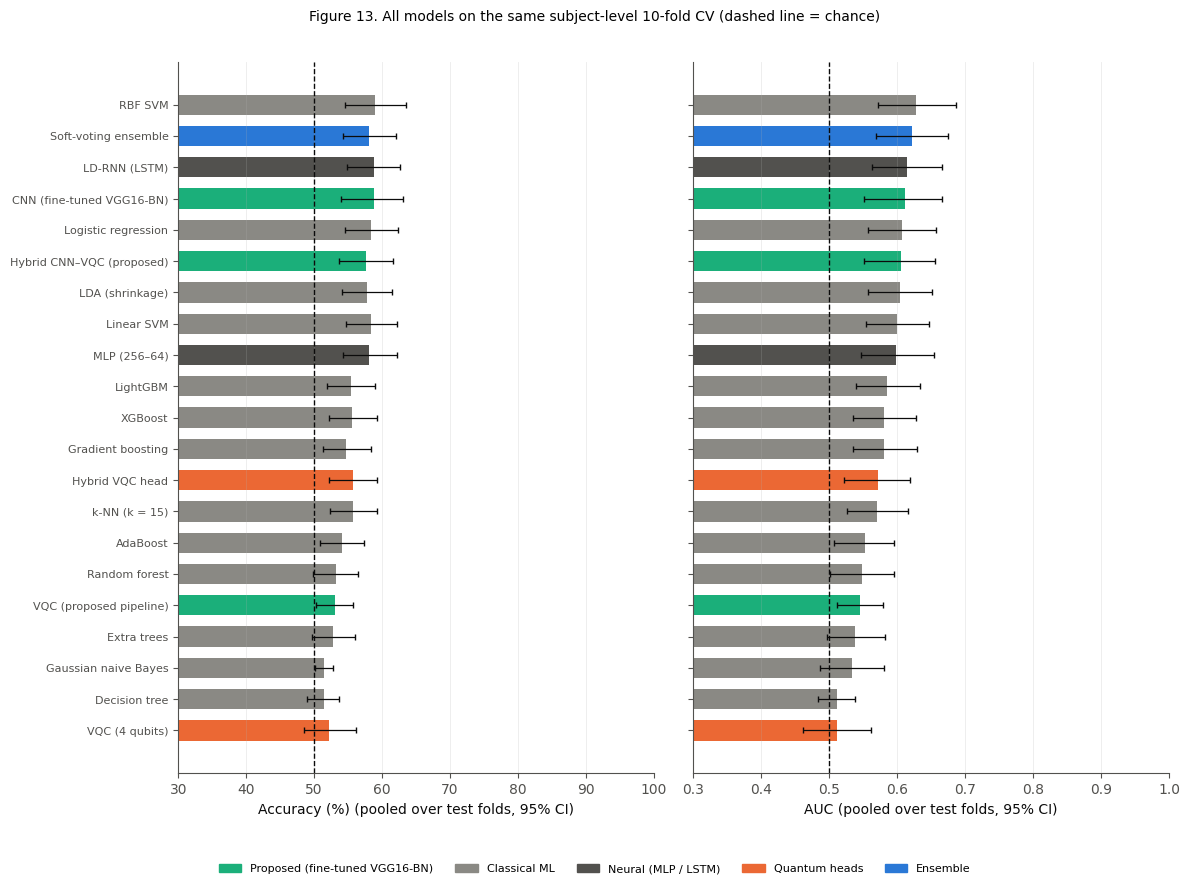

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier,
                              HistGradientBoostingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split

ZOO_NAMES = {"logreg": "Logistic regression", "lda": "LDA (shrinkage)", "gnb": "Gaussian naive Bayes",
             "knn": "k-NN (k = 15)", "dtree": "Decision tree", "svm_linear": "Linear SVM", "svm_rbf": "RBF SVM",
             "rf": "Random forest", "extra_trees": "Extra trees", "adaboost": "AdaBoost", "hgb": "Gradient boosting",
             "xgboost": "XGBoost", "lightgbm": "LightGBM", "mlp": "MLP (256–64)", "ldrnn": "LD-RNN (LSTM)",
             "vqc_dual": f"VQC ({N_QUBITS} qubits)", "hybrid_dual": "Hybrid VQC head", "ensemble": "Soft-voting ensemble"}
ZOO_FAMILY = {**{k: "Classical ML" for k in ("logreg", "lda", "gnb", "knn", "dtree", "svm_linear", "svm_rbf", "rf",
                                              "extra_trees", "adaboost", "hgb", "xgboost", "lightgbm")},
              "mlp": "Neural (MLP / LSTM)", "ldrnn": "Neural (MLP / LSTM)", "vqc_dual": "Quantum heads",
              "hybrid_dual": "Quantum heads", "ensemble": "Ensemble"}
FAMILY_COLORS = {"Proposed (fine-tuned VGG16-BN)": COLORS["hybrid"], "Classical ML": "#8a8984",
                 "Neural (MLP / LSTM)": "#52514e", "Quantum heads": COLORS["vqc"], "Ensemble": COLORS["cnn"]}
try:
    from xgboost import XGBClassifier
except Exception:
    XGBClassifier = None
try:
    from lightgbm import LGBMClassifier
except Exception:
    LGBMClassifier = None


class DecisionSigmoid:
    """SVM scores as probabilities: p = 1 / (1 + exp(-decision value)). The 0.5 threshold equals the SVM's own decision
    rule, and no internal (image-level, subject-mixing) calibration split is needed."""

    def __init__(self, est):
        self.est = est

    def fit(self, X, y_):
        self.est.fit(X, y_)
        return self

    def predict_proba(self, X):
        p = 1.0 / (1.0 + np.exp(-np.clip(self.est.decision_function(X), -30, 30)))
        return np.column_stack([1 - p, p])


def make_classifier(key, seed):
    """Classical classifiers with hyper-parameters fixed in advance (no tuning on test folds)."""
    if key == "logreg":
        return LogisticRegression(C=0.05, max_iter=5000)
    if key == "lda":
        return LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
    if key == "gnb":
        return GaussianNB()
    if key == "knn":
        return KNeighborsClassifier(n_neighbors=15, weights="distance")
    if key == "dtree":
        return DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=seed)
    if key == "svm_linear":
        return DecisionSigmoid(LinearSVC(C=0.01, max_iter=20000))
    if key == "svm_rbf":
        return DecisionSigmoid(SVC(kernel="rbf", C=1.0, gamma="scale"))
    if key == "rf":
        return RandomForestClassifier(n_estimators=ML_TREES, min_samples_leaf=2, n_jobs=-1, random_state=seed)
    if key == "extra_trees":
        return ExtraTreesClassifier(n_estimators=ML_TREES, min_samples_leaf=2, n_jobs=-1, random_state=seed)
    if key == "adaboost":
        return AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=seed)
    if key == "hgb":
        return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=seed)
    if key == "xgboost" and XGBClassifier is not None:
        return XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.5,
                             tree_method="hist", eval_metric="logloss", random_state=seed, n_jobs=-1)
    if key == "lightgbm" and LGBMClassifier is not None:
        return LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.5, random_state=seed, verbose=-1, n_jobs=-1)
    if key == "mlp":
        return MLPClassifier(hidden_layer_sizes=(256, 64), alpha=1e-3, early_stopping=True, max_iter=300, random_state=seed)
    return None


class LDRNN(nn.Module):
    """LD-RNN classifier (Thatere & Reddy, Eq. 6-17): projection -> LSTM(128) -> dense 128 -> 64 -> softmax."""

    def __init__(self, d_in, n_cls=2):
        super().__init__()
        self.proj = nn.Linear(d_in, 512)
        self.lstm = nn.LSTM(512, 128, batch_first=True)
        self.drop1, self.drop2 = nn.Dropout(0.3), nn.Dropout(0.3)
        self.fc1, self.fc2, self.out = nn.Linear(128, 128), nn.Linear(128, 64), nn.Linear(64, n_cls)

    def forward(self, x):
        h = F.relu(self.proj(x)).unsqueeze(1)            # the PCA vector as one time step (as in the paper)
        _, (hT, _) = self.lstm(h)
        z = F.relu(self.fc1(self.drop1(hT[-1])))
        return self.out(self.drop2(F.relu(self.fc2(z))))


def train_ldrnn(Ztr, ytr, Zva, yva, seed):
    set_seed(seed)
    m = LDRNN(Ztr.shape[1]).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), lr=LDRNN_LR)
    xt, yt_ = torch.tensor(Ztr, device=DEVICE), torch.tensor(ytr, device=DEVICE)
    xv, yv_ = torch.tensor(Zva, device=DEVICE), torch.tensor(yva, device=DEVICE)
    g = torch.Generator(); g.manual_seed(seed)
    best, best_state, wait = float("inf"), None, 0
    for ep in range(LDRNN_EPOCHS):
        m.train()
        perm = torch.randperm(len(yt_), generator=g)
        for s in range(0, len(perm), LDRNN_BATCH):
            b = perm[s:s + LDRNN_BATCH].to(DEVICE)
            if len(b) < 2:
                continue
            opt.zero_grad()
            F.cross_entropy(m(xt[b]), yt_[b]).backward()
            opt.step()
        m.eval()
        with torch.no_grad():
            vl = F.cross_entropy(m(xv), yv_).item()
        if vl < best - 1e-5:
            best, wait, best_state = vl, 0, {k: v.detach().clone() for k, v in m.state_dict().items()}
        else:
            wait += 1
            if wait >= LDRNN_PATIENCE:
                break
    m.load_state_dict(best_state)
    return m


@torch.no_grad()
def ldrnn_predict(m, Z):
    m.eval()
    return torch.softmax(m(torch.tensor(Z, device=DEVICE)), 1)[:, 1].cpu().numpy()


# ---- 1) frozen ImageNet features (computed once; labels are not used) ----
def build_frozen(arch):
    net = getattr(torchvision.models, arch)(weights="DEFAULT" if PRETRAINED else None)
    if arch.startswith("densenet"):
        body = nn.Sequential(net.features, nn.ReLU(inplace=True), nn.AdaptiveAvgPool2d(1), nn.Flatten())
    elif arch.startswith("vit") or arch.startswith("swin"):
        for attr in ("heads", "head"):                       # drop the ImageNet classification layer
            if hasattr(net, attr):
                setattr(net, attr, nn.Identity())
        body = net
    else:                                                    # ResNet family: everything up to global average pooling
        body = nn.Sequential(*list(net.children())[:-1], nn.Flatten())
    return nn.Sequential(InputAdapter(), body).to(DEVICE).eval()


@torch.no_grad()
def extract_features(model, idx, bs=48):
    out = []
    for s in range(0, len(idx), bs):
        xb = to_batch(idx[s:s + bs])
        if xb.shape[-1] != 224:                              # ImageNet backbones (ViT in particular) expect 224 x 224
            xb = F.interpolate(xb, size=(224, 224), mode="bilinear", align_corners=False)
        with (torch.autocast(device_type="cuda", dtype=torch.float16) if AMP_ON else contextlib.nullcontext()):
            out.append(model(xb).float().cpu().numpy())
    return np.concatenate(out).astype(np.float32)


def make_reducer(F_fit, seed):
    """Feature standardisation -> PCA (ML_PCA components, NOT whitened) -> division by one global SD.
    Whitening would give the low-variance (noise) components the same weight as the leading ones, which breaks
    distance- and kernel-based classifiers (k-NN, RBF SVM)."""
    sc = StandardScaler().fit(F_fit)
    n_comp = int(min(ML_PCA, len(F_fit) - 1, F_fit.shape[1]))
    pca = PCA(n_components=n_comp, random_state=seed).fit(sc.transform(F_fit))
    g = float(pca.transform(sc.transform(F_fit)).std()) + 1e-8
    return lambda idx: (pca.transform(sc.transform(Fz[idx])) / g).astype(np.float32)


ZOO, ZOO_ERR, ZOO_TIME, LEAK_ROWS, FEAT_INFO = {}, defaultdict(list), defaultdict(list), [], {}
ACTIVE = [k for k in ML_MODELS if k in ZOO_NAMES]
if "xgboost" in ACTIVE and XGBClassifier is None:
    print("xgboost is not installed -> skipped"); ACTIVE.remove("xgboost")
if "lightgbm" in ACTIVE and LGBMClassifier is None:
    print("lightgbm is not installed -> skipped"); ACTIVE.remove("lightgbm")
ENS = [k for k in ENSEMBLE_MEMBERS if k in ACTIVE] or [k for k in ("hgb",) if k in ACTIVE]
if "lightgbm" in ENSEMBLE_MEMBERS and "lightgbm" not in ACTIVE and "hgb" in ACTIVE and "hgb" not in ENS:
    ENS.append("hgb")                                        # same family substitute, decided by availability only

if RUN_ML_BENCHMARK:
    ALL = np.arange(len(y))
    for fs_name, archs in ML_FEATURE_SETS.items():
        t0 = time.time(); parts = []
        for arch in archs:
            try:
                fm = build_frozen(arch)
            except Exception as e:
                raise SystemExit(f"Could not load {arch} with ImageNet weights ({type(e).__name__}: {e}). Kaggle: Internet ON.")
            parts.append(extract_features(fm, ALL)); del fm
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        Fz = np.concatenate(parts, 1)
        FEAT_INFO[fs_name] = dict(backbones=" + ".join(archs), dims=" + ".join(str(p_.shape[1]) for p_ in parts),
                                  total=Fz.shape[1], minutes=(time.time() - t0) / 60)
        print(f"[{fs_name}] features {Fz.shape} ({FEAT_INFO[fs_name]['dims']}) in {FEAT_INFO[fs_name]['minutes']:.1f} min")

        # ---- 2) every classifier on the same subject-level folds ----
        ZP = {k: np.full(len(y), np.nan) for k in ACTIVE}
        for k_, fold in enumerate(FOLDS):
            seed = SEED + 100 * k_
            tr, va, te = fold["train"], fold["val"], fold["test"]
            fit = np.concatenate([tr, va])                   # classical models: training + validation subjects
            Zf = make_reducer(Fz[fit], seed)                  # standardise -> PCA -> one global scale, fitted on `fit` only
            Z_fit, Z_tr, Z_va, Z_te = Zf(fit), Zf(tr), Zf(va), Zf(te)
            for key in ACTIVE:
                if key in ("ldrnn", "vqc_dual", "hybrid_dual", "ensemble"):
                    continue
                t1 = time.time()
                try:
                    clf = make_classifier(key, seed).fit(Z_fit, y[fit])
                    ZP[key][te] = clf.predict_proba(Z_te)[:, 1]
                except Exception as e:                       # one failing library must not stop the benchmark
                    ZOO_ERR[key].append(f"fold {k_ + 1}: {type(e).__name__}: {e}")
                ZOO_TIME[(fs_name, key)].append(time.time() - t1)
            if "ldrnn" in ACTIVE:                            # LSTM: early stopping on the validation subjects
                t1 = time.time()
                ZP["ldrnn"][te] = ldrnn_predict(train_ldrnn(Z_tr, y[tr], Z_va, y[va], seed + 31), Z_te)
                ZOO_TIME[(fs_name, "ldrnn")].append(time.time() - t1)
            if "vqc_dual" in ACTIVE or "hybrid_dual" in ACTIVE:
                # the quantum heads of this paper on the same features: PCA (N_PCA) fitted on the training subjects
                pq = PCA(n_components=int(min(N_PCA, len(tr) - 1)), random_state=seed).fit(Fz[tr])
                Q_tr, Q_va, Q_te = (pq.transform(Fz[i_]) for i_ in (tr, va, te))
                scq = StandardScaler().fit(Q_tr)
                mmq = MinMaxScaler((0, np.pi)).fit(Q_tr[:, :N_QUBITS])
                qs = [np.clip(mmq.transform(a[:, :N_QUBITS]), 0, np.pi) for a in (Q_tr, Q_va, Q_te)]
                cs = [scq.transform(a) for a in (Q_tr, Q_va, Q_te)]
                if "vqc_dual" in ACTIVE:
                    t1 = time.time()
                    mq, _, _ = train_head(lambda: VQCClassifier(N_QUBITS), [qs[0]], y[tr], [qs[1]], y[va], seed + 41)
                    ZP["vqc_dual"][te] = head_predict(mq, [qs[2]])
                    ZOO_TIME[(fs_name, "vqc_dual")].append(time.time() - t1)
                if "hybrid_dual" in ACTIVE:
                    t1 = time.time()
                    mh, _, _ = train_head(lambda: HybridHead(N_QUBITS, d=cs[0].shape[1]), [cs[0], qs[0]], y[tr],
                                          [cs[1], qs[1]], y[va], seed + 42)
                    ZP["hybrid_dual"][te] = head_predict(mh, [cs[2], qs[2]])
                    ZOO_TIME[(fs_name, "hybrid_dual")].append(time.time() - t1)
            if "ensemble" in ACTIVE:
                members = [ZP[m_][te] for m_ in ENS if m_ in ZP and np.isfinite(ZP[m_][te]).all()]
                if members:
                    ZP["ensemble"][te] = np.mean(members, 0)
            acc = {key: round(100 * float(((ZP[key][te] >= 0.5) == y[te]).mean()), 1) for key in ACTIVE
                   if np.isfinite(ZP[key][te]).all()}
            print(f"  [{fs_name}] fold {k_ + 1}/{N_FOLDS} test accuracy %:", acc)
        for key in ACTIVE:
            if np.isfinite(ZP[key]).all():
                ZOO[(fs_name, key)] = ZP[key]
            elif ZOO_ERR[key]:
                print(f"  {key} skipped ({len(ZOO_ERR[key])} failed folds): {ZOO_ERR[key][0]}")

        # ---- 3) leakage demonstration: the LD-RNN study's protocol (random 80:20 IMAGE split, PCA before the split) ----
        if LEAKAGE_DEMO:
            tr_i, te_i = train_test_split(ALL, test_size=0.2, stratify=y, random_state=SEED)
            shared = len(set(groups[tr_i]) & set(groups[te_i]))
            Zall = make_reducer(Fz, SEED)(ALL)                                   # fitted on ALL images, as in the paper
            for key in [k for k in ("logreg", "svm_rbf", "ldrnn") if k in ACTIVE]:
                if key == "ldrnn":
                    tr2, va2 = train_test_split(tr_i, test_size=0.1, stratify=y[tr_i], random_state=SEED)
                    pl = ldrnn_predict(train_ldrnn(Zall[tr2], y[tr2], Zall[va2], y[va2], SEED), Zall[te_i])
                else:
                    pl = make_classifier(key, SEED).fit(Zall[tr_i], y[tr_i]).predict_proba(Zall[te_i])[:, 1]
                if (fs_name, key) in ZOO:
                    LEAK_ROWS.append(dict(features=fs_name, key=key, leaky=100 * float(((pl >= 0.5) == y[te_i]).mean()),
                                          honest=100 * float(((ZOO[(fs_name, key)] >= 0.5) == y).mean()),
                                          shared=shared, n_groups=len(np.unique(groups))))

# ---- 4) metrics on the same footing as the main models (image level, pooled CI, subject level) ----
def full_metrics(p):
    r = pd.DataFrame([binary_metrics(y[f["test"]], p[f["test"]]) for f in FOLDS])
    sb = pd.DataFrame({"g": df.subject.values, "y": y, "p": p}).groupby("g").mean()
    return dict(fold=r, mean={k: r[k].mean() for k in KEYS}, sd={k: r[k].std(ddof=1) for k in KEYS},
                pooled=binary_metrics(y, p),
                acc_ci=100 * group_bootstrap_ci(y, p, groups, lambda a, b: np.mean((b >= 0.5) == a)),
                auc_ci=group_bootstrap_ci(y, p, groups, roc_auc_score),
                subj=binary_metrics(sb.y.values.astype(int), sb.p.values))


BENCH = {("proposed", m): full_metrics(P[m]) for m in ("cnn", "vqc", "hybrid")}
BENCH.update({k: full_metrics(p) for k, p in ZOO.items()})
BENCH_NAME = {("proposed", "cnn"): "CNN (fine-tuned VGG16-BN)", ("proposed", "vqc"): "VQC (proposed pipeline)",
              ("proposed", "hybrid"): "Hybrid CNN–VQC (proposed)"}
BENCH_NAME.update({k: ZOO_NAMES[k[1]] + (f" [{k[0]}]" if len(ML_FEATURE_SETS) > 1 else "") for k in ZOO})
BENCH_FAMILY = {k: ("Proposed (fine-tuned VGG16-BN)" if k[0] == "proposed" else ZOO_FAMILY[k[1]]) for k in BENCH}
_ms = lambda b, k, nd: f"{b['mean'][k]:.{nd}f} ± {b['sd'][k]:.{nd}f}"
TABLE9 = pd.DataFrame([{
    "Model": BENCH_NAME[k], "Features": ("fine-tuned VGG16-BN fc7 → PCA" if k[0] == "proposed" else
                                         f"{FEAT_INFO[k[0]]['backbones']} (frozen) → PCA"),
    "Accuracy (%)": _ms(b, "accuracy", 1), "Pooled accuracy (95% CI)": f"{b['pooled']['accuracy']:.1f} ({b['acc_ci'][0]:.1f}–{b['acc_ci'][1]:.1f})",
    "AUC": _ms(b, "auc", 3), "Sensitivity (%)": _ms(b, "recall", 1), "Specificity (%)": _ms(b, "specificity", 1),
    "F1 (%)": _ms(b, "f1", 1), "Subject-level accuracy (%)": round(b["subj"]["accuracy"], 1),
    "Subject-level AUC": round(b["subj"]["auc"], 3),
    "Time per fold (s)": (round(float(np.mean(ZOO_TIME[k])), 1) if k in ZOO_TIME else
                          round(60 * TIME_MEAN[k[1]] + (60 * TIME_MEAN["cnn"] if k[1] != "cnn" else 0), 1) if k[0] == "proposed" else
                          round(float(sum(np.mean(ZOO_TIME[(k[0], m)]) for m in ENS if (k[0], m) in ZOO_TIME)), 1))}
    for k, b in BENCH.items()])
TABLE9.to_csv(os.path.join(OUT_DIR, "tables", "table9_ml_benchmark.csv"), index=False)
display(TABLE9)

# Friedman test over folds (all models), and the proposed hybrid vs the best benchmark model
acc_mat = np.array([[b["fold"].accuracy.values[f] for b in BENCH.values()] for f in range(N_FOLDS)])
FRIEDMAN = stats.friedmanchisquare(*acc_mat.T) if acc_mat.shape[1] >= 3 else None
zoo_keys = [k for k in BENCH if k[0] != "proposed"]
BEST_ZOO = max(zoo_keys, key=lambda k: BENCH[k]["mean"]["auc"]) if zoo_keys else None
BEST_TEST = {}
if BEST_ZOO:
    sb = pd.DataFrame({"g": df.subject.values, "y": y, "h": P["hybrid"], "z": ZOO[BEST_ZOO]}).groupby("g").mean()
    BEST_TEST = dict(zip(("hyb_only", "zoo_only", "p_subj"), mcnemar_exact(sb.y.values.astype(int), sb.h.values, sb.z.values)))
    BEST_TEST["delong_p"] = delong_test(y, P["hybrid"], ZOO[BEST_ZOO])
    print(f"Best benchmark model (highest mean AUC, chosen after testing - descriptive): {BENCH_NAME[BEST_ZOO]}; "
          f"hybrid vs it: subject-level McNemar p = {BEST_TEST['p_subj']:.3g}, DeLong p = {BEST_TEST['delong_p']:.3g}")
if FRIEDMAN is not None:
    print(f"Friedman test over {N_FOLDS} folds and {acc_mat.shape[1]} models: chi2 = {FRIEDMAN.statistic:.2f}, p = {FRIEDMAN.pvalue:.4g}")

LEAK_TABLE = pd.DataFrame([{
    "Model": ZOO_NAMES[r["key"]] + (f" [{r['features']}]" if len(ML_FEATURE_SETS) > 1 else ""),
    "Random 80:20 image split, PCA on all images (LD-RNN protocol) – accuracy (%)": round(r["leaky"], 1),
    f"Subject-level {N_FOLDS}-fold CV – accuracy (%)": round(r["honest"], 1),
    "Inflation (points)": round(r["leaky"] - r["honest"], 1),
    "Subjects with slices in both training and test set": f"{r['shared']} of {r['n_groups']}"} for r in LEAK_ROWS])
if len(LEAK_TABLE):
    LEAK_TABLE.to_csv(os.path.join(OUT_DIR, "tables", "table10_leakage_demonstration.csv"), index=False)
    print("Table 10 - leakage demonstration (NOT performance results):"); display(LEAK_TABLE)

# Figure 13: accuracy and AUC with 95% CIs (subject bootstrap), all models
if len(BENCH) > 3:
    order = sorted(BENCH, key=lambda k: BENCH[k]["pooled"]["auc"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 0.34 * len(order) + 1.6), sharey=True)
    for ax, (met, ci, lab, chance) in zip(axes, (("accuracy", "acc_ci", "Accuracy (%)", 50), ("auc", "auc_ci", "AUC", 0.5))):
        vals = [BENCH[k]["pooled"][met] for k in order]
        lo = [v - BENCH[k][ci][0] for v, k in zip(vals, order)]; hi = [BENCH[k][ci][1] - v for v, k in zip(vals, order)]
        ax.barh(range(len(order)), vals, color=[FAMILY_COLORS[BENCH_FAMILY[k]] for k in order], height=0.65)
        ax.errorbar(vals, range(len(order)), xerr=[lo, hi], fmt="none", ecolor="#0b0b0b", elinewidth=0.9, capsize=2)
        ax.axvline(chance, color="#0b0b0b", ls="--", lw=1)
        ax.set(xlabel=lab + " (pooled over test folds, 95% CI)", xlim=((30, 100) if met == "accuracy" else (0.3, 1.0)))
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(range(len(order))); axes[0].set_yticklabels([BENCH_NAME[k] for k in order], fontsize=8)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLORS.values()]
    fig.legend(handles, list(FAMILY_COLORS), loc="lower center", ncol=5, fontsize=8, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(f"Figure 13. All models on the same subject-level {N_FOLDS}-fold CV (dashed line = chance)", fontsize=10)
    fig.tight_layout(rect=(0, 0.04, 1, 0.97)); FIGS["fig13"] = savefig(fig, "fig13_ml_benchmark")

## 11. Figures 5, 9, 10, 11, S1, S2 (R3-4, R1-4, R2-2)
All ROC curves are **empirical**. They are computed with `sklearn.metrics.roc_curve` from the predicted probabilities on the test folds. The thin lines are individual folds; the thick line is the mean curve over folds.

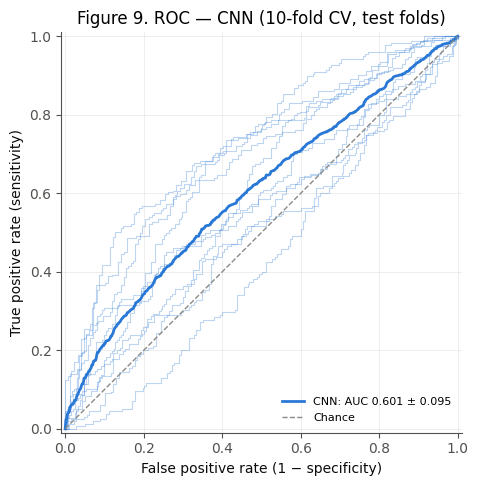

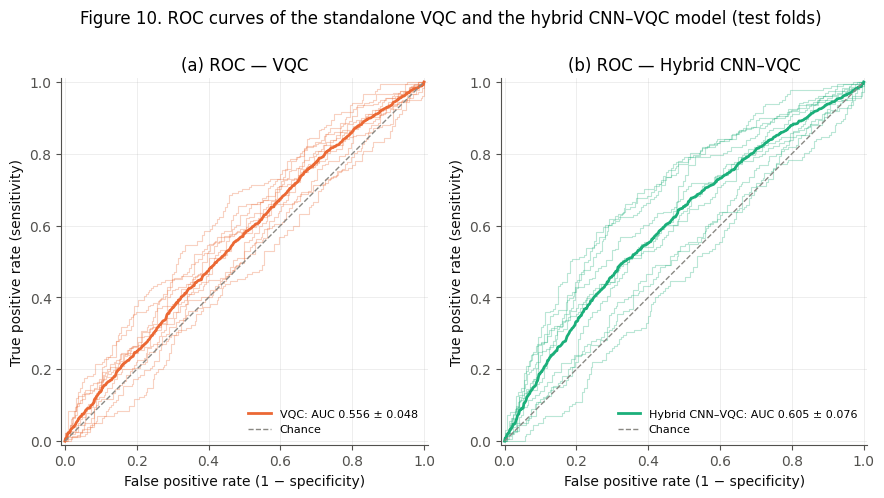

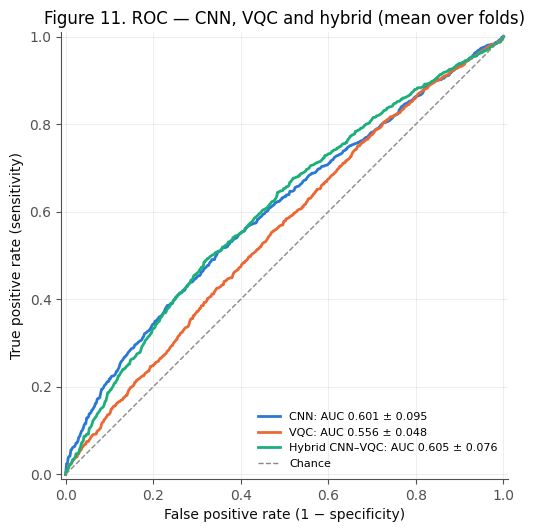

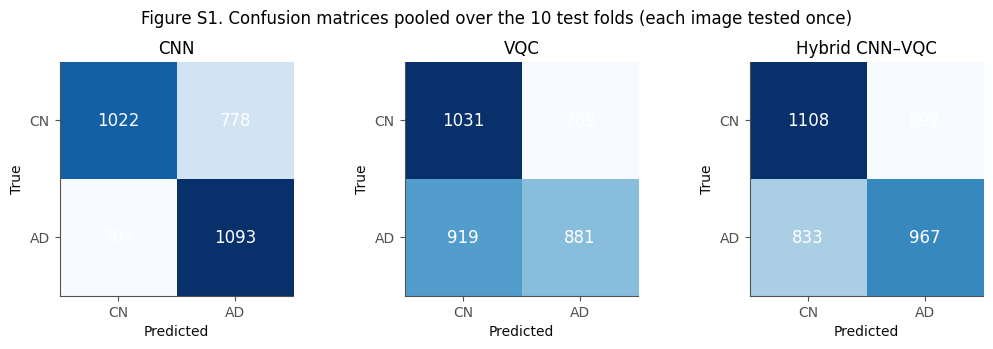

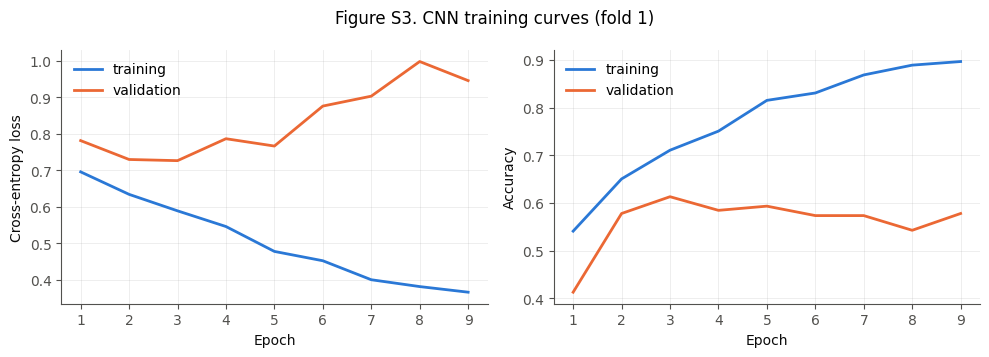

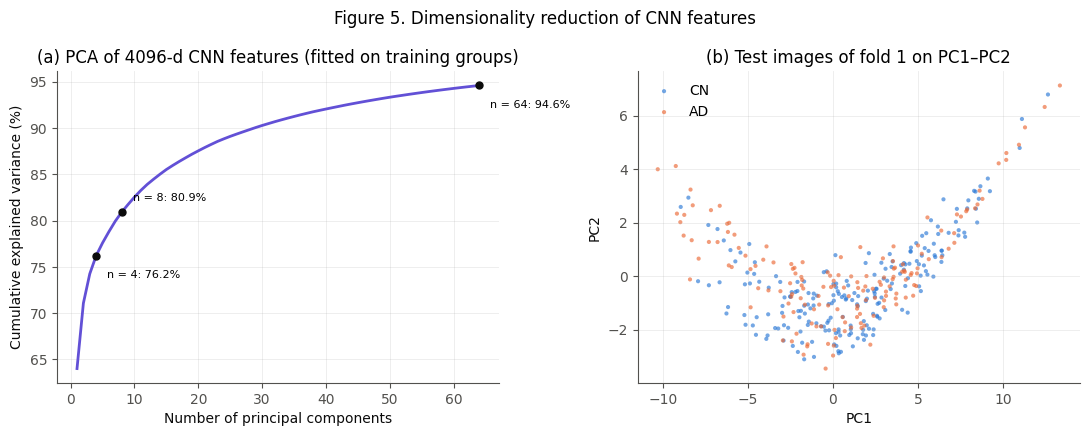

,n_qubits,cumulative_variance_pct,val_accuracy_mean,val_accuracy_sd,val_auc_mean,val_auc_sd,trainable_params,train_time_s
0,4,78.115997,53.951,3.771,0.551,0.049,22,12.980
1,5,79.469002,53.712,4.180,0.548,0.054,27,17.314
2,6,80.572998,55.079,3.295,0.564,0.046,32,18.947
3,7,81.558998,55.505,4.029,0.567,0.051,37,34.429
4,8,82.436996,54.968,4.126,0.566,0.049,42,39.479


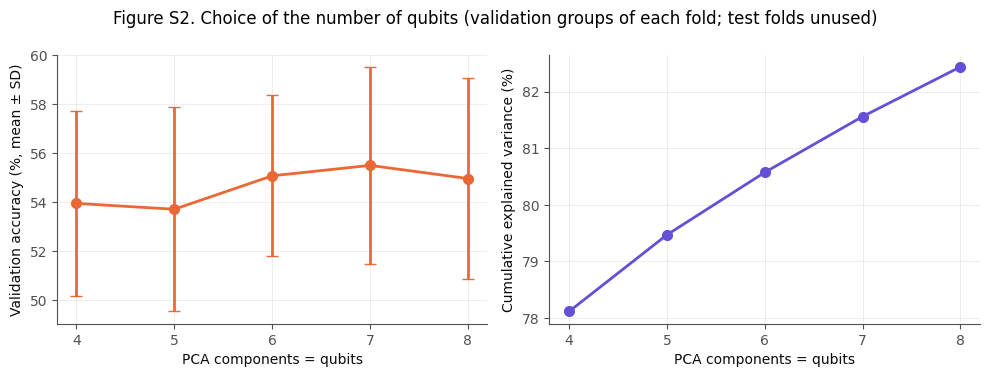

NOTE: n = 7 had the best mean validation accuracy. If you want to use it, set N_QUBITS = 7 and re-run; the choice uses validation data only.


In [22]:
def roc_panel(ax, m, folds_thin=True):
    grid, tprs = np.linspace(0, 1, 501), []
    for f in FOLDS:
        fpr, tpr, _ = roc_curve(y[f["test"]], P[m][f["test"]])
        if folds_thin:
            ax.plot(fpr, tpr, color=COLORS[m], lw=0.8, alpha=0.3)
        ti = np.interp(grid, fpr, tpr); ti[0] = 0; tprs.append(ti)
    mean = np.mean(tprs, 0); mean[-1] = 1
    ax.plot(grid, mean, color=COLORS[m], lw=2, label=f"{NAMES[m]}: AUC {fmt(m, 'auc')}")


def roc_style(ax, title):
    ax.plot([0, 1], [0, 1], ls="--", color="#8a8984", lw=1, label="Chance")
    ax.set(xlim=(-0.01, 1.01), ylim=(-0.01, 1.01), xlabel="False positive rate (1 − specificity)",
           ylabel="True positive rate (sensitivity)", title=title)
    ax.set_aspect("equal"); ax.legend(loc="lower right", fontsize=8)


fig, ax = plt.subplots(figsize=(5.2, 5.2)); roc_panel(ax, "cnn")
roc_style(ax, f"Figure 9. ROC — CNN ({N_FOLDS}-fold CV, test folds)"); FIGS["fig09"] = savefig(fig, "fig09_roc_cnn")
fig, axes = plt.subplots(1, 2, figsize=(10.4, 5.2))
for ax, m, l in zip(axes, ("vqc", "hybrid"), "ab"):
    roc_panel(ax, m); roc_style(ax, f"({l}) ROC — {NAMES[m]}")
fig.suptitle("Figure 10. ROC curves of the standalone VQC and the hybrid CNN–VQC model (test folds)")
FIGS["fig10"] = savefig(fig, "fig10_roc_vqc_hybrid")
fig, ax = plt.subplots(figsize=(5.8, 5.8))
for m in ("cnn", "vqc", "hybrid"):
    roc_panel(ax, m, folds_thin=False)
roc_style(ax, "Figure 11. ROC — CNN, VQC and hybrid (mean over folds)"); FIGS["fig11"] = savefig(fig, "fig11_roc_all_models")

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
for ax, m in zip(axes, ("cnn", "vqc", "hybrid")):
    q = S[m]["pooled"]; cm = np.array([[q["tn"], q["fp"]], [q["fn"], q["tp"]]])
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["CN", "AD"], yticklabels=["CN", "AD"],
           xlabel="Predicted", ylabel="True", title=f"{NAMES[m]}")
fig.suptitle(f"Figure S1. Confusion matrices pooled over the {N_FOLDS} test folds (each image tested once)")
fig.tight_layout(); FIGS["figS1"] = savefig(fig, "figS1_confusion_matrices")

h0 = HIST[HIST.fold == 0]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, met in zip(axes, ("loss", "acc")):
    ax.plot(h0.epoch, h0[f"train_{met}"], color=COLORS["cnn"], lw=2, label="training")
    ax.plot(h0.epoch, h0[f"val_{met}"], color=COLORS["vqc"], lw=2, label="validation")
    ax.set(xlabel="Epoch", ylabel="Cross-entropy loss" if met == "loss" else "Accuracy"); ax.legend()
fig.suptitle("Figure S3. CNN training curves (fold 1)"); fig.tight_layout()
FIGS["figS3"] = savefig(fig, "figS3_cnn_training_curves")

pca0 = KEEP["pca"]; cum0 = np.cumsum(pca0.explained_variance_ratio_) * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].plot(np.arange(1, N_PCA + 1), cum0, color="#6250d6", lw=2)
for j, n in enumerate(sorted({N_QUBITS, 8, N_PCA} & set(range(1, N_PCA + 1)))):
    axes[0].plot(n, cum0[n - 1], "o", color="#0b0b0b", ms=5)
    axes[0].annotate(f"n = {n}: {cum0[n - 1]:.1f}%", (n, cum0[n - 1]), xytext=(8, -16 if j % 2 == 0 else 8),
                     textcoords="offset points", fontsize=8)
axes[0].set(xlabel="Number of principal components", ylabel="Cumulative explained variance (%)",
            title="(a) PCA of 4096-d CNN features (fitted on training groups)")
Zp = KEEP["Z_te"][:, :2]; yte0 = y[KEEP["fold"]["test"]]
for lab in (0, 1):
    axes[1].scatter(Zp[yte0 == lab, 0], Zp[yte0 == lab, 1], s=9, alpha=0.65, color=CLASS_COLORS[lab],
                    label="CN" if lab == 0 else "AD", edgecolors="none")
axes[1].set(xlabel="PC1", ylabel="PC2", title="(b) Test images of fold 1 on PC1–PC2"); axes[1].legend()
fig.suptitle("Figure 5. Dimensionality reduction of CNN features"); fig.tight_layout()
FIGS["fig05"] = savefig(fig, "fig05_pca")

if RUN_QUBIT_SWEEP:
    SW = pd.DataFrame(SWEEP)
    TABLE8 = SW.groupby("n_qubits").agg(cumulative_variance_pct=("cumulative_variance_pct", "mean"),
                                        val_accuracy_mean=("val_accuracy", "mean"), val_accuracy_sd=("val_accuracy", "std"),
                                        val_auc_mean=("val_auc", "mean"), val_auc_sd=("val_auc", "std"),
                                        trainable_params=("trainable_params", "first"),
                                        train_time_s=("train_time_s", "mean")).reset_index()
    BEST_N = int(TABLE8.loc[TABLE8.val_accuracy_mean.idxmax(), "n_qubits"])
    TABLE8.round(3).to_csv(os.path.join(OUT_DIR, "tables", "table8_qubit_sweep.csv"), index=False)
    display(TABLE8.round(3))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    axes[0].errorbar(TABLE8.n_qubits, TABLE8.val_accuracy_mean, yerr=TABLE8.val_accuracy_sd, fmt="o-",
                     color=COLORS["vqc"], lw=2, capsize=4, ms=7)
    axes[0].set(xlabel="PCA components = qubits", ylabel="Validation accuracy (%, mean ± SD)", xticks=TABLE8.n_qubits)
    axes[1].plot(TABLE8.n_qubits, TABLE8.cumulative_variance_pct, "o-", color="#6250d6", lw=2, ms=7)
    axes[1].set(xlabel="PCA components = qubits", ylabel="Cumulative explained variance (%)", xticks=TABLE8.n_qubits)
    fig.suptitle("Figure S2. Choice of the number of qubits (validation groups of each fold; test folds unused)")
    fig.tight_layout(); FIGS["figS2"] = savefig(fig, "figS2_qubit_sweep")
    if BEST_N != N_QUBITS:
        print(f"NOTE: n = {BEST_N} had the best mean validation accuracy. If you want to use it, set N_QUBITS = {BEST_N} "
              "and re-run; the choice uses validation data only.")

## 12. Grad-CAM explanations for the CNN *and* for the hybrid decision (R1-8, R3-6)
- **CNN Grad-CAM** uses the gradient of the CNN's own output with respect to the last convolutional block (Eq. 16).
- **Hybrid Grad-CAM** uses the gradient of the **hybrid model's** output. It is back-propagated through the softmax layer, the simulated VQC, the frozen min–max scaling, the frozen standardisation, the frozen linear PCA projection and the CNN, down to the same convolutional maps. This explains the hybrid decision directly.

The notebook then measures how similar the two explanations are (Pearson *r* per test image). It also measures how much of the top-20% activation falls inside the head (foreground) mask, compared with the mask's share of the image. This is a sanity check against background shortcuts, not a biomarker validation.

End-to-end hybrid vs pipeline predictions: max |dp| = 8.05e-07
{
 "n": 367,
 "r_mean": 0.401,
 "r_sd": 0.3241,
 "r_median": 0.4563,
 "inside_cnn": 78.6402,
 "inside_hyb": 77.7247,
 "area": 41.3279,
 "e2e_diff": 0.0,
 "wilcoxon_p": 0.0
}


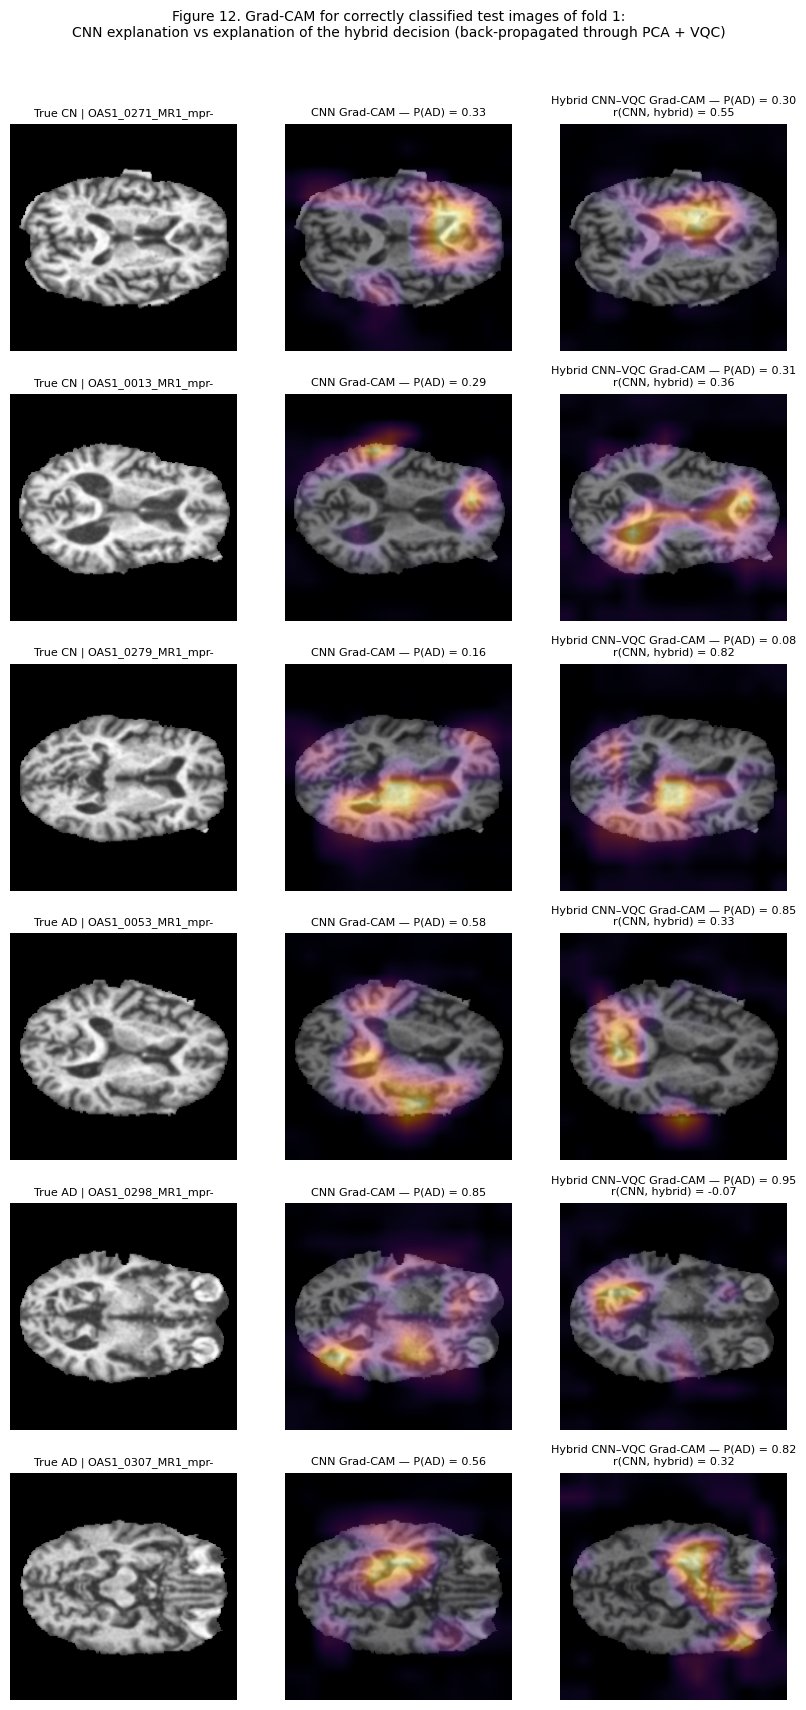

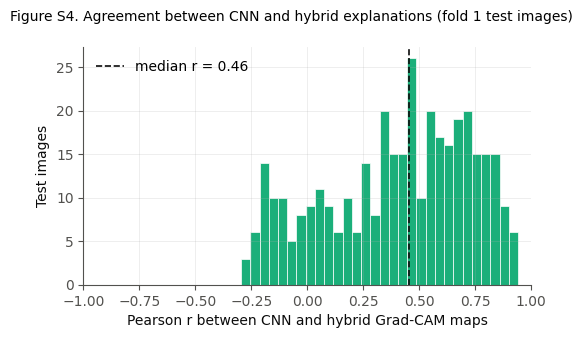

Grad-CAM agreement computed on 367 of 367 test images (constant maps skipped)


In [23]:
class HybridEndToEnd(nn.Module):
    """CNN conv maps -> fc1 -> PCA -> (standardised 64 comps, min-max scaled n comps -> VQC) -> softmax."""

    def __init__(self, cnn, pca, sc, mm, head):
        super().__init__()
        self.cnn, self.head = cnn, head
        f64 = lambda a: torch.tensor(np.asarray(a), dtype=torch.float64, device=DEVICE)   # float64 like scikit-learn
        self.register_buffer("pmean", f64(pca.mean_)); self.register_buffer("pW", f64(pca.components_.T))
        self.register_buffer("mu", f64(sc.mean_)); self.register_buffer("sd", f64(sc.scale_))
        self.register_buffer("qmin", f64(mm.data_min_)); self.register_buffer("qscale", f64(mm.scale_))

    def from_maps(self, A):
        z = (self.cnn.embed_from_maps(A).double() - self.pmean) @ self.pW
        zq = torch.clamp((z[:, :N_QUBITS] - self.qmin) * self.qscale, 0, math.pi)
        return self.head(((z - self.mu) / self.sd).float(), zq.float())


def gradcam(model_from_maps, cnn, idx, cls=None, bs=16):
    cams, preds = [], []
    for s in range(0, len(idx), bs):
        xb = to_batch(idx[s:s + bs])
        A = cnn.body(xb).detach().requires_grad_(True)
        logits = model_from_maps(A)
        c = logits.argmax(1) if cls is None else torch.full((len(xb),), cls, device=DEVICE)
        logits.gather(1, c[:, None]).sum().backward()
        w = A.grad.mean((2, 3), keepdim=True)
        cam = F.relu((w * A).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[:, 0]
        mn, mx = cam.amin((1, 2), keepdim=True), cam.amax((1, 2), keepdim=True)
        cams.append(((cam - mn) / (mx - mn + 1e-12)).detach().cpu().numpy())
        preds.append(torch.softmax(logits, 1)[:, 1].detach().cpu().numpy())
    return np.concatenate(cams), np.concatenate(preds)


cnn0 = KEEP["cnn"].eval()
for prm in cnn0.parameters():
    prm.requires_grad_(False)
e2e = HybridEndToEnd(cnn0, KEEP["pca"], KEEP["sc"], KEEP["mm"], copy.deepcopy(KEEP["hyb"]).to(DEVICE).eval()).to(DEVICE).eval()
te0 = KEEP["fold"]["test"]
cam_cnn, pa_cnn = gradcam(lambda A: cnn0.fc2(cnn0.embed_from_maps(A)), cnn0, te0)
cam_hyb, pa_hyb = gradcam(e2e.from_maps, cnn0, te0)
# the end-to-end module must reproduce the hybrid predictions made from pre-computed features
E2E_MAX_DIFF = float(np.abs(pa_hyb - P["hybrid"][te0]).max())
print(f"End-to-end hybrid vs pipeline predictions: max |dp| = {E2E_MAX_DIFF:.2e}")

with np.errstate(invalid="ignore", divide="ignore"):   # constant (all-zero) maps give r = NaN and are skipped
    corr = np.array([np.corrcoef(a.ravel(), b.ravel())[0, 1] for a, b in zip(cam_cnn, cam_hyb)])
masks = MASK[te0]                      # brain mask (skull-stripped) or head mask of each test slice
MASK_NAME = "brain mask" if SKULL_STRIP else "head mask"


def inside_fraction(cams, top=0.2):
    out = []
    for c, m in zip(cams, masks):
        sel = c >= np.quantile(c, 1 - top)
        out.append((sel & m).sum() / max(sel.sum(), 1))
    return np.array(out)


in_cnn, in_hyb, area = inside_fraction(cam_cnn), inside_fraction(cam_hyb), masks.mean((1, 2))
GRADCAM = dict(n=len(te0), r_mean=float(np.nanmean(corr)), r_sd=float(np.nanstd(corr, ddof=1)),
               r_median=float(np.nanmedian(corr)), inside_cnn=100 * in_cnn.mean(), inside_hyb=100 * in_hyb.mean(),
               area=100 * area.mean(), e2e_diff=E2E_MAX_DIFF,
               wilcoxon_p=float(stats.wilcoxon(in_hyb, area, alternative="greater").pvalue) if len(te0) >= 10 else np.nan)
print(json.dumps({k: round(v, 4) for k, v in GRADCAM.items()}, indent=1))

yh_hyb = (P["hybrid"][te0] >= 0.5).astype(int)
ex, rng_ex = [], np.random.default_rng(SEED)
for lab in (0, 1):   # random (not hand-picked) correctly classified examples with non-constant maps
    ok_idx = np.where((y[te0] == lab) & (yh_hyb == lab) & np.isfinite(corr))[0]
    if len(ok_idx) == 0:          # no correctly classified example with informative maps: show any example of the class
        ok_idx = np.where(y[te0] == lab)[0]
    ex += list(rng_ex.choice(ok_idx, min(N_GRADCAM_EXAMPLES, len(ok_idx)), replace=False))
fig, axes = plt.subplots(len(ex), 3, figsize=(8.4, 2.9 * len(ex)))
axes = np.atleast_2d(axes)
for r_, j in enumerate(ex):
    i = te0[j]
    axes[r_, 0].imshow(X[i], cmap="gray")
    axes[r_, 0].set_title(f"True {'AD' if y[i] else 'CN'} | {Path(df.rel[i]).name[:18]}", fontsize=8)
    for c_, (cam, pa, lab) in enumerate(((cam_cnn[j], pa_cnn[j], "CNN"), (cam_hyb[j], pa_hyb[j], "Hybrid CNN–VQC")), 1):
        axes[r_, c_].imshow(X[i], cmap="gray")
        axes[r_, c_].imshow(cam, cmap="inferno", alpha=0.45, vmin=0, vmax=1)
        axes[r_, c_].set_title(f"{lab} Grad-CAM — P(AD) = {pa:.2f}" + (f"\nr(CNN, hybrid) = {corr[j]:.2f}" if c_ == 2 else ""),
                               fontsize=8)
    for a in axes[r_]:
        a.axis("off"); a.grid(False)
fig.suptitle("Figure 12. Grad-CAM for correctly classified test images of fold 1:\n"
             "CNN explanation vs explanation of the hybrid decision (back-propagated through PCA + VQC)", fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.965)); FIGS["fig12"] = savefig(fig, "fig12_gradcam_cnn_vs_hybrid")

fig, ax = plt.subplots(figsize=(5.4, 3.4))
ax.hist(corr[np.isfinite(corr)], bins=30, color=COLORS["hybrid"], edgecolor="white", linewidth=0.5)
ax.axvline(GRADCAM["r_median"], color="#0b0b0b", lw=1.2, ls="--", label=f"median r = {GRADCAM['r_median']:.2f}")
ax.set(xlabel="Pearson r between CNN and hybrid Grad-CAM maps", ylabel="Test images", xlim=(-1, 1)); ax.legend()
fig.suptitle("Figure S4. Agreement between CNN and hybrid explanations (fold 1 test images)", fontsize=10)
fig.tight_layout(); FIGS["figS4"] = savefig(fig, "figS4_gradcam_agreement")
print(f"Grad-CAM agreement computed on {int(np.isfinite(corr).sum())} of {len(corr)} test images (constant maps skipped)")

## 12b. Two more explanation methods: saliency and occlusion maps (Figure 14)
The review by Alam et al. (*Artif. Intell. Rev.* 2026) lists Grad-CAM, saliency maps and occlusion maps among the main explanation methods for AD models. All three are computed here for the **hybrid** decision, on the same randomly chosen test images as Figure 12:
- **Saliency map:** absolute gradient of P(AD) with respect to the input pixels (maximum over the 3 channels, lightly smoothed).
- **Occlusion map:** a black square (1/14 of the image side) slides over the input with 50% overlap. The map shows how much the probability of the predicted class drops when each region is hidden. It is model-agnostic, so it needs no gradients.

Agreement between methods is reported as Pearson *r* with the hybrid Grad-CAM map, and as the share of each map's top-20% that falls inside the brain mask.

,image,true,p_ad,r_gradcam_saliency,r_gradcam_occlusion,r_saliency_occlusion,inside_gradcam,inside_saliency,inside_occlusion,mask_area
0,OAS1_0271_MR1_mpr-1_140.jpg,CN,0.303,0.535,0.724,0.573,0.885,0.831,0.981,0.434
1,OAS1_0013_MR1_mpr-1_129.jpg,CN,0.310,0.414,0.285,0.301,0.845,0.847,0.934,0.416
2,OAS1_0279_MR1_mpr-1_159.jpg,CN,0.076,0.452,0.531,0.598,0.833,0.822,1.000,0.407
3,OAS1_0053_MR1_mpr-1_135.jpg,AD,0.850,0.093,0.233,0.409,0.609,0.735,0.732,0.429
4,OAS1_0298_MR1_mpr-1_119.jpg,AD,0.951,0.134,0.176,0.528,0.777,0.864,0.880,0.414
5,OAS1_0307_MR1_mpr-1_133.jpg,AD,0.816,0.261,0.076,0.083,0.741,0.783,0.080,0.437


Median over examples: {'r_gradcam_saliency': 0.338, 'r_gradcam_occlusion': 0.259, 'r_saliency_occlusion': 0.469, 'inside_gradcam': 0.805, 'inside_saliency': 0.826, 'inside_occlusion': 0.907, 'mask_area': 0.422, 'n': 6, 'seconds': 23.765}


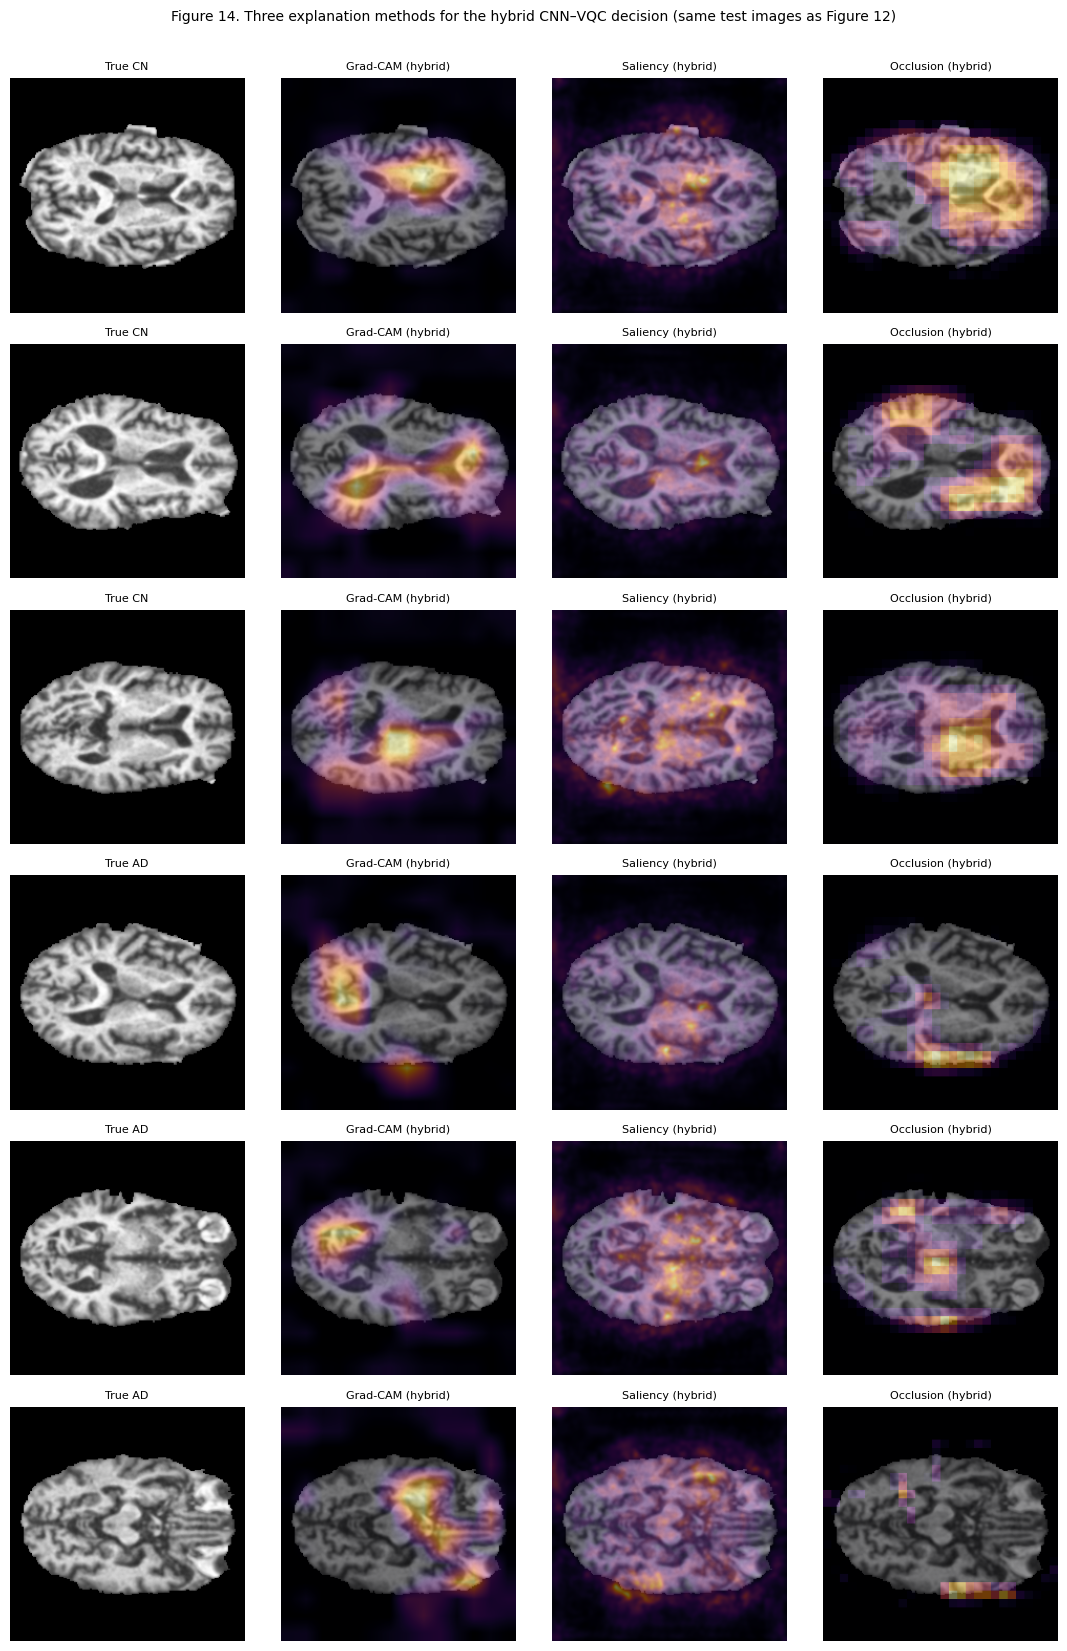

In [24]:
XAI_EXTRA = {}
if RUN_EXTRA_XAI:
    def hybrid_prob(xb):
        return torch.softmax(e2e.from_maps(cnn0.body(xb)), 1)[:, 1]

    def _norm01(a):
        a = a - a.min()
        return a / (a.max() + 1e-12)

    def saliency_map(i):
        xb = to_batch(np.array([i])).detach().requires_grad_(True)
        hybrid_prob(xb).sum().backward()
        s_ = xb.grad.detach().abs().amax(1)[0].cpu().numpy().astype(np.float32)
        return _norm01(cv2.GaussianBlur(s_, (0, 0), max(1.0, IMG_SIZE / 112)))

    @torch.no_grad()
    def occlusion_map(i, bs=64):
        patch = max(4, IMG_SIZE // 14); stride = max(2, patch // 2)
        x0 = to_batch(np.array([i])); base = float(hybrid_prob(x0))
        H = x0.shape[-1]
        pos = [(r_, c_) for r_ in range(0, H - patch + 1, stride) for c_ in range(0, H - patch + 1, stride)]
        heat, cnt = np.zeros((H, H)), np.zeros((H, H))
        for s_ in range(0, len(pos), bs):
            chunk = pos[s_:s_ + bs]
            xb = x0.repeat(len(chunk), 1, 1, 1)
            for j_, (r_, c_) in enumerate(chunk):
                xb[j_, :, r_:r_ + patch, c_:c_ + patch] = -1.0                 # black patch (input range is [-1, 1])
            pr = hybrid_prob(xb).cpu().numpy()
            for j_, (r_, c_) in enumerate(chunk):
                heat[r_:r_ + patch, c_:c_ + patch] += (base - pr[j_]) if base >= 0.5 else (pr[j_] - base)
                cnt[r_:r_ + patch, c_:c_ + patch] += 1
        return _norm01(np.clip(heat / np.maximum(cnt, 1), 0, None))

    def top_inside(m_, mask, top=0.2):
        sel = m_ >= np.quantile(m_, 1 - top)
        return float((sel & mask).sum() / max(sel.sum(), 1))

    rows_x, maps_x = [], []
    t0 = time.time()
    for j in ex:
        i = te0[j]
        sal, occ, gc = saliency_map(i), occlusion_map(i), cam_hyb[j]
        maps_x.append((i, gc, sal, occ))
        r_ = lambda a, b: float(np.corrcoef(a.ravel(), b.ravel())[0, 1]) if a.std() > 0 and b.std() > 0 else np.nan
        rows_x.append(dict(image=Path(df.rel[i]).name, true="AD" if y[i] else "CN", p_ad=round(float(pa_hyb[j]), 3),
                           r_gradcam_saliency=r_(gc, sal), r_gradcam_occlusion=r_(gc, occ), r_saliency_occlusion=r_(sal, occ),
                           inside_gradcam=top_inside(gc, MASK[i]), inside_saliency=top_inside(sal, MASK[i]),
                           inside_occlusion=top_inside(occ, MASK[i]), mask_area=float(MASK[i].mean())))
    TABLE_XAI = pd.DataFrame(rows_x)
    TABLE_XAI.round(3).to_csv(os.path.join(OUT_DIR, "tables", "tableS_xai_methods.csv"), index=False)
    display(TABLE_XAI.round(3))
    XAI_EXTRA = {k: float(np.nanmedian(TABLE_XAI[k])) for k in TABLE_XAI.columns if k.startswith(("r_", "inside_", "mask_"))}
    XAI_EXTRA.update(n=len(rows_x), seconds=time.time() - t0)
    print("Median over examples:", {k: round(v, 3) for k, v in XAI_EXTRA.items()})

    fig, axes = plt.subplots(len(maps_x), 4, figsize=(11, 2.8 * len(maps_x)))
    axes = np.atleast_2d(axes)
    for r_i, (i, gc, sal, occ) in enumerate(maps_x):
        axes[r_i, 0].imshow(X[i], cmap="gray"); axes[r_i, 0].set_title(f"True {'AD' if y[i] else 'CN'}", fontsize=8)
        for c_i, (mp, lab) in enumerate(((gc, "Grad-CAM (hybrid)"), (sal, "Saliency (hybrid)"), (occ, "Occlusion (hybrid)")), 1):
            axes[r_i, c_i].imshow(X[i], cmap="gray"); axes[r_i, c_i].imshow(mp, cmap="inferno", alpha=0.45, vmin=0, vmax=1)
            axes[r_i, c_i].set_title(lab, fontsize=8)
        for a in axes[r_i]:
            a.axis("off"); a.grid(False)
    fig.suptitle("Figure 14. Three explanation methods for the hybrid CNN–VQC decision (same test images as Figure 12)", fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.975)); FIGS["fig14"] = savefig(fig, "fig14_xai_methods")

## 13. Qiskit cross-check and shot-noise analysis (R3-8)
1. The trained VQC is evaluated with **Qiskit's `Statevector`** on every test image of fold 1. Its ⟨Z⟩ values are compared with the PyTorch simulator, and so are the resulting predictions.
2. The same circuits are then sampled with **Qiskit's `StatevectorSampler`** using a finite number of shots. ⟨Z⟩ is estimated from the counts, and the hybrid model's accuracy and AUC are recomputed. This tests empirically what finite measurement statistics do to the predictions.

In [25]:
hyb0 = KEEP["hyb"].eval()
theta0 = hyb0.q.theta.detach().cpu().numpy().astype(np.float64)
q_te0 = KEEP["q_te"].astype(np.float64)
Z_qiskit = qiskit_expectations(N_QUBITS, q_te0, theta0)
with torch.no_grad():
    Z_torch = hyb0.q(torch.tensor(q_te0, dtype=torch.float32, device=Q_DEVICE)).cpu().numpy()
C_te0 = torch.tensor(KEEP["C_te"], dtype=torch.float32, device=Q_DEVICE)


@torch.no_grad()
def hybrid_from_z(Zq):
    return torch.softmax(hyb0.out(torch.cat([C_te0, torch.tensor(Zq, dtype=torch.float32, device=Q_DEVICE)], 1)), 1)[:, 1].cpu().numpy()


p_qiskit_exact = hybrid_from_z(Z_qiskit)
QISKIT_CHECK = dict(max_abs_z_diff=float(np.abs(Z_qiskit - Z_torch).max()),
                    max_abs_p_diff=float(np.abs(p_qiskit_exact - P["hybrid"][te0]).max()),
                    prediction_agreement_pct=100 * float(np.mean((p_qiskit_exact >= 0.5) == (P["hybrid"][te0] >= 0.5))))
print("Qiskit Statevector vs PyTorch on fold-1 test set:", QISKIT_CHECK)

qc_m = QC.copy(); qc_m.measure_all()
sampler_params = {tuple(QC_X): q_te0, tuple(QC_T): np.tile(theta0, (len(q_te0), 1))}
y0 = y[te0]
shot_rows = [dict(shots="exact (statevector)", seed=-1, accuracy=100 * float(np.mean((p_qiskit_exact >= 0.5) == y0)),
                  auc=float(roc_auc_score(y0, p_qiskit_exact)), mean_abs_dp=0.0, flipped_predictions=0)]
for shots in SHOTS_LIST:
    for s in range(N_SHOT_SEEDS):
        res = StatevectorSampler(default_shots=shots, seed=SEED + s).run([(qc_m, sampler_params)]).result()[0]
        bits = res.data.meas.array          # (N, shots, bytes) — little-endian: qubit k = bit k
        vals = np.zeros(bits.shape[:-1], dtype=np.int64)
        for b in range(bits.shape[-1]):
            vals = (vals << 8) | bits[..., b].astype(np.int64)
        Zs = np.stack([1 - 2 * ((vals >> k) & 1).mean(-1) for k in range(N_QUBITS)], 1)
        ps = hybrid_from_z(Zs)
        shot_rows.append(dict(shots=shots, seed=s, accuracy=100 * float(np.mean((ps >= 0.5) == y0)),
                              auc=float(roc_auc_score(y0, ps)), mean_abs_dp=float(np.abs(ps - p_qiskit_exact).mean()),
                              flipped_predictions=int(np.sum((ps >= 0.5) != (p_qiskit_exact >= 0.5)))))
SHOT = pd.DataFrame(shot_rows)
SHOT_SUM = SHOT.groupby("shots", sort=False).agg(accuracy_mean=("accuracy", "mean"), accuracy_sd=("accuracy", "std"),
                                                 auc_mean=("auc", "mean"), mean_abs_dp=("mean_abs_dp", "mean"),
                                                 flipped_predictions=("flipped_predictions", "mean")).reset_index()
SHOT_SUM.round(4).to_csv(os.path.join(OUT_DIR, "tables", "tableS_shot_noise.csv"), index=False)
display(SHOT_SUM.round(4))

Qiskit Statevector vs PyTorch on fold-1 test set: {'max_abs_z_diff': 1.3481810762216995e-06, 'max_abs_p_diff': 1.1920928955078125e-07, 'prediction_agreement_pct': 100.0}


,shots,accuracy_mean,accuracy_sd,auc_mean,mean_abs_dp,flipped_predictions
0,exact (statevector),51.4986,NaN,0.5178,0.0000,0.0
1,128,51.4441,0.1219,0.5173,0.0018,0.2
2,1024,51.4986,0.0000,0.5177,0.0006,0.0
3,8192,51.4986,0.0000,0.5178,0.0002,0.0


## 14. Implementation details (Table 6; R1-6, R3-10)

In [26]:
TABLE6 = pd.DataFrame([
    ("Slice selection", {"entropy": "highest grey-level entropy per scan (Hon & Khan 2017)", "central": "nearest the scan centre",
                         "even": "evenly spaced"}[SLICE_SELECTION] + f", within slices {SLICE_RANGE[0]}–{SLICE_RANGE[1]}"),
    ("Pre-processing", PREPROC_TXT),
    ("Input", f"{IMG_SIZE} × {IMG_SIZE}; "
              + (f"2.5D: slices s−{SLICE_OFFSET}, s, s+{SLICE_OFFSET} of the same scan as 3 channels (one shared crop box)"
                 if INPUT_MODE == "2.5d" else "single slice" + (", replicated to 3 channels" if BACKBONE != "custom" else ""))
              + ("; ImageNet normalisation" if BACKBONE != "custom" else "")),
    ("Augmentation (training only)", "horizontal flip; random affine: ±10°, ±5% translation, 0.9–1.1 scale, ±5° shear; "
                                     "gamma/contrast/brightness jitter; Gaussian noise; random erasing (p 0.25)"
                                     if AUGMENT == "strong" else "horizontal flip; random affine: ±10°, ±5% translation, 0.95–1.05 scale"),
    ("CNN", (f"{BACKBONE.upper().replace('_', '-')} pre-trained on ImageNet" if PRETRAINED else f"{BACKBONE} (random init)")
            + f": 13 conv layers (5 blocks), fc6 4096, fc7 4096 (ReLU, dropout {CNN_DROPOUT}), new FC 2 (softmax)"
            if BACKBONE != "custom" else
            f"{len(CNN_WIDTHS)} blocks [2 × (3×3 conv, BN, ReLU) + 2×2 max-pool], filters {list(CNN_WIDTHS)}; "
            f"adaptive avg-pool 2×2; FC {FEATURE_DIM} (ReLU, dropout {CNN_DROPOUT}); FC 2 (softmax); trained from scratch"),
    ("CNN parameters", f"{N_PARAMS['cnn_total']:,} total ({N_PARAMS['cnn_classification_part']:,} in the FC layers; "
                       f"{N_PARAMS['cnn_trainable']:,} trainable)"),
    ("CNN training", f"AdamW, lr {CNN_LR:g}" + (f" (pre-trained conv layers {CNN_LR_BACKBONE:g})" if BACKBONE != "custom" and PRETRAINED else "")
                     + f", weight decay {CNN_WEIGHT_DECAY:g}, batch {BATCH_SIZE}, lr halved on plateau, "
                     f"{'mixed precision, ' if AMP_ON else ''}≤ {CNN_EPOCHS} epochs, early stopping (patience {CNN_PATIENCE}, "
                     f"not before epoch {CNN_MIN_EPOCHS}) "
                     + ("and checkpoint selection on the subject-level validation AUC" if SELECT_BY == "val_auc" else "on validation loss")
                     + (f"; first {FREEZE_BLOCKS} conv blocks frozen" if BACKBONE != "custom" and PRETRAINED and FREEZE_BLOCKS else "")
                     + (f"; label smoothing {LABEL_SMOOTHING:g}" if LABEL_SMOOTHING else "")
                     + f"; epochs used {TIMES.cnn_epochs.min()}" + (f"–{TIMES.cnn_epochs.max()}" if TIMES.cnn_epochs.max() != TIMES.cnn_epochs.min() else "")),
    ("Feature vector", "4096-d fc7 output" if BACKBONE != "custom" else f"{FEATURE_DIM}-d output of the first FC layer"),
    ("PCA", f"fitted on training groups only; {N_PCA} components ({cum0[N_PCA - 1]:.1f}% variance, fold 1); "
            f"leading {N_QUBITS} ({cum0[N_QUBITS - 1]:.1f}%) to the VQC"),
    ("Quantum encoding", f"{'ZZ feature map, ' + str(FM_REPS) + ' repetitions' if ENCODING == 'zz' else 'RY angle encoding'}; "
                         "inputs min–max scaled to [0, π] on training groups"),
    ("Ansatz", f"RealAmplitudes, {ANSATZ_REPS} layers, {ENTANGLEMENT} CNOT entanglement"),
    ("Qubits / trainable quantum parameters", f"{N_QUBITS} / {len(QC_T)}"),
    ("Circuit depth / CNOTs (H, P, CX, RY gates)", f"{CIRCUIT_INFO['depth']} / {CIRCUIT_INFO['cx_gates']}"),
    ("Measurement", "⟨Z_k⟩ on every qubit (Eq. 13)"),
    ("VQC classifier", f"⟨Z⟩ → linear softmax; {N_PARAMS['vqc_total']} trainable parameters"),
    ("Hybrid head (Eq. 14–15)", f"[standardised {N_PCA} PCA comps ⊕ {N_QUBITS} ⟨Z⟩ values] → linear softmax; "
                                f"{N_PARAMS['hybrid_head_total']} trainable parameters; CNN frozen"),
    ("Quantum/hybrid training", f"Adam, lr {Q_LR}, batch {Q_BATCH}, ≤ {Q_EPOCHS} epochs, early stopping (patience {Q_PATIENCE}); "
                                f"best of {Q_RESTARTS} random initialisations by validation loss; "
                                "exact gradients (automatic differentiation of the state vector)"),
    ("Simulation", "exact state vector (PyTorch, complex64), verified against Qiskit Statevector "
                   f"(max |Δ⟨Z⟩| = {max(SIM_CHECK.values()):.1e} random; {QISKIT_CHECK['max_abs_z_diff']:.1e} on test data)"),
    ("Data", f"OASIS-1 (Kaggle 2D axial slices); AD = CDR ≥ {AD_MIN_CDR:g}, CN = CDR 0" + (f", age ≥ {CN_MIN_AGE}" if AGE_MATCHED else "")
             + f"; one session/acquisition per subject; {df.groupby('subject').size().min()}–{df.groupby('subject').size().max()} "
             "slices per subject"),
    ("Evaluation", f"{N_FOLDS}-fold stratified cross-validation at subject level; {int(VAL_FRAC * 100)}% of the subjects of "
                   "each training fold held out for early stopping and qubit selection"),
    ("Training time (mean per fold)", f"CNN {TIME_MEAN['cnn']:.1f} min; VQC {TIME_MEAN['vqc']:.2f} min; hybrid head {TIME_MEAN['hybrid']:.2f} min"),
    ("Software / hardware", f"Python {ENV['python']}, PyTorch {ENV['torch']}, Qiskit {ENV['qiskit']}, "
                            f"scikit-learn {ENV['scikit-learn']}; {ENV['device']}"),
] + ([("ML benchmark (Sec. 10b)", "; ".join(f"{fs}: {v['backbones']} frozen ({v['dims']} = {v['total']}-d)" for fs, v in FEAT_INFO.items())
       + f" → standardisation → PCA ({ML_PCA} comps, not whitened; fitted on training + validation subjects) → {len(ZOO)} classifiers "
       f"({', '.join(dict.fromkeys(ZOO_NAMES[k[1]] for k in ZOO))}); hyper-parameters fixed in advance; "
       f"LD-RNN: 1200→512 projection, LSTM 128, dense 128–64, dropout 0.3, Adam {LDRNN_LR:g}, batch {LDRNN_BATCH}, "
       f"≤ {LDRNN_EPOCHS} epochs with early stopping (patience {LDRNN_PATIENCE})")] if ZOO else [])
  + ([("Additional explanations (Sec. 12b)", "saliency (|∂P/∂x|) and occlusion maps (black patch 1/14 of the image side, "
       "50% overlap) for the hybrid decision")] if XAI_EXTRA else []), columns=["Component", "Setting"])
TABLE6.to_csv(os.path.join(OUT_DIR, "tables", "table6_hyperparameters.csv"), index=False)
pd.set_option("display.max_colwidth", 200)
display(TABLE6)

,Component,Setting
0,Slice selection,"highest grey-level entropy per scan (Hon & Khan 2017), within slices 100–160"
1,Pre-processing,"crop to the head, pad to a square, resize; N4 bias-field correction (field from the centre slice); 2D skull stripping (brain mask accepted on 99.3% of slices, head mask otherwise); crop to the bra..."
2,Input,"224 × 224; 2.5D: slices s−2, s, s+2 of the same scan as 3 channels (one shared crop box); ImageNet normalisation"
3,Augmentation (training only),"horizontal flip; random affine: ±10°, ±5% translation, 0.9–1.1 scale, ±5° shear; gamma/contrast/brightness jitter; Gaussian noise; random erasing (p 0.25)"
4,CNN,"VGG16-BN pre-trained on ImageNet: 13 conv layers (5 blocks), fc6 4096, fc7 4096 (ReLU, dropout 0.5), new FC 2 (softmax)"
5,CNN parameters,"134,277,186 total (119,554,050 in the FC layers; 132,539,394 trainable)"
6,CNN training,"AdamW, lr 0.0001 (pre-trained conv layers 1e-05), weight decay 0.01, batch 16, lr halved on plateau, mixed precision, ≤ 25 epochs, early stopping (patience 6, not before epoch 6) and checkpoint se..."
7,Feature vector,4096-d fc7 output
8,PCA,"fitted on training groups only; 64 components (94.6% variance, fold 1); leading 4 (76.2%) to the VQC"
9,Quantum encoding,"ZZ feature map, 2 repetitions; inputs min–max scaled to [0, π] on training groups"


## 15. Auto-generated Results section and verification report
The wording below is chosen from the measured results. For example, "comparable" or "higher", and "was" or "was not statistically significant", depend on the numbers and tests. Read it alongside the figures before pasting it into the manuscript.

In [27]:
def pfmt(p):
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"


def sig(p):
    return "statistically significant" if p < 0.05 else "not statistically significant"


def compare(a, b, tol=0.5):
    d = S[a]["accuracy"] - S[b]["accuracy"]
    return "higher than" if d > tol else ("lower than" if d < -tol else "comparable to")


nCN, nAD = int((y == 0).sum()), int((y == 1).sum())
st_ch, st_hl, st_vl = ST["cnn|hybrid"], ST["hybrid|lin64"], ST["vqc|lin_n"]
ss_ch, ss_hl = SUBJ_STATS["cnn|hybrid"], SUBJ_STATS["hybrid|lin64"]
hyb_better = st_ch.paired_t_acc_p < 0.05 and ss_ch["p"] < 0.05 and S["hybrid"]["accuracy"] > S["cnn"]["accuracy"]
q_adds = ss_hl["p"] < 0.05 and S["hybrid"]["accuracy"] > S["lin64"]["accuracy"]
n_sub = {lab: df[df.label == lab].subject.nunique() for lab in (0, 1)}
spp = df.groupby("subject").size()
k_desc = f"{spp.min()}" if spp.min() == spp.max() else f"{spp.min()}–{spp.max()}"
cdr_counts = ", ".join(f"CDR {c:g}: {n}" for c, n in sel_subj[sel_subj.label == 1].cdr.value_counts().sort_index().items())
if DEMO is not None:
    demo_txt = (f" Age (mean ± SD) was {DEMO_TESTS['age_cn']} years in the CN group and {DEMO_TESTS['age_ad']} years in the "
                f"AD group (Welch t-test p = {DEMO_TESTS['age_p']:.3f}; sex: χ² p = {DEMO_TESTS.get('sex_p', np.nan):.3f}); "
                f"MMSE was {DEMO_TESTS['mmse_cn']} and {DEMO_TESTS['mmse_ad']}, respectively.")
    if DEMO_TESTS["age_p"] < 0.05:
        demo_txt += " The groups still differed in age, which should be considered when interpreting the results."
else:
    demo_txt = ""

R = []
R.append(("h1", "Additions to Section 3.1 (Dataset)"))
R.append(("p", f"The experiments used {DATASET_NAME} {DATASET_CITATION}. OASIS-1 comprises T1-weighted MRI of 416 adults "
               "aged 18–96 years, 100 of whom have very mild to moderate dementia of the Alzheimer type; the Kaggle version "
               f"provides axial slices {SLICE_RANGE[0]}–{SLICE_RANGE[1]} of each scan, labelled by Clinical Dementia Rating (CDR). "
               f"AD was defined as CDR ≥ {AD_MIN_CDR:g} ({n_sub[1]} subjects; {cdr_counts}) and cognitively normal (CN) as CDR 0"
               + (f" with age ≥ {CN_MIN_AGE} years, because all OASIS-1 dementia cases are older than 60 ({n_sub[0]} subjects)"
                  if AGE_MATCHED else f" ({n_sub[0]} subjects; not age-matched)")
               + f". For each subject, one session (MR1) and one T1-weighted acquisition were used, and "
               + {"entropy": f"the {k_desc} slices with the highest grey-level entropy (the most informative slices; Hon & Khan, 2017)",
                  "central": f"the {k_desc} slices nearest the centre of the slice range",
                  "even": f"{k_desc} evenly spaced slices"}[SLICE_SELECTION]
               + f" were selected, giving {len(y)} images ({nCN} CN, {nAD} AD; Table 1).{demo_txt}"))
R.append(("p", f"Performance was estimated with {N_FOLDS}-fold stratified cross-validation at the subject level: all images of "
               "a subject were assigned to the same fold, and no subject contributed images to more than one of the training, "
               "validation and test sets (verified programmatically). Within each training fold, "
               f"{int(VAL_FRAC * 100)}% of the subjects were held out as a validation set for early stopping and for choosing "
               "the number of qubits; the test fold was never used for training or model selection."))
R.append(("table", TABLE1, "Table 1. Selected subjects and images (OASIS-1)."))
h_last = HIST.groupby("fold").tail(1)
_rng = lambda a, b, f="{}": f.format(a) if f.format(a) == f.format(b) else f"{f.format(a)}–{f.format(b)}"
pp = [f"Each selected slice was cropped to the head, padded to a square without distortion and resized to {IMG_SIZE} × {IMG_SIZE} pixels."]
if N4_ON:
    pp.append("Intensity inhomogeneity was corrected with the N4 bias-field correction algorithm (SimpleITK); the field was "
              "estimated on the selected slice and applied to its neighbouring slices.")
if SKULL_STRIP:
    pp.append("The brain was then extracted with a 2D ray-casting procedure: along 180 rays from the centre of the head, "
              "the transition from scalp to the dark band of skull and cerebrospinal fluid and then to brain tissue was "
              "located (intensity thresholds from two-level Otsu thresholding within the head), the edge depth was "
              "median-filtered across neighbouring rays after removing outliers (orbits, sinuses), and the resulting "
              "contour was filled. When fewer than 35% of the rays gave a valid edge, or the mask covered less than 45% or "
              f"more than 95% of the head, the head mask was used instead; the brain mask was accepted for "
              f"{PREPROC['strip_ok_pct']:.1f}% of the slices (Figure S5)."
              + (" Each image was cropped to the bounding box of the brain." if BRAIN_CROP else ""))
else:
    pp.append("The skull and scalp were not removed.")
pp.append({"gaussian": f"Images were smoothed with a Gaussian filter (σ = {GAUSS_SIGMA:g} pixels; Eq. 3), ",
           "median": "Images were denoised with a 3 × 3 median filter, ", "none": "Images were "}[DENOISE]
          + f"contrast-enhanced with CLAHE (clip limit {CLAHE_CLIP:g}, 8 × 8 tiles) and "
          + ("z-score normalised within the brain mask (Eq. 4), with values clipped to ±3 standard deviations."
             if INTENSITY_NORM == "zscore" else "min–max normalised."))
pp.append("Every step uses only the image itself, so no information is shared between training and test subjects.")
if AUGMENT == "strong":
    pp.append("During CNN training only, images were augmented with horizontal flips, random affine transforms (±10° "
              "rotation, ±5% translation, 0.9–1.1 scaling, ±5° shear), gamma, contrast and brightness jitter, Gaussian "
              "noise and random erasing of small patches.")
R.append(("h1", "Additions to Section 3.2 (Pre-processing)"))
R.append(("p", " ".join(pp)))
R.append(("h1", "Additions to Section 3.3 (CNN feature extractor)"))
R.append(("p", (f"The feature extractor was {BACKBONE.upper().replace('_', '-')}"
                + (" pre-trained on ImageNet and fine-tuned" if PRETRAINED else " initialised randomly and trained")
                + " end-to-end for CN-versus-AD classification. "
                + (f"Each input stacked the selected slice with the slices {SLICE_OFFSET} positions below and above it in the "
                   "same scan as three channels (2.5D input), cropped with one shared bounding box; "
                   if INPUT_MODE == "2.5d" else "Each greyscale slice was replicated to three channels; ")
                + "inputs were normalised with the ImageNet mean and standard deviation; the original fc6 and fc7 layers were retained, the "
                "4096-dimensional fc7 activation was used as the feature vector F_CNN, and the 1000-class output layer was "
                "replaced by a two-unit softmax layer." if BACKBONE != "custom" else
                f"The feature extractor was a {len(CNN_WIDTHS)}-block CNN trained from scratch, whose {FEATURE_DIM}-unit fully "
                "connected layer provided the feature vector F_CNN.")
               + f" Training used AdamW (learning rate {CNN_LR:g}"
               + (f" for the fully connected layers and {CNN_LR_BACKBONE:g} for the pre-trained convolutional layers"
                  if BACKBONE != "custom" and PRETRAINED else "")
               + f", weight decay {CNN_WEIGHT_DECAY:g}, batch size {BATCH_SIZE}), "
               f"halving of the learning rate when the validation loss plateaued"
               + (f", {LABEL_SMOOTHING:g} label smoothing" if LABEL_SMOOTHING else "")
               + (f" and frozen weights in the first {FREEZE_BLOCKS} convolutional blocks" if BACKBONE != "custom" and PRETRAINED and FREEZE_BLOCKS else "")
               + ("; the checkpoint with the highest subject-level AUC on the validation subjects was kept, with early stopping "
                  if SELECT_BY == "val_auc" else ", and early stopping on the validation loss ")
               + f"(patience {CNN_PATIENCE}, not before epoch {CNN_MIN_EPOCHS}); training stopped after "
               f"{_rng(TIMES.cnn_epochs.min(), TIMES.cnn_epochs.max())} epochs, with a final training accuracy of "
               f"{_rng(100 * h_last.train_acc.min(), 100 * h_last.train_acc.max(), '{:.1f}')}% across folds (Figure S3)."))
if ZOO:
    zoo_list = list(dict.fromkeys(ZOO_NAMES[k[1]] for k in ZOO))
    R.append(("h1", "Additions to Section 3.8 (Benchmark classifiers)"))
    R.append(("p", "To compare the proposed model with conventional machine-learning approaches, we implemented the "
                   "LD-RNN pipeline of Thatere and Reddy [cite] and the classifier families reviewed by Alam et al. [cite]. "
                   + "; ".join(f"Features were extracted with frozen {'ImageNet-pre-trained' if PRETRAINED else 'randomly initialised'} {v['backbones']} networks ({v['dims']} = "
                               f"{v['total']} dimensions per image)" for v in FEAT_INFO.values())
                   + f", standardised, reduced with PCA to {ML_PCA} components (without whitening) and rescaled by one "
                   "global standard deviation; standardisation and PCA were fitted on the training and validation "
                   "subjects of each fold only. SVM decision values were mapped to probabilities with a logistic "
                   "function. The classifiers were "
                   + ", ".join(zoo_list[:-1]) + (f" and {zoo_list[-1]}" if len(zoo_list) > 1 else zoo_list[0])
                   + ". The LD-RNN classifier followed the original design (1200 → 512 projection, LSTM with 128 hidden "
                   "units, dense layers of 128 and 64 units, dropout 0.3, Adam with learning rate 0.001, batch size 16), "
                   f"with early stopping on the validation subjects (at most {LDRNN_EPOCHS} epochs). All hyper-parameters "
                   "were fixed before evaluation and every classifier used the same subject-level folds as the proposed model."))
R.append(("h1", "4. Experimental Results"))
R.append(("p", f"Each of the {len(y)} images (and each of the {len(ys)} subjects) was tested exactly once. Image-level results "
               f"are reported as mean ± standard deviation over the {N_FOLDS} test folds; pooled 95% confidence intervals were "
               f"obtained by bootstrap resampling of subjects ({N_BOOTSTRAP} resamples). Subject-level results use the mean "
               "predicted probability over each subject's slices. A threshold of 0.5 on the predicted probability of AD was used."))
R.append(("h2", "4.2 CNN Model Performance"))
R.append(("p", f"The CNN achieved an accuracy of {fmt('cnn', 'accuracy')}% (pooled 95% CI {S['cnn']['acc_ci'][0]:.1f}–"
               f"{S['cnn']['acc_ci'][1]:.1f}%), a sensitivity of {fmt('cnn', 'recall')}%, a specificity of "
               f"{fmt('cnn', 'specificity')}% and an AUC of {fmt('cnn', 'auc')} (Table 3, Figure 9)."))
R.append(("table", TABLES["table3_cnn"], "Table 3. CNN performance (test folds)."))
R.append(("fig", FIGS["fig09"], "Figure 9. Empirical ROC curves of the CNN (thin: individual folds; thick: mean)."))
R.append(("h2", "4.3 VQC Model Performance"))
R.append(("p", f"The standalone VQC, operating on the leading {N_QUBITS} PCA components encoded on {N_QUBITS} qubits "
               f"({len(QC_T)} trainable circuit parameters; {N_PARAMS['vqc_total']} in total), achieved an accuracy of "
               f"{fmt('vqc', 'accuracy')}% and an AUC of {fmt('vqc', 'auc')} (Table 4, Figure 10a). A classical linear "
               f"classifier given the same {N_QUBITS} components achieved {fmt('lin_n', 'accuracy')}% (AUC {fmt('lin_n', 'auc')}); "
               f"the difference was {sig(st_vl.mcnemar_p)} (McNemar p {pfmt(st_vl.mcnemar_p)})."))
R.append(("table", TABLES["table4_vqc"], "Table 4. VQC performance (test folds)."))
R.append(("h2", "4.4 Comparative Analysis: CNN, VQC and Hybrid CNN–VQC"))
R.append(("p", f"Table 5 compares all models. The hybrid CNN–VQC model achieved an accuracy of {fmt('hybrid', 'accuracy')}% and "
               f"an AUC of {fmt('hybrid', 'auc')}, {compare('hybrid', 'cnn')} the classical CNN ({fmt('cnn', 'accuracy')}%; AUC "
               f"{fmt('cnn', 'auc')}). The difference was {sig(ss_ch['p'])} by McNemar's exact test on subject-level "
               f"predictions (p {pfmt(ss_ch['p'])}) and {sig(st_ch.paired_t_acc_p)} by a paired t-test on fold accuracies "
               f"(p {pfmt(st_ch.paired_t_acc_p)}); the DeLong test on image-level AUCs gave p {pfmt(st_ch.delong_p)}, but it treats "
               "correlated slices of the same subject as independent and is therefore optimistic. "
               f"Removing the quantum branch from the hybrid head (a linear classifier on the same {N_PCA} components) gave "
               f"{fmt('lin64', 'accuracy')}% (AUC {fmt('lin64', 'auc')}), so the VQC branch "
               + ("significantly improved" if q_adds else "did not significantly change")
               + f" the classification (subject-level McNemar p {pfmt(ss_hl['p'])})."))
R.append(("table", TABLES["table5_comparison"], "Table 5. Comparison of all models (mean ± SD over test folds)."))
R.append(("p", "The hybrid model therefore " + ("outperformed" if hyb_better else "did not outperform")
               + " the classical CNN in this experiment. Because all quantum circuits were simulated on classical hardware, "
               "these results do not indicate a quantum computational advantage; they show whether a compact quantum "
               f"classifier ({len(QC_T)} circuit parameters) can be combined with CNN features while maintaining diagnostic "
               "performance. ROC curves are shown in Figures 10 and 11."))
R.append(("fig", FIGS["fig10"], "Figure 10. Empirical ROC curves of (a) the VQC and (b) the hybrid CNN–VQC model."))
R.append(("fig", FIGS["fig11"], "Figure 11. Mean ROC curves of the CNN, VQC and hybrid CNN–VQC models."))
R.append(("p", f"At the subject level ({len(ys)} subjects), accuracies were "
               + "; ".join(f"{NAMES[m]} {SUBJ[m]['accuracy']:.1f}% (AUC {SUBJ[m]['auc']:.3f})" for m in ("cnn", "vqc", "hybrid"))
               + " (Table 5b)."))
R.append(("table", TABLE_SUBJ, "Table 5b. Subject-level performance (mean slice probability per subject)."))
R.append(("p", "Practical implications. " + (
    "At its current stage, the hybrid model offers no practical advantage to clinicians over the classical CNN, which "
    "achieved similar or higher performance with a simpler implementation. " if not hyb_better else
    "Although the hybrid model achieved higher accuracy than the CNN in this experiment, the circuits were simulated "
    "classically and only one dataset was used, so no practical clinical advantage can yet be claimed. ")
    + "Any clinical benefit would depend on validation in independent multi-site cohorts, extension to MCI, evaluation on "
      "quantum hardware and prospective assessment of the explanations by clinicians."))
if ZOO and BEST_ZOO:
    bz, bh = BENCH[BEST_ZOO], BENCH[("proposed", "hybrid")]
    rank = sorted(BENCH, key=lambda k: -BENCH[k]["mean"]["auc"]).index(("proposed", "hybrid")) + 1
    txt = (f"Table 9 and Figure 13 compare the proposed models with {len(ZOO)} benchmark classifiers evaluated on the same "
           f"subject-level folds. The best benchmark model by mean AUC was {BENCH_NAME[BEST_ZOO]} "
           f"(accuracy {_ms(bz, 'accuracy', 1)}%, AUC {_ms(bz, 'auc', 3)}; subject-level accuracy {bz['subj']['accuracy']:.1f}%). "
           f"The hybrid CNN–VQC reached {_ms(bh, 'accuracy', 1)}% (AUC {_ms(bh, 'auc', 3)}) and ranked {rank} of {len(BENCH)} "
           f"by AUC. The difference between the two was {sig(BEST_TEST['p_subj'])} (subject-level McNemar p "
           f"{pfmt(BEST_TEST['p_subj'])}; DeLong p {pfmt(BEST_TEST['delong_p'])}); because the best benchmark model was "
           "identified after testing, this comparison is descriptive.")
    if FRIEDMAN is not None:
        txt += (f" A Friedman test across all {len(BENCH)} models and {N_FOLDS} folds gave χ² = {FRIEDMAN.statistic:.1f}, "
                f"p {pfmt(FRIEDMAN.pvalue)}.")
    R.append(("h2", "4.4.1 Benchmark against machine-learning classifiers and the LD-RNN pipeline"))
    R.append(("p", txt))
    R.append(("table", TABLE9, "Table 9. All models on the same subject-level cross-validation (mean ± SD over test folds; "
                               "pooled accuracy with subject-bootstrap 95% CI)."))
    if "fig13" in FIGS:
        R.append(("fig", FIGS["fig13"], "Figure 13. Accuracy and AUC of all models with 95% confidence intervals."))
    if len(LEAK_TABLE):
        lk = LEAK_TABLE
        R.append(("p", "To quantify the effect of the evaluation protocol used by several high-accuracy studies, the same "
                       "features and three classifiers were also evaluated with a random 80:20 split of images and PCA fitted "
                       f"before the split, as in the LD-RNN study. In this split, {lk.iloc[0, -1]} subjects had slices in both "
                       f"the training and the test set. Accuracy under this split was {lk.iloc[:, 1].min():.1f}–{lk.iloc[:, 1].max():.1f}%, "
                       f"compared with {lk.iloc[:, 2].min():.1f}–{lk.iloc[:, 2].max():.1f}% under subject-level "
                       f"cross-validation (mean difference {lk.iloc[:, 3].mean():+.1f} percentage points; Table 10). Because "
                       "slices of the same subject fall on both sides of an image-level split, such estimates are "
                       "optimistically biased and are not performance results; this illustrates why studies that report "
                       "image-level splits are not directly comparable with the subject-level results reported here."))
        R.append(("table", LEAK_TABLE, "Table 10. Leakage demonstration: the same classifiers under an image-level random "
                                       "split (LD-RNN protocol) versus subject-level cross-validation. Not performance results."))
R.append(("h2", "4.5 Explainability Analysis using Grad-CAM"))
R.append(("p", "Grad-CAM maps were computed in two ways for the test images of fold 1: from the CNN's own output, and from the "
               "hybrid model's output, back-propagated through the softmax layer, the VQC, the fixed scaling and PCA "
               "projection and the CNN to the last convolutional block. The second map therefore explains the hybrid "
               f"decision directly. Across {GRADCAM['n']} test images, the two maps were "
               + ("strongly" if GRADCAM["r_median"] >= 0.7 else "moderately" if GRADCAM["r_median"] >= 0.4 else "weakly")
               + f" correlated (Pearson r = {GRADCAM['r_mean']:.2f} ± {GRADCAM['r_sd']:.2f}; median {GRADCAM['r_median']:.2f}). "
               f"For the hybrid model, {GRADCAM['inside_hyb']:.1f}% of the top-20% activation fell inside the {MASK_NAME}, "
               f"compared with {GRADCAM['area']:.1f}% expected from the mask area alone"
               + ((", i.e. attention was concentrated on brain tissue" if SKULL_STRIP else ", i.e. attention was concentrated on the head rather than the background")
                  if GRADCAM["inside_hyb"] > GRADCAM["area"] + 5 else
                  (" — attention was not concentrated on brain tissue" if SKULL_STRIP else " — attention was not concentrated on the head")
                  + ", which suggests possible reliance on background or image-border cues and should be investigated")
               + ". Representative, randomly selected correctly classified examples are shown in Figure 12. [Describe what YOUR maps show anatomically, e.g. which structures are highlighted in AD cases.] "
               "This analysis is qualitative with respect to anatomy: no comparison with atlas-defined regions was performed, "
               "so the maps should not be interpreted as validated biomarkers."))
R.append(("fig", FIGS["fig12"], "Figure 12. Grad-CAM of the CNN and of the hybrid CNN–VQC decision for representative CN and AD test images."))
if XAI_EXTRA:
    R.append(("p", f"Two further explanation methods were applied to the hybrid decision for the same {XAI_EXTRA['n']} images "
                   "(Figure 14). Saliency maps (input gradients) correlated with the hybrid Grad-CAM maps at a median r of "
                   f"{XAI_EXTRA['r_gradcam_saliency']:.2f}, and occlusion maps at a median r of {XAI_EXTRA['r_gradcam_occlusion']:.2f}. "
                   f"The share of the top-20% of each map inside the {MASK_NAME} was {100 * XAI_EXTRA['inside_gradcam']:.0f}% "
                   f"(Grad-CAM), {100 * XAI_EXTRA['inside_saliency']:.0f}% (saliency) and {100 * XAI_EXTRA['inside_occlusion']:.0f}% "
                   f"(occlusion), against a mask area of {100 * XAI_EXTRA['mask_area']:.0f}%. Agreement between methods "
                   "indicates which highlighted regions are robust to the choice of explanation technique."))
    R.append(("fig", FIGS["fig14"], "Figure 14. Grad-CAM, saliency and occlusion maps for the hybrid CNN–VQC decision."))
R.append(("h2", "4.6 Simulation Fidelity and Measurement Noise"))
shot_hi, shot_lo = SHOT_SUM.iloc[-1], SHOT_SUM.iloc[1]
R.append(("p", f"Evaluating the trained circuit with Qiskit's Statevector reproduced the PyTorch simulation (maximum "
               f"|Δ⟨Z⟩| = {QISKIT_CHECK['max_abs_z_diff']:.1e}; {QISKIT_CHECK['prediction_agreement_pct']:.1f}% identical "
               "predictions). With finite measurement statistics, the hybrid model's test accuracy was "
               f"{shot_lo.accuracy_mean:.1f} ± {shot_lo.accuracy_sd:.1f}% with {shot_lo.shots} shots and "
               f"{shot_hi.accuracy_mean:.1f} ± {shot_hi.accuracy_sd:.1f}% with {shot_hi.shots} shots, compared with "
               f"{SHOT_SUM.iloc[0].accuracy_mean:.1f}% for the exact expectation values; on average "
               f"{shot_lo.flipped_predictions:.1f} of {len(te0)} predictions changed with {shot_lo.shots} shots (mean |Δp| = "
               f"{shot_lo.mean_abs_dp:.4f}). Finite sampling therefore adds statistical error to the estimated expectation "
               "values" + (" and did not improve accuracy" if shot_lo.accuracy_mean <= SHOT_SUM.iloc[0].accuracy_mean + 0.5 else "")
               + "; it is not a mechanism for robust prediction."))
R.append(("h2", "4.7 Limitations"))
R.append(("p", "First, all quantum circuits were simulated without hardware noise; performance on current quantum devices was not "
               "evaluated. Second, no computational speed-up or quantum advantage is claimed. Third, OASIS-1 is a single-site "
               f"dataset with {len(ys)} subjects in this analysis and binary CN-vs-AD classification; generalisation to "
               "independent multi-site cohorts (e.g., ADNI, AIBL) and to MCI has not been established. Fourth, slices from the "
               "same subject are correlated, so image-level statistics overstate the effective sample size; subject-level results "
               "are therefore also reported. "
               + ("" if AGE_MATCHED else "Fifth, the CN group was not age-matched and includes younger adults, so differences "
                  "in age may contribute to the classification. ")
               + "Finally, the model operates on 2D slices rather than full 3D volumes."))
R.append(("h1", "Additions to Section 3.4 (Choice of the number of qubits)"))
if RUN_QUBIT_SWEEP:
    b8 = TABLE8.set_index("n_qubits").loc[BEST_N]
    R.append(("p", f"Each principal component is encoded on one qubit, so the number of components fixes the circuit width. "
                   f"We evaluated n = {min(SWEEP_QUBITS)}–{max(SWEEP_QUBITS)} on the validation groups of each training fold "
                   f"(Table 8). n = {BEST_N} gave the highest mean validation accuracy ({b8.val_accuracy_mean:.1f} ± "
                   f"{b8.val_accuracy_sd:.1f}%, AUC {b8.val_auc_mean:.3f}) and retains {b8.cumulative_variance_pct:.1f}% of the "
                   f"variance of the CNN features. The reported models use n = {N_QUBITS}."))
    R.append(("table", TABLE8.round(3), "Table 8. VQC validation performance versus number of PCA components / qubits "
              "(mean ± SD over the validation groups of the training folds; one initialisation per setting)."))
R.append(("table", TABLE6, "Table 6. Implementation details and hyperparameters."))

def blocks_to_md(blocks):
    out = []
    for b in blocks:
        if b[0] == "h1": out += [f"# {b[1]}", ""]
        elif b[0] == "h2": out += [f"## {b[1]}", ""]
        elif b[0] == "p": out += [b[1], ""]
        elif b[0] == "table":
            t = b[1]; out += [f"**{b[2]}**", "", "| " + " | ".join(map(str, t.columns)) + " |", "|" + "---|" * len(t.columns)]
            out += ["| " + " | ".join(map(str, r)) + " |" for r in t.values.tolist()] + [""]
        elif b[0] == "fig": out += [f"![]({os.path.relpath(b[1], OUT_DIR)})", f"*{b[2]}*", ""]
    return "\n".join(out)


banner = (f"_Auto-generated by the QE-XAI notebook on {datetime.date.today():%d %b %Y}. "
          + ("**FAST_DEV_RUN — NOT FOR PUBLICATION.** " if FAST_DEV_RUN else "")
          + "Every number below was computed in this run._\n\n")
MD = banner + blocks_to_md(R)
with open(os.path.join(OUT_DIR, "results_section.md"), "w", encoding="utf-8") as f:
    f.write(MD)
try:
    from docx import Document
    from docx.shared import Inches, Pt
    doc = Document(); doc.styles["Normal"].font.name = "Times New Roman"; doc.styles["Normal"].font.size = Pt(11)
    doc.add_paragraph(banner.strip("_\n").replace("**", ""))
    for b in R:
        if b[0] in ("h1", "h2"): doc.add_heading(b[1], level=1 if b[0] == "h1" else 2)
        elif b[0] == "p": doc.add_paragraph(b[1])
        elif b[0] == "table":
            doc.add_paragraph(b[2]).runs[0].bold = True
            t = doc.add_table(rows=1, cols=len(b[1].columns)); t.style = "Table Grid"
            for i, c in enumerate(b[1].columns): t.rows[0].cells[i].text = str(c)
            for r in b[1].values.tolist():
                cells = t.add_row().cells
                for i, v in enumerate(r): cells[i].text = str(v)
        elif b[0] == "fig":
            doc.add_picture(b[1], width=Inches(6.2)); doc.add_paragraph(b[2]).runs[0].italic = True
    doc.save(os.path.join(OUT_DIR, "results_section.docx"))
except ImportError:
    print("python-docx not available — Markdown version only")
display(Markdown(MD.replace("![](", f"![]({os.path.relpath(OUT_DIR, os.getcwd())}/")))

_Auto-generated by the QE-XAI notebook on 15 Oct 2026. Every number below was computed in this run._

# Additions to Section 3.1 (Dataset)

The experiments used the OASIS-1 cross-sectional MRI data (Marcus et al., 2007) in the 2D-slice version distributed on Kaggle as “OASIS Alzheimer's Detection” [cite: Marcus et al., 2007; https://www.kaggle.com/datasets/ninadaithal/imagesoasis]. OASIS-1 comprises T1-weighted MRI of 416 adults aged 18–96 years, 100 of whom have very mild to moderate dementia of the Alzheimer type; the Kaggle version provides axial slices 100–160 of each scan, labelled by Clinical Dementia Rating (CDR). AD was defined as CDR ≥ 0.5 (81 subjects; CDR 0.5: 58, CDR 1: 21, CDR 2: 2) and cognitively normal (CN) as CDR 0 with age ≥ 60 years, because all OASIS-1 dementia cases are older than 60 (85 subjects). For each subject, one session (MR1) and one T1-weighted acquisition were used, and the 21–23 slices with the highest grey-level entropy (the most informative slices; Hon & Khan, 2017) were selected, giving 3600 images (1800 CN, 1800 AD; Table 1). Age (mean ± SD) was 76.4 ± 8.9 years in the CN group and 76.7 ± 7.3 years in the AD group (Welch t-test p = 0.794; sex: χ² p = 0.169); MMSE was 29.0 ± 1.2 and 24.1 ± 4.3, respectively.

Performance was estimated with 10-fold stratified cross-validation at the subject level: all images of a subject were assigned to the same fold, and no subject contributed images to more than one of the training, validation and test sets (verified programmatically). Within each training fold, 15% of the subjects were held out as a validation set for early stopping and for choosing the number of qubits; the test fold was never used for training or model selection.

**Table 1. Selected subjects and images (OASIS-1).**

| Group | Subjects | Images | CDR | Age (years) | Sex (F/M) | MMSE |
|---|---|---|---|---|---|---|
| CN | 85 | 1800 | 0: 85 | 76.4 ± 8.9 (60–94) | 62/23 | 29.0 ± 1.2 |
| AD | 81 | 1800 | 0.5: 58, 1: 21, 2: 2 | 76.7 ± 7.3 (62–96) | 50/31 | 24.1 ± 4.3 |
| p (CN vs AD) |  |  |  | 0.794 | 0.169 | 5.92e-16 |

# Additions to Section 3.2 (Pre-processing)

Each selected slice was cropped to the head, padded to a square without distortion and resized to 224 × 224 pixels. Intensity inhomogeneity was corrected with the N4 bias-field correction algorithm (SimpleITK); the field was estimated on the selected slice and applied to its neighbouring slices. The brain was then extracted with a 2D ray-casting procedure: along 180 rays from the centre of the head, the transition from scalp to the dark band of skull and cerebrospinal fluid and then to brain tissue was located (intensity thresholds from two-level Otsu thresholding within the head), the edge depth was median-filtered across neighbouring rays after removing outliers (orbits, sinuses), and the resulting contour was filled. When fewer than 35% of the rays gave a valid edge, or the mask covered less than 45% or more than 95% of the head, the head mask was used instead; the brain mask was accepted for 99.3% of the slices (Figure S5). Each image was cropped to the bounding box of the brain. Images were smoothed with a Gaussian filter (σ = 0.8 pixels; Eq. 3), contrast-enhanced with CLAHE (clip limit 2, 8 × 8 tiles) and z-score normalised within the brain mask (Eq. 4), with values clipped to ±3 standard deviations. Every step uses only the image itself, so no information is shared between training and test subjects. During CNN training only, images were augmented with horizontal flips, random affine transforms (±10° rotation, ±5% translation, 0.9–1.1 scaling, ±5° shear), gamma, contrast and brightness jitter, Gaussian noise and random erasing of small patches.

# Additions to Section 3.3 (CNN feature extractor)

The feature extractor was VGG16-BN pre-trained on ImageNet and fine-tuned end-to-end for CN-versus-AD classification. Each input stacked the selected slice with the slices 2 positions below and above it in the same scan as three channels (2.5D input), cropped with one shared bounding box; inputs were normalised with the ImageNet mean and standard deviation; the original fc6 and fc7 layers were retained, the 4096-dimensional fc7 activation was used as the feature vector F_CNN, and the 1000-class output layer was replaced by a two-unit softmax layer. Training used AdamW (learning rate 0.0001 for the fully connected layers and 1e-05 for the pre-trained convolutional layers, weight decay 0.01, batch size 16), halving of the learning rate when the validation loss plateaued, 0.1 label smoothing and frozen weights in the first 3 convolutional blocks; the checkpoint with the highest subject-level AUC on the validation subjects was kept, with early stopping (patience 6, not before epoch 6); training stopped after 7–22 epochs, with a final training accuracy of 85.4–93.0% across folds (Figure S3).

# Additions to Section 3.8 (Benchmark classifiers)

To compare the proposed model with conventional machine-learning approaches, we implemented the LD-RNN pipeline of Thatere and Reddy [cite] and the classifier families reviewed by Alam et al. [cite]. Features were extracted with frozen ImageNet-pre-trained densenet121 + resnet101 networks (1024 + 2048 = 3072 dimensions per image), standardised, reduced with PCA to 1200 components (without whitening) and rescaled by one global standard deviation; standardisation and PCA were fitted on the training and validation subjects of each fold only. SVM decision values were mapped to probabilities with a logistic function. The classifiers were Logistic regression, LDA (shrinkage), Gaussian naive Bayes, k-NN (k = 15), Decision tree, Linear SVM, RBF SVM, Random forest, Extra trees, AdaBoost, Gradient boosting, XGBoost, LightGBM, MLP (256–64), LD-RNN (LSTM), VQC (4 qubits), Hybrid VQC head and Soft-voting ensemble. The LD-RNN classifier followed the original design (1200 → 512 projection, LSTM with 128 hidden units, dense layers of 128 and 64 units, dropout 0.3, Adam with learning rate 0.001, batch size 16), with early stopping on the validation subjects (at most 70 epochs). All hyper-parameters were fixed before evaluation and every classifier used the same subject-level folds as the proposed model.

# 4. Experimental Results

Each of the 3600 images (and each of the 166 subjects) was tested exactly once. Image-level results are reported as mean ± standard deviation over the 10 test folds; pooled 95% confidence intervals were obtained by bootstrap resampling of subjects (1000 resamples). Subject-level results use the mean predicted probability over each subject's slices. A threshold of 0.5 on the predicted probability of AD was used.

## 4.2 CNN Model Performance

The CNN achieved an accuracy of 58.8 ± 6.8% (pooled 95% CI 53.9–63.1%), a sensitivity of 60.0 ± 19.3%, a specificity of 56.8 ± 17.5% and an AUC of 0.601 ± 0.095 (Table 3, Figure 9).

**Table 3. CNN performance (test folds).**

| Metric | Mean ± SD over folds | Pooled (95% CI) |
|---|---|---|
| Accuracy (%) | 58.8 ± 6.8 | 58.8 (53.9–63.1) |
| Precision (%) | 58.2 ± 11.1 | 58.4 |
| Recall / sensitivity (%) | 60.0 ± 19.3 | 60.7 |
| Specificity (%) | 56.8 ± 17.5 | 56.8 |
| F1-score (%) | 57.8 ± 12.8 | 59.5 |
| AUC | 0.601 ± 0.095 | 0.611 (0.552–0.666) |

![](qexai_outputs/figures/fig09_roc_cnn.png)
*Figure 9. Empirical ROC curves of the CNN (thin: individual folds; thick: mean).*

## 4.3 VQC Model Performance

The standalone VQC, operating on the leading 4 PCA components encoded on 4 qubits (12 trainable circuit parameters; 22 in total), achieved an accuracy of 53.2 ± 3.4% and an AUC of 0.556 ± 0.048 (Table 4, Figure 10a). A classical linear classifier given the same 4 components achieved 59.2 ± 6.7% (AUC 0.613 ± 0.078); the difference was statistically significant (McNemar p < 0.001).

**Table 4. VQC performance (test folds).**

| Metric | Mean ± SD over folds | Pooled (95% CI) |
|---|---|---|
| Accuracy (%) | 53.2 ± 3.4 | 53.1 (50.3–55.7) |
| Precision (%) | 54.3 ± 10.8 | 53.4 |
| Recall / sensitivity (%) | 49.0 ± 9.2 | 48.9 |
| Specificity (%) | 58.2 ± 9.9 | 57.3 |
| F1-score (%) | 50.6 ± 6.9 | 51.1 |
| AUC | 0.556 ± 0.048 | 0.545 (0.512–0.579) |

## 4.4 Comparative Analysis: CNN, VQC and Hybrid CNN–VQC

Table 5 compares all models. The hybrid CNN–VQC model achieved an accuracy of 57.7 ± 6.0% and an AUC of 0.605 ± 0.076, lower than the classical CNN (58.8 ± 6.8%; AUC 0.601 ± 0.095). The difference was not statistically significant by McNemar's exact test on subject-level predictions (p = 0.728) and not statistically significant by a paired t-test on fold accuracies (p = 0.239); the DeLong test on image-level AUCs gave p = 0.265, but it treats correlated slices of the same subject as independent and is therefore optimistic. Removing the quantum branch from the hybrid head (a linear classifier on the same 64 components) gave 58.2 ± 5.9% (AUC 0.600 ± 0.087), so the VQC branch did not significantly change the classification (subject-level McNemar p = 0.815).

**Table 5. Comparison of all models (mean ± SD over test folds).**

| Model | accuracy | precision | recall | specificity | f1 | auc | Trainable params (classification part) | Training time (min, mean per fold) |
|---|---|---|---|---|---|---|---|---|
| CNN | 58.8 ± 6.8 | 58.2 ± 11.1 | 60.0 ± 19.3 | 56.8 ± 17.5 | 57.8 ± 12.8 | 0.601 ± 0.095 | 119554050 | 5.11 |
| VQC | 53.2 ± 3.4 | 54.3 ± 10.8 | 49.0 ± 9.2 | 58.2 ± 9.9 | 50.6 ± 6.9 | 0.556 ± 0.048 | 22 | 0.64 |
| Hybrid CNN–VQC | 57.7 ± 6.0 | 58.2 ± 12.1 | 53.3 ± 10.6 | 62.1 ± 8.4 | 55.2 ± 10.1 | 0.605 ± 0.076 | 150 | 0.63 |
| Linear on 4 PCA comps (classical ablation) | 59.2 ± 6.7 | 58.7 ± 11.7 | 61.0 ± 8.5 | 57.1 ± 9.5 | 59.5 ± 9.5 | 0.613 ± 0.078 | 10 | 0.03 |
| Linear on 64 PCA comps (classical ablation) | 58.2 ± 5.9 | 58.7 ± 12.0 | 54.1 ± 9.8 | 62.1 ± 9.0 | 55.9 ± 9.8 | 0.600 ± 0.087 | 130 | 0.05 |

The hybrid model therefore did not outperform the classical CNN in this experiment. Because all quantum circuits were simulated on classical hardware, these results do not indicate a quantum computational advantage; they show whether a compact quantum classifier (12 circuit parameters) can be combined with CNN features while maintaining diagnostic performance. ROC curves are shown in Figures 10 and 11.

![](qexai_outputs/figures/fig10_roc_vqc_hybrid.png)
*Figure 10. Empirical ROC curves of (a) the VQC and (b) the hybrid CNN–VQC model.*

![](qexai_outputs/figures/fig11_roc_all_models.png)
*Figure 11. Mean ROC curves of the CNN, VQC and hybrid CNN–VQC models.*

At the subject level (166 subjects), accuracies were CNN 64.5% (AUC 0.670); VQC 56.6% (AUC 0.607); Hybrid CNN–VQC 62.7% (AUC 0.668) (Table 5b).

**Table 5b. Subject-level performance (mean slice probability per subject).**

| Model | Subjects | Accuracy (%) | Sensitivity (%) | Specificity (%) | AUC |
|---|---|---|---|---|---|
| CNN | 166 | 64.5 | 67.9 | 61.2 | 0.67 |
| VQC | 166 | 56.6 | 48.1 | 64.7 | 0.607 |
| Hybrid CNN–VQC | 166 | 62.7 | 59.3 | 65.9 | 0.668 |
| Linear on 4 PCA comps (classical ablation) | 166 | 60.8 | 61.7 | 60.0 | 0.681 |
| Linear on 64 PCA comps (classical ablation) | 166 | 61.4 | 58.0 | 64.7 | 0.675 |

Practical implications. At its current stage, the hybrid model offers no practical advantage to clinicians over the classical CNN, which achieved similar or higher performance with a simpler implementation. Any clinical benefit would depend on validation in independent multi-site cohorts, extension to MCI, evaluation on quantum hardware and prospective assessment of the explanations by clinicians.

## 4.4.1 Benchmark against machine-learning classifiers and the LD-RNN pipeline

Table 9 and Figure 13 compare the proposed models with 18 benchmark classifiers evaluated on the same subject-level folds. The best benchmark model by mean AUC was RBF SVM (accuracy 58.9 ± 5.6%, AUC 0.631 ± 0.072; subject-level accuracy 63.3%). The hybrid CNN–VQC reached 57.7 ± 6.0% (AUC 0.605 ± 0.076) and ranked 7 of 21 by AUC. The difference between the two was not statistically significant (subject-level McNemar p = 1.000; DeLong p = 0.027); because the best benchmark model was identified after testing, this comparison is descriptive. A Friedman test across all 21 models and 10 folds gave χ² = 69.2, p < 0.001.

**Table 9. All models on the same subject-level cross-validation (mean ± SD over test folds; pooled accuracy with subject-bootstrap 95% CI).**

| Model | Features | Accuracy (%) | Pooled accuracy (95% CI) | AUC | Sensitivity (%) | Specificity (%) | F1 (%) | Subject-level accuracy (%) | Subject-level AUC | Time per fold (s) |
|---|---|---|---|---|---|---|---|---|---|---|
| CNN (fine-tuned VGG16-BN) | fine-tuned VGG16-BN fc7 → PCA | 58.8 ± 6.8 | 58.8 (53.9–63.1) | 0.601 ± 0.095 | 60.0 ± 19.3 | 56.8 ± 17.5 | 57.8 ± 12.8 | 64.5 | 0.67 | 306.6 |
| VQC (proposed pipeline) | fine-tuned VGG16-BN fc7 → PCA | 53.2 ± 3.4 | 53.1 (50.3–55.7) | 0.556 ± 0.048 | 49.0 ± 9.2 | 58.2 ± 9.9 | 50.6 ± 6.9 | 56.6 | 0.607 | 345.3 |
| Hybrid CNN–VQC (proposed) | fine-tuned VGG16-BN fc7 → PCA | 57.7 ± 6.0 | 57.6 (53.7–61.5) | 0.605 ± 0.076 | 53.3 ± 10.6 | 62.1 ± 8.4 | 55.2 ± 10.1 | 62.7 | 0.668 | 344.6 |
| Logistic regression | densenet121 + resnet101 (frozen) → PCA | 58.4 ± 4.5 | 58.4 (54.6–62.4) | 0.608 ± 0.058 | 56.6 ± 8.6 | 60.2 ± 6.6 | 57.2 ± 6.5 | 63.3 | 0.688 | 0.9 |
| LDA (shrinkage) | densenet121 + resnet101 (frozen) → PCA | 57.8 ± 5.5 | 57.8 (54.1–61.5) | 0.606 ± 0.063 | 55.8 ± 9.1 | 60.1 ± 7.7 | 56.5 ± 7.2 | 64.5 | 0.687 | 0.9 |
| Gaussian naive Bayes | densenet121 + resnet101 (frozen) → PCA | 51.3 ± 7.4 | 51.5 (50.2–52.8) | 0.564 ± 0.046 | 8.8 ± 2.3 | 93.8 ± 3.4 | 15.3 ± 3.7 | 51.2 | 0.601 | 0.0 |
| k-NN (k = 15) | densenet121 + resnet101 (frozen) → PCA | 55.7 ± 6.9 | 55.7 (52.3–59.2) | 0.574 ± 0.090 | 55.3 ± 7.4 | 56.7 ± 8.7 | 55.3 ± 8.2 | 59.0 | 0.627 | 0.1 |
| Decision tree | densenet121 + resnet101 (frozen) → PCA | 51.4 ± 3.0 | 51.4 (48.9–53.7) | 0.513 ± 0.025 | 47.3 ± 3.4 | 55.3 ± 7.0 | 49.2 ± 4.7 | 51.2 | 0.538 | 4.6 |
| Linear SVM | densenet121 + resnet101 (frozen) → PCA | 58.4 ± 4.3 | 58.4 (54.7–62.2) | 0.600 ± 0.054 | 57.0 ± 7.4 | 59.8 ± 6.3 | 57.5 ± 6.3 | 64.5 | 0.682 | 1.8 |
| RBF SVM | densenet121 + resnet101 (frozen) → PCA | 58.9 ± 5.6 | 58.9 (54.5–63.5) | 0.631 ± 0.072 | 57.3 ± 9.3 | 61.1 ± 9.3 | 57.8 ± 7.5 | 63.3 | 0.681 | 6.0 |
| Random forest | densenet121 + resnet101 (frozen) → PCA | 53.1 ± 5.2 | 53.1 (49.9–56.5) | 0.569 ± 0.066 | 45.6 ± 10.0 | 62.8 ± 10.1 | 48.7 ± 7.3 | 53.6 | 0.591 | 25.6 |
| Extra trees | densenet121 + resnet101 (frozen) → PCA | 52.7 ± 4.9 | 52.7 (49.7–56.0) | 0.564 ± 0.052 | 42.8 ± 10.9 | 65.3 ± 11.8 | 46.7 ± 7.0 | 54.2 | 0.593 | 4.3 |
| AdaBoost | densenet121 + resnet101 (frozen) → PCA | 54.1 ± 4.8 | 54.1 (50.8–57.3) | 0.558 ± 0.070 | 47.9 ± 7.9 | 60.8 ± 6.2 | 50.8 ± 8.0 | 57.2 | 0.611 | 158.1 |
| Gradient boosting | densenet121 + resnet101 (frozen) → PCA | 54.6 ± 4.2 | 54.6 (51.3–58.4) | 0.585 ± 0.068 | 49.1 ± 8.2 | 60.7 ± 6.0 | 51.6 ± 7.2 | 60.8 | 0.65 | 31.4 |
| XGBoost | densenet121 + resnet101 (frozen) → PCA | 55.6 ± 3.8 | 55.6 (52.1–59.2) | 0.584 ± 0.053 | 50.8 ± 8.2 | 60.6 ± 6.1 | 52.9 ± 6.7 | 60.8 | 0.649 | 18.6 |
| LightGBM | densenet121 + resnet101 (frozen) → PCA | 55.4 ± 4.5 | 55.4 (51.9–59.0) | 0.591 ± 0.067 | 50.7 ± 7.9 | 60.6 ± 6.9 | 52.8 ± 7.1 | 61.4 | 0.653 | 15.2 |
| MLP (256–64) | densenet121 + resnet101 (frozen) → PCA | 58.0 ± 5.4 | 58.0 (54.2–62.1) | 0.606 ± 0.067 | 55.8 ± 8.0 | 60.3 ± 7.6 | 56.7 ± 7.4 | 61.4 | 0.673 | 2.6 |
| LD-RNN (LSTM) | densenet121 + resnet101 (frozen) → PCA | 58.8 ± 4.8 | 58.8 (54.9–62.6) | 0.614 ± 0.063 | 54.5 ± 11.6 | 63.1 ± 6.8 | 56.2 ± 8.5 | 65.7 | 0.691 | 5.8 |
| VQC (4 qubits) | densenet121 + resnet101 (frozen) → PCA | 52.2 ± 4.3 | 52.2 (48.5–56.1) | 0.536 ± 0.067 | 66.7 ± 22.0 | 39.9 ± 25.0 | 56.6 ± 10.3 | 50.6 | 0.518 | 47.4 |
| Hybrid VQC head | densenet121 + resnet101 (frozen) → PCA | 55.8 ± 6.4 | 55.8 (52.1–59.3) | 0.574 ± 0.075 | 53.7 ± 8.2 | 58.0 ± 10.9 | 54.5 ± 8.3 | 60.2 | 0.635 | 47.3 |
| Soft-voting ensemble | densenet121 + resnet101 (frozen) → PCA | 58.0 ± 5.0 | 58.0 (54.2–62.1) | 0.623 ± 0.064 | 54.4 ± 10.2 | 61.8 ± 5.8 | 55.9 ± 7.9 | 63.3 | 0.684 | 53.4 |

![](qexai_outputs/figures/fig13_ml_benchmark.png)
*Figure 13. Accuracy and AUC of all models with 95% confidence intervals.*

To quantify the effect of the evaluation protocol used by several high-accuracy studies, the same features and three classifiers were also evaluated with a random 80:20 split of images and PCA fitted before the split, as in the LD-RNN study. In this split, 166 of 166 subjects had slices in both the training and the test set. Accuracy under this split was 76.4–86.5%, compared with 58.4–58.9% under subject-level cross-validation (mean difference +22.9 percentage points; Table 10). Because slices of the same subject fall on both sides of an image-level split, such estimates are optimistically biased and are not performance results; this illustrates why studies that report image-level splits are not directly comparable with the subject-level results reported here.

**Table 10. Leakage demonstration: the same classifiers under an image-level random split (LD-RNN protocol) versus subject-level cross-validation. Not performance results.**

| Model | Random 80:20 image split, PCA on all images (LD-RNN protocol) – accuracy (%) | Subject-level 10-fold CV – accuracy (%) | Inflation (points) | Subjects with slices in both training and test set |
|---|---|---|---|---|
| Logistic regression | 76.4 | 58.4 | 18.0 | 166 of 166 |
| RBF SVM | 86.5 | 58.9 | 27.6 | 166 of 166 |
| LD-RNN (LSTM) | 81.8 | 58.8 | 23.0 | 166 of 166 |

## 4.5 Explainability Analysis using Grad-CAM

Grad-CAM maps were computed in two ways for the test images of fold 1: from the CNN's own output, and from the hybrid model's output, back-propagated through the softmax layer, the VQC, the fixed scaling and PCA projection and the CNN to the last convolutional block. The second map therefore explains the hybrid decision directly. Across 367 test images, the two maps were moderately correlated (Pearson r = 0.40 ± 0.32; median 0.46). For the hybrid model, 77.7% of the top-20% activation fell inside the brain mask, compared with 41.3% expected from the mask area alone, i.e. attention was concentrated on brain tissue. Representative, randomly selected correctly classified examples are shown in Figure 12. [Describe what YOUR maps show anatomically, e.g. which structures are highlighted in AD cases.] This analysis is qualitative with respect to anatomy: no comparison with atlas-defined regions was performed, so the maps should not be interpreted as validated biomarkers.

![](qexai_outputs/figures/fig12_gradcam_cnn_vs_hybrid.png)
*Figure 12. Grad-CAM of the CNN and of the hybrid CNN–VQC decision for representative CN and AD test images.*

Two further explanation methods were applied to the hybrid decision for the same 6 images (Figure 14). Saliency maps (input gradients) correlated with the hybrid Grad-CAM maps at a median r of 0.34, and occlusion maps at a median r of 0.26. The share of the top-20% of each map inside the brain mask was 80% (Grad-CAM), 83% (saliency) and 91% (occlusion), against a mask area of 42%. Agreement between methods indicates which highlighted regions are robust to the choice of explanation technique.

![](qexai_outputs/figures/fig14_xai_methods.png)
*Figure 14. Grad-CAM, saliency and occlusion maps for the hybrid CNN–VQC decision.*

## 4.6 Simulation Fidelity and Measurement Noise

Evaluating the trained circuit with Qiskit's Statevector reproduced the PyTorch simulation (maximum |Δ⟨Z⟩| = 1.3e-06; 100.0% identical predictions). With finite measurement statistics, the hybrid model's test accuracy was 51.4 ± 0.1% with 128 shots and 51.5 ± 0.0% with 8192 shots, compared with 51.5% for the exact expectation values; on average 0.2 of 367 predictions changed with 128 shots (mean |Δp| = 0.0018). Finite sampling therefore adds statistical error to the estimated expectation values and did not improve accuracy; it is not a mechanism for robust prediction.

## 4.7 Limitations

First, all quantum circuits were simulated without hardware noise; performance on current quantum devices was not evaluated. Second, no computational speed-up or quantum advantage is claimed. Third, OASIS-1 is a single-site dataset with 166 subjects in this analysis and binary CN-vs-AD classification; generalisation to independent multi-site cohorts (e.g., ADNI, AIBL) and to MCI has not been established. Fourth, slices from the same subject are correlated, so image-level statistics overstate the effective sample size; subject-level results are therefore also reported. Finally, the model operates on 2D slices rather than full 3D volumes.

# Additions to Section 3.4 (Choice of the number of qubits)

Each principal component is encoded on one qubit, so the number of components fixes the circuit width. We evaluated n = 4–8 on the validation groups of each training fold (Table 8). n = 7 gave the highest mean validation accuracy (55.5 ± 4.0%, AUC 0.567) and retains 81.6% of the variance of the CNN features. The reported models use n = 4.

**Table 8. VQC validation performance versus number of PCA components / qubits (mean ± SD over the validation groups of the training folds; one initialisation per setting).**

| n_qubits | cumulative_variance_pct | val_accuracy_mean | val_accuracy_sd | val_auc_mean | val_auc_sd | trainable_params | train_time_s |
|---|---|---|---|---|---|---|---|
| 4.0 | 78.11599731445312 | 53.951 | 3.771 | 0.551 | 0.049 | 22.0 | 12.98 |
| 5.0 | 79.46900177001953 | 53.712 | 4.18 | 0.548 | 0.054 | 27.0 | 17.314 |
| 6.0 | 80.572998046875 | 55.079 | 3.295 | 0.564 | 0.046 | 32.0 | 18.947 |
| 7.0 | 81.55899810791016 | 55.505 | 4.029 | 0.567 | 0.051 | 37.0 | 34.429 |
| 8.0 | 82.43699645996094 | 54.968 | 4.126 | 0.566 | 0.049 | 42.0 | 39.479 |

**Table 6. Implementation details and hyperparameters.**

| Component | Setting |
|---|---|
| Slice selection | highest grey-level entropy per scan (Hon & Khan 2017), within slices 100–160 |
| Pre-processing | crop to the head, pad to a square, resize; N4 bias-field correction (field from the centre slice); 2D skull stripping (brain mask accepted on 99.3% of slices, head mask otherwise); crop to the brain; Gaussian filter (σ = 0.8 px); CLAHE (2, 8×8); z-score within the brain mask (clipped to ±3 SD) |
| Input | 224 × 224; 2.5D: slices s−2, s, s+2 of the same scan as 3 channels (one shared crop box); ImageNet normalisation |
| Augmentation (training only) | horizontal flip; random affine: ±10°, ±5% translation, 0.9–1.1 scale, ±5° shear; gamma/contrast/brightness jitter; Gaussian noise; random erasing (p 0.25) |
| CNN | VGG16-BN pre-trained on ImageNet: 13 conv layers (5 blocks), fc6 4096, fc7 4096 (ReLU, dropout 0.5), new FC 2 (softmax) |
| CNN parameters | 134,277,186 total (119,554,050 in the FC layers; 132,539,394 trainable) |
| CNN training | AdamW, lr 0.0001 (pre-trained conv layers 1e-05), weight decay 0.01, batch 16, lr halved on plateau, mixed precision, ≤ 25 epochs, early stopping (patience 6, not before epoch 6) and checkpoint selection on the subject-level validation AUC; first 3 conv blocks frozen; label smoothing 0.1; epochs used 7–22 |
| Feature vector | 4096-d fc7 output |
| PCA | fitted on training groups only; 64 components (94.6% variance, fold 1); leading 4 (76.2%) to the VQC |
| Quantum encoding | ZZ feature map, 2 repetitions; inputs min–max scaled to [0, π] on training groups |
| Ansatz | RealAmplitudes, 2 layers, linear CNOT entanglement |
| Qubits / trainable quantum parameters | 4 / 12 |
| Circuit depth / CNOTs (H, P, CX, RY gates) | 26 / 18 |
| Measurement | ⟨Z_k⟩ on every qubit (Eq. 13) |
| VQC classifier | ⟨Z⟩ → linear softmax; 22 trainable parameters |
| Hybrid head (Eq. 14–15) | [standardised 64 PCA comps ⊕ 4 ⟨Z⟩ values] → linear softmax; 150 trainable parameters; CNN frozen |
| Quantum/hybrid training | Adam, lr 0.03, batch 32, ≤ 80 epochs, early stopping (patience 10); best of 3 random initialisations by validation loss; exact gradients (automatic differentiation of the state vector) |
| Simulation | exact state vector (PyTorch, complex64), verified against Qiskit Statevector (max |Δ⟨Z⟩| = 9.5e-07 random; 1.3e-06 on test data) |
| Data | OASIS-1 (Kaggle 2D axial slices); AD = CDR ≥ 0.5, CN = CDR 0, age ≥ 60; one session/acquisition per subject; 21–23 slices per subject |
| Evaluation | 10-fold stratified cross-validation at subject level; 15% of the subjects of each training fold held out for early stopping and qubit selection |
| Training time (mean per fold) | CNN 5.1 min; VQC 0.64 min; hybrid head 0.63 min |
| Software / hardware | Python 3.13.15, PyTorch 2.11.0+cu128, Qiskit 2.5.2, scikit-learn 1.6.1; Tesla T4 |
| ML benchmark (Sec. 10b) | dual_cnn: densenet121 + resnet101 frozen (1024 + 2048 = 3072-d) → standardisation → PCA (1200 comps, not whitened; fitted on training + validation subjects) → 18 classifiers (Logistic regression, LDA (shrinkage), Gaussian naive Bayes, k-NN (k = 15), Decision tree, Linear SVM, RBF SVM, Random forest, Extra trees, AdaBoost, Gradient boosting, XGBoost, LightGBM, MLP (256–64), LD-RNN (LSTM), VQC (4 qubits), Hybrid VQC head, Soft-voting ensemble); hyper-parameters fixed in advance; LD-RNN: 1200→512 projection, LSTM 128, dense 128–64, dropout 0.3, Adam 0.001, batch 16, ≤ 70 epochs with early stopping (patience 10) |
| Additional explanations (Sec. 12b) | saliency (|∂P/∂x|) and occlusion maps (black patch 1/14 of the image side, 50% overlap) for the hybrid decision |


In [28]:
rep = ["# Verification report", "", f"Generated {datetime.datetime.now():%Y-%m-%d %H:%M}" + (" — FAST_DEV_RUN (not for publication)" if FAST_DEV_RUN else ""), "",
       "## Checks performed automatically", "",
       f"- Group leakage between training / validation / test: **PASS** (assertion in Section 5; split unit: {GROUP_UNIT}).",
       f"- Each image tested exactly once across folds: **PASS**.",
       f"- PyTorch simulator vs Qiskit Statevector (random inputs, n = {sorted(SIM_CHECK)}): max |Δ⟨Z⟩| = {max(SIM_CHECK.values()):.1e} — **PASS**.",
       f"- Same check on the fold-1 test set with trained parameters: max |Δ⟨Z⟩| = {QISKIT_CHECK['max_abs_z_diff']:.1e}; "
       f"{QISKIT_CHECK['prediction_agreement_pct']:.1f}% identical predictions.",
       f"- End-to-end hybrid module (used for hybrid Grad-CAM) reproduces pipeline predictions: max |Δp| = {E2E_MAX_DIFF:.1e}.",
       "- PCA, standardisation and min–max scaling fitted on training groups only; qubit sweep on validation groups only.",
       "- Split unit: subject (OASIS ID parsed from every filename); one session and one T1 acquisition per subject.",
       f"- Pre-processing: {PREPROC_TXT}." + (" Check Figure S5 (skull-stripping QC) before reporting." if SKULL_STRIP else ""),
       (f"- ML benchmark: {len(ZOO)} classifiers on the same subject-level folds; PCA/scaling fitted on training + validation "
        "subjects only; hyper-parameters fixed in advance." if ZOO else "- ML benchmark: not run."),
       ("- Table 10 (leakage demonstration) uses an image-level split on purpose; do not report its accuracies as results."
        if len(LEAK_TABLE) else ""),
       f"- Age-matching of controls: {'yes (CN age ≥ ' + str(CN_MIN_AGE) + ')' if AGE_MATCHED else 'NO — add oasis_cross-sectional.csv'}; "
       f"AD definition: CDR ≥ {AD_MIN_CDR:g}.",
       "", "## Comparison with the values printed in the manuscript", "",
       "These differ whenever the data, split or models differ from the original experiment. Update the manuscript "
       "(Abstract, Tables 3–5, Sec. 4–5) to the values from this run — never the other way round.", "",
       "| Model | Metric | This run (mean ± SD) | Manuscript | Difference |", "|---|---|---|---|---|"]
for m in ("cnn", "vqc", "hybrid"):
    for k in ("accuracy", "precision", "recall", "f1", "auc"):
        d = S[m][k] - REPORTED[m][k]
        rep.append(f"| {NAMES[m]} | {k} | {fmt(m, k)} | {REPORTED[m][k]} | {d:+.3f} |" if k == "auc" else
                   f"| {NAMES[m]} | {k} | {fmt(m, k)} | {REPORTED[m][k]} | {d:+.1f} pp |")
rep += ["", "## Data citation and acknowledgement (OASIS Data Use Agreement)", "",
        "- Cite: Marcus DS, Wang TH, Parker J, Csernansky JG, Morris JC, Buckner RL. Open Access Series of Imaging Studies "
        "(OASIS): cross-sectional MRI data in young, middle aged, nondemented, and demented older adults. "
        "J Cogn Neurosci. 2007;19(9):1498–1507.",
        "- Also cite the Kaggle version used: https://www.kaggle.com/datasets/ninadaithal/imagesoasis (and, for demographics, "
        "https://www.kaggle.com/datasets/jboysen/mri-and-alzheimers).",
        "- Acknowledgement (check the exact wording against the current OASIS Data Use Agreement at oasis-brains.org): "
        "\"Data were provided [in part] by OASIS: OASIS-1: Cross-Sectional: Principal Investigators: D. Marcus, R. Buckner, "
        "J. Csernansky, J. Morris; P50 AG05681, P01 AG03991, P01 AG026276, R01 AG021910, P20 MH071616, U24 RR021382.\"",
        "", "## Still to confirm manually", "",
        "- [ ] The manuscript (Abstract, Sec. 3.1, Data Availability) now describes OASIS-1, not ADNI, and the reviewer "
        "responses that mention ADNI are updated accordingly.",
        "- [ ] Figures 2, 3 and 7 and the Methods text describe this configuration (Table 6).",
        "- [ ] The anatomical description of the Grad-CAM maps in Section 4.5 matches Figure 12."]
with open(os.path.join(OUT_DIR, "verification_report.md"), "w", encoding="utf-8") as f:
    f.write("\n".join(rep))
display(Markdown("\n".join(rep)))

# Verification report

Generated 2026-10-15 08:23

## Checks performed automatically

- Group leakage between training / validation / test: **PASS** (assertion in Section 5; split unit: subject).
- Each image tested exactly once across folds: **PASS**.
- PyTorch simulator vs Qiskit Statevector (random inputs, n = [4, 5, 6, 7, 8]): max |Δ⟨Z⟩| = 9.5e-07 — **PASS**.
- Same check on the fold-1 test set with trained parameters: max |Δ⟨Z⟩| = 1.3e-06; 100.0% identical predictions.
- End-to-end hybrid module (used for hybrid Grad-CAM) reproduces pipeline predictions: max |Δp| = 8.0e-07.
- PCA, standardisation and min–max scaling fitted on training groups only; qubit sweep on validation groups only.
- Split unit: subject (OASIS ID parsed from every filename); one session and one T1 acquisition per subject.
- Pre-processing: crop to the head, pad to a square, resize; N4 bias-field correction (field from the centre slice); 2D skull stripping (brain mask accepted on 99.3% of slices, head mask otherwise); crop to the brain; Gaussian filter (σ = 0.8 px); CLAHE (2, 8×8); z-score within the brain mask (clipped to ±3 SD). Check Figure S5 (skull-stripping QC) before reporting.
- ML benchmark: 18 classifiers on the same subject-level folds; PCA/scaling fitted on training + validation subjects only; hyper-parameters fixed in advance.
- Table 10 (leakage demonstration) uses an image-level split on purpose; do not report its accuracies as results.
- Age-matching of controls: yes (CN age ≥ 60); AD definition: CDR ≥ 0.5.

## Comparison with the values printed in the manuscript

These differ whenever the data, split or models differ from the original experiment. Update the manuscript (Abstract, Tables 3–5, Sec. 4–5) to the values from this run — never the other way round.

| Model | Metric | This run (mean ± SD) | Manuscript | Difference |
|---|---|---|---|---|
| CNN | accuracy | 58.8 ± 6.8 | 97.0 | -38.2 pp |
| CNN | precision | 58.2 ± 11.1 | 97.0 | -38.8 pp |
| CNN | recall | 60.0 ± 19.3 | 97.0 | -37.0 pp |
| CNN | f1 | 57.8 ± 12.8 | 97.0 | -39.2 pp |
| CNN | auc | 0.601 ± 0.095 | 0.98 | -0.379 |
| VQC | accuracy | 53.2 ± 3.4 | 95.0 | -41.8 pp |
| VQC | precision | 54.3 ± 10.8 | 95.0 | -40.7 pp |
| VQC | recall | 49.0 ± 9.2 | 94.0 | -45.0 pp |
| VQC | f1 | 50.6 ± 6.9 | 94.5 | -43.9 pp |
| VQC | auc | 0.556 ± 0.048 | 0.96 | -0.404 |
| Hybrid CNN–VQC | accuracy | 57.7 ± 6.0 | 96.0 | -38.3 pp |
| Hybrid CNN–VQC | precision | 58.2 ± 12.1 | 96.0 | -37.8 pp |
| Hybrid CNN–VQC | recall | 53.3 ± 10.6 | 95.0 | -41.7 pp |
| Hybrid CNN–VQC | f1 | 55.2 ± 10.1 | 95.5 | -40.3 pp |
| Hybrid CNN–VQC | auc | 0.605 ± 0.076 | 0.97 | -0.365 |

## Data citation and acknowledgement (OASIS Data Use Agreement)

- Cite: Marcus DS, Wang TH, Parker J, Csernansky JG, Morris JC, Buckner RL. Open Access Series of Imaging Studies (OASIS): cross-sectional MRI data in young, middle aged, nondemented, and demented older adults. J Cogn Neurosci. 2007;19(9):1498–1507.
- Also cite the Kaggle version used: https://www.kaggle.com/datasets/ninadaithal/imagesoasis (and, for demographics, https://www.kaggle.com/datasets/jboysen/mri-and-alzheimers).
- Acknowledgement (check the exact wording against the current OASIS Data Use Agreement at oasis-brains.org): "Data were provided [in part] by OASIS: OASIS-1: Cross-Sectional: Principal Investigators: D. Marcus, R. Buckner, J. Csernansky, J. Morris; P50 AG05681, P01 AG03991, P01 AG026276, R01 AG021910, P20 MH071616, U24 RR021382."

## Still to confirm manually

- [ ] The manuscript (Abstract, Sec. 3.1, Data Availability) now describes OASIS-1, not ADNI, and the reviewer responses that mention ADNI are updated accordingly.
- [ ] Figures 2, 3 and 7 and the Methods text describe this configuration (Table 6).
- [ ] The anatomical description of the Grad-CAM maps in Section 4.5 matches Figure 12.

## 16. Exports
These files are compatible with the separate results pipeline (`generate_results.py`) and with the reviewer-response workbook:
- `predictions.csv`
- `features.npz` (fold 1)
- `gradcam.npz`
- `model_info.json`

In [29]:
pred = []
for k, f in enumerate(FOLDS):
    for split, idx in (("train", f["train"]), ("val", f["val"]), ("test", f["test"])):
        for i in idx:
            row = dict(run=k, image_id=df.rel[i], subject_id=df.subject[i],
                       split=split, y_true=int(y[i]))
            if split == "test":
                row.update({f"p_{m}": float(P[m][i]) for m in MODELS})
            pred.append(row)
pd.DataFrame(pred).to_csv(os.path.join(OUT_DIR, "predictions.csv"), index=False)
f0 = KEEP["fold"]
np.savez_compressed(os.path.join(OUT_DIR, "features.npz"), X_train=KEEP["F_tr"], y_train=y[f0["train"]],
                    subj_train=groups[f0["train"]].astype(str), X_test=KEEP["F_te"], y_test=y[f0["test"]])
sel_ex = np.array(ex, dtype=int)
np.savez_compressed(os.path.join(OUT_DIR, "gradcam.npz"), images=X[te0[sel_ex]].astype(np.float32),
                    heatmaps=cam_hyb[sel_ex].astype(np.float32), heatmaps_cnn=cam_cnn[sel_ex].astype(np.float32),
                    y_true=y[te0[sel_ex]], y_pred=(P["hybrid"][te0[sel_ex]] >= 0.5).astype(np.int64),
                    p_ad=P["hybrid"][te0[sel_ex]].astype(np.float32))
info = dict(n_qubits=N_QUBITS, circuit=CIRCUIT_INFO, parameters=N_PARAMS,
            trainable_params={"cnn": PARAMS_CLS["cnn"], "vqc": PARAMS_CLS["vqc"], "hybrid": PARAMS_CLS["hybrid"]},
            training_time_min={m: round(TIME_MEAN[m], 3) for m in ("cnn", "vqc", "hybrid")},
            config=dict(IMG_SIZE=IMG_SIZE, N_FOLDS=N_FOLDS, N_PCA=N_PCA, ENCODING=ENCODING, FM_REPS=FM_REPS,
                        ANSATZ_REPS=ANSATZ_REPS, ENTANGLEMENT=ENTANGLEMENT, CNN_LR=CNN_LR, BATCH_SIZE=BATCH_SIZE,
                        Q_LR=Q_LR, SEED=SEED, MAX_PER_CLASS=MAX_PER_CLASS, FAST_DEV_RUN=FAST_DEV_RUN,
                        BACKBONE=BACKBONE, INPUT_MODE=INPUT_MODE, SLICE_SELECTION=SLICE_SELECTION,
                        BIAS_CORRECTION=bool(N4_ON), SKULL_STRIP=SKULL_STRIP, BRAIN_CROP=BRAIN_CROP, DENOISE=DENOISE,
                        INTENSITY_NORM=INTENSITY_NORM, AUGMENT=AUGMENT, FREEZE_BLOCKS=FREEZE_BLOCKS,
                        LABEL_SMOOTHING=LABEL_SMOOTHING, SELECT_BY=SELECT_BY),
            preprocessing=PREPROC,
            data=dict(images=int(len(y)), CN=nCN, AD=nAD, subjects_CN=int(n_sub[0]), subjects_AD=int(n_sub[1]),
                      AD_MIN_CDR=AD_MIN_CDR, CN_MIN_AGE=CN_MIN_AGE, age_matched=AGE_MATCHED, demographics=DEMO_PATH,
                      slices_per_subject=k_desc, split_unit=GROUP_UNIT),
            environment=ENV, simulator_check=SIM_CHECK, qiskit_check=QISKIT_CHECK, gradcam=GRADCAM)
with open(os.path.join(OUT_DIR, "model_info.json"), "w") as f:
    json.dump(info, f, indent=2, default=float)
df[["rel", "folder", "cdr_folder", "label", "subject", "session", "mpr", "slice"]].to_csv(
    os.path.join(OUT_DIR, "tables", "image_list.csv"), index=False)
SUBJ_TAB.to_csv(os.path.join(OUT_DIR, "tables", "subjects_all.csv"), index=False)

zpath = os.path.join(os.path.dirname(OUT_DIR), "qexai_outputs.zip")
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(OUT_DIR):
        for fn in files:
            if not fn.endswith(".pt"):
                z.write(os.path.join(root, fn), os.path.relpath(os.path.join(root, fn), os.path.dirname(OUT_DIR)))
print("Saved:", zpath)
for root, _, files in os.walk(OUT_DIR):
    for fn in sorted(files):
        print(" ", os.path.relpath(os.path.join(root, fn), OUT_DIR))

Saved: /kaggle/working/qexai_outputs.zip
  features.npz
  gradcam.npz
  model_info.json
  oasis_cross-sectional.xlsx
  predictions.csv
  results_section.docx
  results_section.md
  verification_report.md
  models/fold0_cnn.pt
  models/fold0_hybrid_head.pt
  models/fold0_vqc.pt
  tables/cv_splits.csv
  tables/data_inventory.csv
  tables/image_list.csv
  tables/metrics_per_fold.csv
  tables/statistical_tests.csv
  tables/subjects_all.csv
  tables/table10_leakage_demonstration.csv
  tables/table1_demographics.csv
  tables/table3_cnn.csv
  tables/table4_vqc.csv
  tables/table4b_hybrid.csv
  tables/table5_comparison.csv
  tables/table5b_subject_level.csv
  tables/table6_hyperparameters.csv
  tables/table8_qubit_sweep.csv
  tables/table9_ml_benchmark.csv
  tables/tableS_shot_noise.csv
  tables/tableS_xai_methods.csv
  figures/fig01_samples_and_preprocessing.pdf
  figures/fig01_samples_and_preprocessing.png
  figures/fig05_pca.pdf
  figures/fig05_pca.png
  figures/fig07_vqc_circuit.pdf
  figu